# [GSE137627](https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSE137627)

> - Author: Cao Qiang
> - Email: qiangcao2014@gmail.com
> - Created: 2020-09-21
> - Modified: 2025-01-11

# 1. Experimental Design

> Analysis of transposable element expression in mouse ESCs with and without Ncor1, and a time course RNA-seq of mouse ESC differentiation to EpiLCs.
> - Huang, Y., Zhang, H., Wang, L. et al. JMJD3 acts in tandem with KLF4 to facilitate reprogramming to pluripotency. Nat Commun 11, 5061 (2020). https://doi.org/10.1038/s41467-020-18900-z.
> - polyA RNA-seq
> - Illumina HiSeq 4000, PE150
> - mm10

| Sample | Organism | Cell | Source | Genotype | Replicate |
| - | - | - | - | - | - |
| Wildtype | Mus musculus | mESC | Embryionic stem cell | Wild type | rep1~3 |
| Ncor2-KO | Mus musculus | mESC | Embryionic stem cell | Ncor2 Knockout | rep1~3 |

# 2. Preprocessing

In [1]:
library(tidyverse)
suppressPackageStartupMessages(library(limma))
suppressPackageStartupMessages(library(edgeR))
suppressPackageStartupMessages(library(DESeq2))
suppressPackageStartupMessages(library(ggrepel))
suppressPackageStartupMessages(library(pheatmap))
suppressPackageStartupMessages(library(patchwork))
suppressPackageStartupMessages(library(RColorBrewer))

── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.2.1     ✔ readr     2.2.0
✔ forcats   1.0.1     ✔ stringr   1.6.0
✔ ggplot2   4.0.3     ✔ tibble    3.3.1
✔ lubridate 1.9.5     ✔ tidyr     1.3.2
✔ purrr     1.2.2     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors


## 1). Import Data

In [2]:
data_dir <- "~/dataset_1/bulk_omics/rnaseq_Mm_mESC_Ncor2_GSE137627/02_output"

### a). FeatureCounts

In [3]:
raw_counts <- file.path(data_dir, "04_counts", "featureCounts.tsv") |>
    read.table(header = TRUE, sep = "\t", check.names = FALSE)

colnames(raw_counts) <- colnames(raw_counts) |> 
    sub("^02_output/03_align/(.*?).Aligned.out.bam", "\\1", x = _) |> 
    gsub(pattern = "-", replacement = "_")

dim(raw_counts)
head(raw_counts)

[1] 55335    24

,Geneid,Chr,Start,End,Strand,Length,gene_name,gene_type,EpiLC_12h_rep1,EpiLC_12h_rep2,⋯,EpiLC_48h_rep1,EpiLC_48h_rep2,mESC_0h_rep1,mESC_0h_rep2,mESC_Ncor2_KO_rep1,mESC_Ncor2_KO_rep2,mESC_Ncor2_KO_rep3,mESC_Ncor2_WT_rep1,mESC_Ncor2_WT_rep2,mESC_Ncor2_WT_rep3
,<chr>,<chr>,<chr>,<chr>,<chr>,<int>,<chr>,<chr>,<int>,<int>,⋯,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>
1,ENSMUSG00000102693.1,chr1,3073253,3074322,+,1070,4933401J01Rik,TEC,0,0,⋯,0,0,0,0,2,1,3,1,0,0
2,ENSMUSG00000064842.1,chr1,3102016,3102125,+,110,Gm26206,snRNA,0,0,⋯,0,0,0,0,0,0,0,0,0,0
3,ENSMUSG00000051951.5,chr1;chr1;chr1;chr1;chr1;chr1;chr1,3205901;3206523;3213439;3213609;3214482;3421702;3670552,3207317;3207317;3215632;3216344;3216968;3421901;3671498,-;-;-;-;-;-;-,6094,Xkr4,protein_coding,0,2,⋯,5,2,1,1,16,10,10,34,6,5
4,ENSMUSG00000102851.1,chr1,3252757,3253236,+,480,Gm18956,processed_pseudogene,0,0,⋯,0,0,0,0,0,0,0,0,0,0
5,ENSMUSG00000103377.1,chr1,3365731,3368549,-,2819,Gm37180,TEC,0,0,⋯,0,0,0,0,0,1,0,0,0,0
6,ENSMUSG00000104017.1,chr1,3375556,3377788,-,2233,Gm37363,TEC,0,0,⋯,0,0,0,0,0,0,0,0,0,0


In [4]:
coldata <- colnames(raw_counts) |>
    tibble(sample = _) |>
    filter(str_detect(sample, fixed("Ncor2"))) |>
    separate(
        col = sample, into = c("Cell", "Gene", "Group", "Replicate"), 
        sep = "_", fill = "right", extra = "drop", remove = FALSE) |> 
    mutate( 
        sample = sub("^[^_]+_[^_]+_", "", sample),
        Group = factor(Group, levels = c("WT", "KO")), 
        Replicate = factor(Replicate)) |> 
    arrange(Group, Replicate) |>
    column_to_rownames("sample")

coldata

,Cell,Gene,Group,Replicate
,<chr>,<chr>,<fct>,<fct>
WT_rep1,mESC,Ncor2,WT,rep1
WT_rep2,mESC,Ncor2,WT,rep2
WT_rep3,mESC,Ncor2,WT,rep3
KO_rep1,mESC,Ncor2,KO,rep1
KO_rep2,mESC,Ncor2,KO,rep2
KO_rep3,mESC,Ncor2,KO,rep3


In [5]:
anno_gene <- raw_counts |> 
    select(
        Geneid, symbol = gene_name, type = gene_type, 
        basepairs = Length) |>
    column_to_rownames(var = "Geneid") |> 
    DataFrame()

anno_gene

DataFrame with 55335 rows and 3 columns
                            symbol                 type basepairs
                       <character>          <character> <integer>
ENSMUSG00000102693.1 4933401J01Rik                  TEC      1070
ENSMUSG00000064842.1       Gm26206                snRNA       110
ENSMUSG00000051951.5          Xkr4       protein_coding      6094
ENSMUSG00000102851.1       Gm18956 processed_pseudogene       480
ENSMUSG00000103377.1       Gm37180                  TEC      2819
...                            ...                  ...       ...
ENSMUSG00000064368.1        mt-Nd6       protein_coding       519
ENSMUSG00000064369.1         mt-Te              Mt_tRNA        69
ENSMUSG00000064370.1       mt-Cytb       protein_coding      1144
ENSMUSG00000064371.1         mt-Tt              Mt_tRNA        67
ENSMUSG00000064372.1         mt-Tp              Mt_tRNA        67

In [6]:
raw_counts <- raw_counts |>
    column_to_rownames("Geneid") |>
    select(matches("Ncor2")) |>
    rename_with(~ sub("^[^_]+_[^_]+_", "", .x)) |>
    select(any_of(rownames(coldata))) |>
    as.matrix()

head(raw_counts)

,WT_rep1,WT_rep2,WT_rep3,KO_rep1,KO_rep2,KO_rep3
ENSMUSG00000102693.1,1,0,0,2,1,3
ENSMUSG00000064842.1,0,0,0,0,0,0
ENSMUSG00000051951.5,34,6,5,16,10,10
ENSMUSG00000102851.1,0,0,0,0,0,0
ENSMUSG00000103377.1,0,0,0,0,1,0
ENSMUSG00000104017.1,0,0,0,0,0,0


In [7]:
DESeqDataSetFromMatrix(
    countData = raw_counts, rowData = anno_gene,
    colData = coldata, design = ~ Group)

class: DESeqDataSet 
dim: 55335 6 
metadata(1): version
assays(1): counts
rownames(55335): ENSMUSG00000102693.1 ENSMUSG00000064842.1 ...
  ENSMUSG00000064371.1 ENSMUSG00000064372.1
rowData names(3): symbol type basepairs
colnames(6): WT_rep1 WT_rep2 ... KO_rep2 KO_rep3
colData names(4): Cell Gene Group Replicate

### b). HTseq-count

In [8]:
htseq_files <- file.path(data_dir, "04_counts") |>
    list.files(pattern = ".tsv") |>
    str_subset(pattern = "featureCounts", negate = TRUE) |>
    str_subset(pattern = "Ncor2")

htseq_files |> cat(sep = "\n")

mESC_Ncor2_KO_rep1.tsv
mESC_Ncor2_KO_rep2.tsv
mESC_Ncor2_KO_rep3.tsv
mESC_Ncor2_WT_rep1.tsv
mESC_Ncor2_WT_rep2.tsv
mESC_Ncor2_WT_rep3.tsv


In [9]:
coldata <- tibble(
    sampleName = sub("(.*?).tsv", "\\1", htseq_files),
    fileName = htseq_files) |> 
    separate(
        col = sampleName, into = c("Cell", "Gene", "Group", "Replicate"), 
        sep = "_", fill = "right", extra = "drop", remove = FALSE) |> 
    mutate( 
        sampleName = sub("^[^_]+_[^_]+_", "", sampleName),
        Group = factor(Group, levels = c("WT", "KO")), 
        Replicate = factor(Replicate)) |> 
    arrange(Group, Replicate) |>
    select("sampleName", "fileName", "Cell", "Gene", "Group", "Replicate") |>
    as.data.frame()

coldata

sampleName,fileName,Cell,Gene,Group,Replicate
<chr>,<chr>,<chr>,<chr>,<fct>,<fct>
WT_rep1,mESC_Ncor2_WT_rep1.tsv,mESC,Ncor2,WT,rep1
WT_rep2,mESC_Ncor2_WT_rep2.tsv,mESC,Ncor2,WT,rep2
WT_rep3,mESC_Ncor2_WT_rep3.tsv,mESC,Ncor2,WT,rep3
KO_rep1,mESC_Ncor2_KO_rep1.tsv,mESC,Ncor2,KO,rep1
KO_rep2,mESC_Ncor2_KO_rep2.tsv,mESC,Ncor2,KO,rep2
KO_rep3,mESC_Ncor2_KO_rep3.tsv,mESC,Ncor2,KO,rep3


In [10]:
DESeqDataSetFromHTSeqCount(
    sampleTable = coldata, design = ~ Group,
    directory = file.path(data_dir, "04_counts"))

class: DESeqDataSet 
dim: 55335 6 
metadata(1): version
assays(1): counts
rownames(55335): ENSMUSG00000000001.4 ENSMUSG00000000003.15 ...
  ENSMUSG00000118577.1 ENSMUSG00000118578.1
rowData names(0):
colnames(6): WT_rep1 WT_rep2 ... KO_rep2 KO_rep3
colData names(4): Cell Gene Group Replicate

### c). Salmon

#### tximport

In [11]:
gtf <- rtracklayer::import(
    "~/reference/Mus_musculus/mm10/gencode.vM23.annotation.gtf")

tx2gene <- gtf |> 
    subset(
        type == "transcript", 
        select = c("transcript_id", "gene_id")) |> 
    mcols()

tx2gene

DataFrame with 142351 rows and 2 columns
              transcript_id              gene_id
                <character>          <character>
1      ENSMUST00000193812.1 ENSMUSG00000102693.1
2      ENSMUST00000082908.1 ENSMUSG00000064842.1
3      ENSMUST00000162897.1 ENSMUSG00000051951.5
4      ENSMUST00000159265.1 ENSMUSG00000051951.5
5      ENSMUST00000070533.4 ENSMUSG00000051951.5
...                     ...                  ...
142347 ENSMUST00000082419.1 ENSMUSG00000064368.1
142348 ENSMUST00000082420.1 ENSMUSG00000064369.1
142349 ENSMUST00000082421.1 ENSMUSG00000064370.1
142350 ENSMUST00000082422.1 ENSMUSG00000064371.1
142351 ENSMUST00000082423.1 ENSMUSG00000064372.1

In [12]:
salmon_dir <- file.path(data_dir, "05_salmon")
salmon_files <- list.dirs(salmon_dir, recursive = FALSE, full.names = FALSE) |>
    str_subset(pattern = "Ncor2")
salmon_quants <- setNames(
    file.path(salmon_dir, salmon_files, "quant.sf"),
    salmon_files)

paste(names(salmon_quants), salmon_quants, sep = ": ") |> cat(sep = "\n")

mESC_Ncor2_KO_rep1: ~/dataset_1/bulk_omics/rnaseq_Mm_mESC_Ncor2_GSE137627/02_output/05_salmon/mESC_Ncor2_KO_rep1/quant.sf
mESC_Ncor2_KO_rep2: ~/dataset_1/bulk_omics/rnaseq_Mm_mESC_Ncor2_GSE137627/02_output/05_salmon/mESC_Ncor2_KO_rep2/quant.sf
mESC_Ncor2_KO_rep3: ~/dataset_1/bulk_omics/rnaseq_Mm_mESC_Ncor2_GSE137627/02_output/05_salmon/mESC_Ncor2_KO_rep3/quant.sf
mESC_Ncor2_WT_rep1: ~/dataset_1/bulk_omics/rnaseq_Mm_mESC_Ncor2_GSE137627/02_output/05_salmon/mESC_Ncor2_WT_rep1/quant.sf
mESC_Ncor2_WT_rep2: ~/dataset_1/bulk_omics/rnaseq_Mm_mESC_Ncor2_GSE137627/02_output/05_salmon/mESC_Ncor2_WT_rep2/quant.sf
mESC_Ncor2_WT_rep3: ~/dataset_1/bulk_omics/rnaseq_Mm_mESC_Ncor2_GSE137627/02_output/05_salmon/mESC_Ncor2_WT_rep3/quant.sf


In [13]:
coldata <- tibble(sample = names(salmon_quants)) |> 
    separate(
        col = sample, into = c("Cell", "Gene", "Group", "Replicate"), 
        sep = "_", fill = "right", extra = "drop", remove = FALSE) |> 
    mutate( 
        sample = sub("^[^_]+_[^_]+_", "", sample),
        Group = factor(Group, levels = c("WT", "KO")), 
        Replicate = factor(Replicate)) |> 
    arrange(Group, Replicate) |>
    column_to_rownames("sample")

coldata

names(salmon_quants) <- sub("^[^_]+_[^_]+_", "", names(salmon_quants))
salmon_quants <- salmon_quants[rownames(coldata)]

,Cell,Gene,Group,Replicate
,<chr>,<chr>,<fct>,<fct>
WT_rep1,mESC,Ncor2,WT,rep1
WT_rep2,mESC,Ncor2,WT,rep2
WT_rep3,mESC,Ncor2,WT,rep3
KO_rep1,mESC,Ncor2,KO,rep1
KO_rep2,mESC,Ncor2,KO,rep2
KO_rep3,mESC,Ncor2,KO,rep3


In [14]:
# suppressPackageStartupMessages(library(tximport))
txi <- tximport::tximport(
    salmon_quants, type = "salmon", tx2gene = tx2gene, 
    ignoreAfterBar = TRUE, ignoreTxVersion = FALSE)

reading in files with read_tsv



1 
2 
3 
4 
5 
6 


summarizing abundance

summarizing counts

summarizing length



In [15]:
DESeqDataSetFromTximport(txi, colData = coldata, design = ~ Group)

using counts and average transcript lengths from tximport



class: DESeqDataSet 
dim: 54281 6 
metadata(1): version
assays(2): counts avgTxLength
rownames(54281): ENSMUSG00000000001.4 ENSMUSG00000000003.15 ...
  ENSMUSG00000118577.1 ENSMUSG00000118578.1
rowData names(0):
colnames(6): WT_rep1 WT_rep2 ... KO_rep2 KO_rep3
colData names(4): Cell Gene Group Replicate

#### tximeta

In [16]:
salmon_dirs <- file.path(data_dir, "05_salmon") |>
    list.dirs(recursive = FALSE, full.names = FALSE) |>
    str_subset(pattern = "Ncor2")

salmon_dirs |> cat(sep = "\n")

mESC_Ncor2_KO_rep1
mESC_Ncor2_KO_rep2
mESC_Ncor2_KO_rep3
mESC_Ncor2_WT_rep1
mESC_Ncor2_WT_rep2
mESC_Ncor2_WT_rep3


In [17]:
coldata <- tibble(
    names = salmon_dirs, 
    files = file.path(data_dir, "05_salmon", salmon_dirs, "quant.sf")) |> 
    separate(
        col = names, into = c("Cell", "Gene", "Group", "Replicate"), 
        sep = "_", fill = "right", extra = "drop", remove = FALSE) |> 
    mutate( 
        names = sub("^[^_]+_[^_]+_", "", names),
        Group = factor(Group, levels = c("WT", "KO")), 
        Replicate = factor(Replicate)) |> 
    arrange(Group, Replicate) |>
    select("names", "files", "Cell", "Group", "Replicate") |>
    as.data.frame()

coldata

names,files,Cell,Group,Replicate
<chr>,<chr>,<chr>,<fct>,<fct>
WT_rep1,~/dataset_1/bulk_omics/rnaseq_Mm_mESC_Ncor2_GSE137627/02_output/05_salmon/mESC_Ncor2_WT_rep1/quant.sf,mESC,WT,rep1
WT_rep2,~/dataset_1/bulk_omics/rnaseq_Mm_mESC_Ncor2_GSE137627/02_output/05_salmon/mESC_Ncor2_WT_rep2/quant.sf,mESC,WT,rep2
WT_rep3,~/dataset_1/bulk_omics/rnaseq_Mm_mESC_Ncor2_GSE137627/02_output/05_salmon/mESC_Ncor2_WT_rep3/quant.sf,mESC,WT,rep3
KO_rep1,~/dataset_1/bulk_omics/rnaseq_Mm_mESC_Ncor2_GSE137627/02_output/05_salmon/mESC_Ncor2_KO_rep1/quant.sf,mESC,KO,rep1
KO_rep2,~/dataset_1/bulk_omics/rnaseq_Mm_mESC_Ncor2_GSE137627/02_output/05_salmon/mESC_Ncor2_KO_rep2/quant.sf,mESC,KO,rep2
KO_rep3,~/dataset_1/bulk_omics/rnaseq_Mm_mESC_Ncor2_GSE137627/02_output/05_salmon/mESC_Ncor2_KO_rep3/quant.sf,mESC,KO,rep3


In [18]:
# suppressPackageStartupMessages(library(tximeta))
tximeta::makeLinkedTxome(
    indexDir = "~/reference/Mus_musculus/mm10/index/salmon_index", 
    source = "GENCODE", organism = "Mus musculus", 
    release = "M23", genome = "GRCm38",
    fasta = "~/reference/Mus_musculus/mm10/gencode.vM23.transcripts.fa", 
    gtf = "~/reference/Mus_musculus/mm10/index/genome.gtf", 
    write = FALSE)

reading digest from indexDir: ~/reference/Mus_musculus/mm10/index/salmon_index

NOTE: linkedTxome with source='GENCODE', set useHub=FALSE in tximeta
to avoid download of reference txome from AnnotationHub.
alternatively use a different string for source argument, e.g. LocalGENCODE

saving linkedTxome in bfc (first time)



In [19]:
# There is a network problem
se <- tximeta::tximeta(coldata, useHub = FALSE)
gse <- tximeta::summarizeToGene(se)

importing salmon quantification files



reading in files with read_tsv

1 
2 
3 
4 
5 
6 


found matching linkedTxome:
[ GENCODE - Mus musculus - release M23 ]

building TxDb with 'txdbmaker' package

Import genomic features from the file as a GRanges object ... 
OK

Prepare the 'metadata' data frame ... 
OK

Make the TxDb object ... 
Warning message in .get_cds_IDX(mcols0$type, mcols0$phase):
"The "phase" metadata column contains non-NA values for features of type
  stop_codon. This information was ignored."
Warning message in .makeTxDb_normarg_chrominfo(chrominfo):
"genome version information is not available for this TxDb object"
OK

generating transcript ranges

fetching genome info for GENCODE

loading existing TxDb created: 2026-06-10 06:48:33

Loading required package: GenomicFeatures

Loading required package: AnnotationDbi


Attaching package: 'AnnotationDbi'


The following object is masked from 'package:dplyr':

    select


obtaining transcript-to-gene mapping from database

generating gene ranges

assignRanges=

In [20]:
DESeqDataSet(gse, design = ~ Group)

using counts and average transcript lengths from tximeta



class: DESeqDataSet 
dim: 54281 6 
metadata(8): tximetaInfo quantInfo ... assignRanges version
assays(3): counts abundance avgTxLength
rownames(54281): ENSMUSG00000000001.4 ENSMUSG00000000003.15 ...
  ENSMUSG00000118577.1 ENSMUSG00000118578.1
rowData names(2): gene_id tx_ids
colnames(6): WT_rep1 WT_rep2 ... KO_rep2 KO_rep3
colData names(4): names Cell Group Replicate

### d). kallisto

#### tximport

In [21]:
kallisto_dir <- file.path(data_dir, "05_kallisto")
kallisto_files <- list.dirs(kallisto_dir, recursive = FALSE, full.names = FALSE) |>
    str_subset(pattern = "Ncor2")
kallisto_quants <- setNames(
    file.path(kallisto_dir, kallisto_files, "abundance.h5"),
    kallisto_files)

paste(names(kallisto_quants), kallisto_quants, sep = ": ") |> cat(sep = "\n")

mESC_Ncor2_KO_rep1: ~/dataset_1/bulk_omics/rnaseq_Mm_mESC_Ncor2_GSE137627/02_output/05_kallisto/mESC_Ncor2_KO_rep1/abundance.h5
mESC_Ncor2_KO_rep2: ~/dataset_1/bulk_omics/rnaseq_Mm_mESC_Ncor2_GSE137627/02_output/05_kallisto/mESC_Ncor2_KO_rep2/abundance.h5
mESC_Ncor2_KO_rep3: ~/dataset_1/bulk_omics/rnaseq_Mm_mESC_Ncor2_GSE137627/02_output/05_kallisto/mESC_Ncor2_KO_rep3/abundance.h5
mESC_Ncor2_WT_rep1: ~/dataset_1/bulk_omics/rnaseq_Mm_mESC_Ncor2_GSE137627/02_output/05_kallisto/mESC_Ncor2_WT_rep1/abundance.h5
mESC_Ncor2_WT_rep2: ~/dataset_1/bulk_omics/rnaseq_Mm_mESC_Ncor2_GSE137627/02_output/05_kallisto/mESC_Ncor2_WT_rep2/abundance.h5
mESC_Ncor2_WT_rep3: ~/dataset_1/bulk_omics/rnaseq_Mm_mESC_Ncor2_GSE137627/02_output/05_kallisto/mESC_Ncor2_WT_rep3/abundance.h5


In [22]:
coldata <- tibble(sample = names(kallisto_quants)) |> 
    separate(
        col = sample, into = c("Cell", "Gene", "Group", "Replicate"), 
        sep = "_", fill = "right", extra = "drop", remove = FALSE) |> 
    mutate( 
        sample = sub("^[^_]+_[^_]+_", "", sample),
        Group = factor(Group, levels = c("WT", "KO")), 
        Replicate = factor(Replicate)) |> 
    arrange(Group, Replicate) |>
    column_to_rownames("sample")

coldata

names(kallisto_quants) <- sub("^[^_]+_[^_]+_", "", names(kallisto_quants))
kallisto_quants <- kallisto_quants[rownames(coldata)]

,Cell,Gene,Group,Replicate
,<chr>,<chr>,<fct>,<fct>
WT_rep1,mESC,Ncor2,WT,rep1
WT_rep2,mESC,Ncor2,WT,rep2
WT_rep3,mESC,Ncor2,WT,rep3
KO_rep1,mESC,Ncor2,KO,rep1
KO_rep2,mESC,Ncor2,KO,rep2
KO_rep3,mESC,Ncor2,KO,rep3


In [23]:
# suppressPackageStartupMessages(library(tximport))
txi <- tximport::tximport(
    kallisto_quants, type = "kallisto", tx2gene = tx2gene, 
    ignoreAfterBar = TRUE, ignoreTxVersion = FALSE)

1 
2 
3 
4 
5 
6 


summarizing abundance

summarizing counts

summarizing length



In [24]:
DESeqDataSetFromTximport(txi, colData = coldata, design = ~ Group)

using counts and average transcript lengths from tximport



class: DESeqDataSet 
dim: 55335 6 
metadata(1): version
assays(2): counts avgTxLength
rownames(55335): ENSMUSG00000000001.4 ENSMUSG00000000003.15 ...
  ENSMUSG00000118577.1 ENSMUSG00000118578.1
rowData names(0):
colnames(6): WT_rep1 WT_rep2 ... KO_rep2 KO_rep3
colData names(4): Cell Gene Group Replicate

## 2). Object Construction

### a). SummarizedExperiment

In [25]:
eSet <- SummarizedExperiment(
    assays = list(counts = raw_counts), 
    rowData = anno_gene, colData = coldata)

eSet

class: SummarizedExperiment 
dim: 55335 6 
metadata(0):
assays(1): counts
rownames(55335): ENSMUSG00000102693.1 ENSMUSG00000064842.1 ...
  ENSMUSG00000064371.1 ENSMUSG00000064372.1
rowData names(3): symbol type basepairs
colnames(6): WT_rep1 WT_rep2 ... KO_rep2 KO_rep3
colData names(4): Cell Gene Group Replicate

### b). DESeqDataSet

In [26]:
dds <- DESeqDataSetFromMatrix(
    countData = raw_counts, rowData = anno_gene,
    colData = coldata, design = ~ Group)

dds

class: DESeqDataSet 
dim: 55335 6 
metadata(1): version
assays(1): counts
rownames(55335): ENSMUSG00000102693.1 ENSMUSG00000064842.1 ...
  ENSMUSG00000064371.1 ENSMUSG00000064372.1
rowData names(3): symbol type basepairs
colnames(6): WT_rep1 WT_rep2 ... KO_rep2 KO_rep3
colData names(4): Cell Gene Group Replicate

### c). DGEList

In [27]:
dgel <- DGEList(
    counts = raw_counts, genes = anno_gene, 
    samples = coldata, group = coldata$Group)

lapply(dgel, head)

$counts
                     WT_rep1 WT_rep2 WT_rep3 KO_rep1 KO_rep2 KO_rep3
ENSMUSG00000102693.1       1       0       0       2       1       3
ENSMUSG00000064842.1       0       0       0       0       0       0
ENSMUSG00000051951.5      34       6       5      16      10      10
ENSMUSG00000102851.1       0       0       0       0       0       0
ENSMUSG00000103377.1       0       0       0       0       1       0
ENSMUSG00000104017.1       0       0       0       0       0       0

$samples
        group lib.size norm.factors Cell  Gene Group Replicate
WT_rep1    WT 48635741            1 mESC Ncor2    WT      rep1
WT_rep2    WT 50607752            1 mESC Ncor2    WT      rep2
WT_rep3    WT 42143964            1 mESC Ncor2    WT      rep3
KO_rep1    KO 43542175            1 mESC Ncor2    KO      rep1
KO_rep2    KO 43482313            1 mESC Ncor2    KO      rep2
KO_rep3    KO 46306432            1 mESC Ncor2    KO      rep3

$genes
                            symbol                 type basepairs
ENSMUSG00000102693.1 4933401J01Rik                  TEC      1070
ENSMUSG00000064842.1       Gm26206                snRNA       110
ENSMUSG00000051951.5          Xkr4       protein_coding      6094
ENSMUSG00000102851.1       Gm18956 processed_pseudogene       480
ENSMUSG00000103377.1       Gm37180                  TEC      2819
ENSMUSG00000104017.1       Gm37363                  TEC      2233

## Filtering Genes (optional)

> - Filter low expressed genes to reduce the size of the object and increase the speed of the function

In [28]:
keep <- rowSums(assay(eSet) >= 10) >= 3
# keep <- rowSums(counts(dds) >= 10) >= 3

tab <- table(keep)

cat(
    "Filtered genes summary:\n",
    "Pass:", tab["TRUE"], "\n",
    "Remove:", tab["FALSE"], "\n",
    "Retention rate:", round(tab["TRUE"]/sum(tab)*100, 2), "%\n"
)

eSet <- eSet[keep, ]
dds <- dds[keep, ]

Filtered genes summary:
 Pass: 19304 
 Remove: 36031 
 Retention rate: 34.89 %


In [29]:
keep <- filterByExpr(dgel, group = dgel$samples$group)

tab <- table(keep)

cat(
    "Filtered genes summary:\n",
    "Pass:", tab["TRUE"], "\n",
    "Remove:", tab["FALSE"], "\n",
    "Retention rate:", round(tab["TRUE"]/sum(tab)*100, 2), "%\n"
)

dgel <- dgel[keep, , keep.lib.sizes = FALSE]
# Normalize Library Sizes
dgel <- normLibSizes(dgel)

Filtered genes summary:
 Pass: 19054 
 Remove: 36281 
 Retention rate: 34.43 %


# 3. Normalization

| Functional group | Method | Normalizes for sequencing depth? | Normalizes for gene length? | Corrects for RNA composition bias? | Application |
| :-: | :-: | :-: | :-: | :-: | :- |
| **Simple Normalization** | CPM (Counts per million) | Yes | No | No | Gene expression comparison (heatmaps, clustering) |
| | FPKM / RPKM (Fragments/Reads per kilobase per million) | Yes | Yes | No | Gene expression comparison (heatmaps, clustering) |
| | TPM (Transcripts per million) | Yes | Yes | No | Gene expression comparison (heatmaps, clustering) |
| **Statistical Normalization** | TMM (Trimmed mean of M‑values, *edgeR*) | Yes | No | Yes | Differential expression analysis (raw counts input) |
| | Median‑of‑ratios (DESeq2 size factors) | Yes | No | Yes | Differential expression analysis (raw counts input) |
| **Variance stabilization** | VST (Variance stabilizing transformation, *DESeq2*) | Yes | No | No | Sample‑level visualization (PCA, clustering) |
| | rlog (Regularized log transformation, *DESeq2*) | Yes | No | No | Sample‑level visualization (PCA, clustering) |

> - RNA Composition, a small number of genes account for a large number of reads

## Simple

> Transformation for exploration and visualization

### 1). CPM

> Counts Per Million (CPM) is a widely used method in RNA-seq data analysis to normalize gene expression levels. CPM aims to adjust for differences in sequencing depths across samples and provide relative expression values on a comparable scale by scaling the raw read counts of each gene by a sample-specific sequencing depth (total counts) and multiplying by a scaling factor of one million (to obtain counts per million).
> - Pros:
>    - Relatively simple and intuitive to implement.
>    - Allows for direct comparisons of gene expression levels between samples.
> - Cons:
>    - Does not account for gene length, potentially leading to biases in gene expression estimation.
>    - May be sensitive to extreme values or outliers.

<span style="font-size: 150%">

$$ \text{CPM} = \frac {Count_i} {\sum_{i=1}^{n}(Count_i)} \ *\ 10^6 $$
</span>

In [30]:
cpm <- sweep(assay(eSet), 2, colSums(assay(eSet)), FUN = "/") * 1e6
# cpm <- cpm(dgel, normalized.lib.sizes = FALSE, log = FALSE)
cpm |> head()

,WT_rep1,WT_rep2,WT_rep3,KO_rep1,KO_rep2,KO_rep3
ENSMUSG00000051951.5,0.6996425,0.1186394,0.1187221,0.3677986,0.2301316,0.2161333
ENSMUSG00000025902.13,0.3292435,0.6327434,0.4748884,1.9309425,6.2595807,1.6426133
ENSMUSG00000098104.1,0.2263549,0.2965985,0.3086775,0.2988363,0.1841053,0.1729067
ENSMUSG00000103922.1,1.0906192,0.8502489,1.0447545,1.2183327,1.5648952,1.2535733
ENSMUSG00000033845.13,171.2477850,212.7797314,216.5491207,214.0817519,187.1660646,227.5667816
ENSMUSG00000102275.1,3.2307020,3.8755531,3.8703406,4.0917590,4.9938566,4.2794399


### 2). FPKM/RPKM

> The most basic RNA-Seq normalization method is Reads Per Kilobase of transcript per Million mapped reads (RPKM) or its closely related method, Fragments Per Kilobase of transcript per Million mapped reads (FPKM). These techniques normalize for both the length of the gene and the total number of reads (i.e., the library size), making expression level comparisons between genes in the same sample possible.
> - Pros:
>    - Widely used and established/incorporated in several software tools.
>    - Makes it possible to compare gene expression levels within the same sample and between different samples.
> - Cons:
>    - Assumes that the total number of reads is the same across all samples, which isn't always accurate, particularly when comparing different conditions or tissues.
>    - Can be biased by highly expressed genes or transcripts, making it less reliable for datasets with a high level of expression variation.
>    - It cannot be used for differential expression analysis.

<span style="font-size: 150%">

$$ \text{FPKM} = \frac{Count_i}{\left(\frac{Length_i}{10^3}\right) \times \left(\frac{\sum_{i=1}^{n}(Count_i)}{10^6}\right)} = \frac{Count_i}{{Length_i} \times {\sum_{i=1}^{n}(Count_i)}} \times 10^9 $$
</span>

In [31]:
fpkm <- assay(eSet) |>
    sweep(1, rowData(eSet)$basepairs / 1e3, FUN = "/") |>
    sweep(2, colSums(assay(eSet)) / 1e6, FUN = "/")
# fpkm <- fpkm(dds, robust = FALSE)
# fpkm <- rpkm(
#     dgel, gene.length = "basepairs", 
#     normalized.lib.sizes = FALSE)
fpkm |> head()

,WT_rep1,WT_rep2,WT_rep3,KO_rep1,KO_rep2,KO_rep3
ENSMUSG00000051951.5,0.11480841,0.01946823,0.0194818,0.06035421,0.03776364,0.03546658
ENSMUSG00000025902.13,0.06899487,0.13259501,0.0995156,0.40464008,1.31173107,0.34421905
ENSMUSG00000098104.1,0.15398294,0.20176766,0.2099847,0.20329002,0.12524171,0.11762358
ENSMUSG00000103922.1,1.02022372,0.79536848,0.9773195,1.13969387,1.46388697,1.17265978
ENSMUSG00000033845.13,20.17765818,25.07125385,25.5153907,25.22466736,22.05326554,26.81357153
ENSMUSG00000102275.1,2.80930611,3.37004621,3.3655136,3.55805133,4.34248403,3.72125209


### 3). TPM

> Transcripts Per Kilobase Million (TPM) is an improvement over RPKM/FPKM. TPM first normalizes for gene length, then for sequencing depth, making the sum of all TPMs in each sample identical. This allows for a more accurate comparison of gene expression between samples.
> - Pros:
>    - More accurate than RPKM/FPKM for comparing gene expression levels between samples.
>    - Accounts for the total sum of normalized expression levels, allowing for a more balanced comparison.
> - Cons:
>    - Can be affected by highly expressed genes and depends on accurate estimates of gene lengths and accurate read mapping.
>    - Cannot be used for differential expression analysis.

<span style="font-size: 150%">

$$ \text{TPM} = \frac{\frac{Count_i} {Length_i}}{\sum_{i=1}^{n}(\frac{Count_i}{Length_i})} \times 10^6 = \frac{FPKM}{\sum_{i=1}^{n}(FPKM)} \times 10^6 $$
</span>

In [32]:
tpm <- assay(eSet) |>
    sweep(1, rowData(eSet)$basepairs, FUN = "/") |>
    (\(rpk) sweep(rpk, 2, colSums(rpk), FUN = "/") * 1e6)()
# tpm <- sweep(fpkm, 2, colSums(fpkm), FUN = "/") * 1e6
tpm |> head()

,WT_rep1,WT_rep2,WT_rep3,KO_rep1,KO_rep2,KO_rep3
ENSMUSG00000051951.5,0.3726413,0.0633356,0.06410098,0.1935109,0.1224163,0.1131169
ENSMUSG00000025902.13,0.2239413,0.4313687,0.32743621,1.2973790,4.2521672,1.0978505
ENSMUSG00000098104.1,0.4997927,0.6564067,0.69091268,0.6517995,0.4059892,0.3751480
ENSMUSG00000103922.1,3.3114082,2.5875563,3.21567476,3.6541483,4.7454027,3.7400751
ENSMUSG00000033845.13,65.4919725,81.5638067,83.95330178,80.8766969,71.4888708,85.5190683
ENSMUSG00000102275.1,9.1183524,10.9637037,11.07355097,11.4080172,14.0767942,11.8685424


## Statistical

> Statistical normalization for differential expression analysis

### 1). DESeq2

> DESeq, a normalization method designed for differential gene expression analysis, uses a more robust negative binomial distribution model. It estimates size factors from the geometric mean of each gene's counts across all samples, effectively scaling for library size and accounting for differences in gene expression variability.
> - Pros:
>    - Robust to outliers and can handle large variations in expression levels.
>    - Ideal for datasets with substantial differences in library sizes or where some genes are only expressed in a subset of samples.
> - Cons:
>    - Assumption that **most genes are not differentially expressed** may not hold in certain experimental conditions.
>    - Relies on the assumption of having a sufficient number of samples to accurately estimate dispersion.

**DESeq2-normalized counts: Median of ratios method**

> 1. Calculate the geometric mean of gene 𝑖:

<span style="font-size: 150%">

$$ g_i = \left(\prod_{j=1}^{n} \mathrm{Count}_{ij}\right)^{1/n} = \exp\left(\frac{1}{n}\sum_{j=1}^{n}\ln(\mathrm{Count}_{ij})\right) $$
</span>

> 2. Calculate the gene ratios:

<span style="font-size: 150%">

$$ r_{ij} = \frac{\mathrm{counts}_{ij}}{g_i} \qquad (g_i>0) $$
</span>

> 3. Calculate the size factor for sample 𝑗 (take the median of all gene ratios):

<span style="font-size: 150%">

$$ s_j = \operatorname{median}_{i}\; r_{ij} \qquad (g_i>0) $$
</span>

> 4. Normalize the counts using the size factor:

<span style="font-size: 150%">

$$ \mathrm{counts}^{(\mathrm{norm})}_{ij} = \frac{\mathrm{counts}_{ij}}{s_j} $$
</span>

> - https://hbctraining.github.io/DGE_workshop/lessons/02_DGE_count_normalization.html

In [33]:
dds <- estimateSizeFactors(dds)
# Calculation of count expression matrix adjusted by normalization factor using the DESeq2 method.
norm_count <- counts(dds, normalized = TRUE)
norm_count |> head()

# Calculation of fpkm expression matrix adjusted by normalization factor using the DESeq2 method.
norm_fpkm <- fpkm(dds, robust = TRUE)
norm_fpkm |> head()

,WT_rep1,WT_rep2,WT_rep3,KO_rep1,KO_rep2,KO_rep3
ENSMUSG00000051951.5,31.43669,5.449938,5.493882,16.31009,10.756128,9.689671
ENSMUSG00000025902.13,14.79374,29.066334,21.975526,85.62799,292.566685,73.641501
ENSMUSG00000098104.1,10.17070,13.624844,14.284092,13.25195,8.604903,7.751737
ENSMUSG00000103922.1,49.00426,39.057887,48.346157,54.02718,73.141671,56.200093
ENSMUSG00000033845.13,7694.59314,9774.463288,10020.839861,9493.49374,8747.959010,10202.254806
ENSMUSG00000102275.1,145.16356,178.031299,179.100537,181.44979,233.407980,191.855490


,WT_rep1,WT_rep2,WT_rep3,KO_rep1,KO_rep2,KO_rep3
ENSMUSG00000051951.5,0.11299828,0.01958964,0.0197476,0.05862616,0.03866259,0.03482924
ENSMUSG00000025902.13,0.06790706,0.13342194,0.1008733,0.39305448,1.34295626,0.33803341
ENSMUSG00000098104.1,0.15155516,0.20302599,0.2128495,0.19746945,0.12822303,0.11550988
ENSMUSG00000103922.1,1.00413833,0.80032885,0.9906533,1.10706230,1.49873416,1.15158702
ENSMUSG00000033845.13,19.85952653,25.22761235,25.8635033,24.50243792,22.57823394,26.33173012
ENSMUSG00000102275.1,2.76501310,3.39106372,3.4114301,3.45617766,4.44585498,3.65438098


### 2). edgeR' TMM

> Trimmed Mean of M-values (TMM) normalization, implemented in edgeR, calculates scaling factors based on a weighted trimmed mean of the log-expression ratios. This method is robust against high-count genes and differences in RNA composition.
> - Pros:
>    - Deals well with datasets containing different RNA compositions.
>    - Suitable for datasets with a few highly expressed genes or when comparing different conditions or tissues.
> - Cons:
>    - Like DESeq, it assumes that most genes are not differentially expressed, which may not always hold.
>    - Susceptible to the influence of extreme expression values or outliers.

**edgeR-normalized counts: Trimmed Mean of M-values (TMM) normalization Method**

> 1. For gene 𝑖, first calculate the M-value (logarithmic fold change) and A-value (average expression) between sample 𝑗 and reference sample 𝑟:

<span style="font-size: 150%">

$$ M_i = \log_2 \left( \frac{\frac{\text{counts}_{ij}}{N_j}}{\frac{\text{counts}_{ir}}{N_r}} \right) $$
$$ A_i = \frac{1}{2} \log_2 \left( \frac{\text{counts}_{ij}}{N_j} \times \frac{\text{counts}_{ir}}{N_r} \right) $$
</span>

> 2. Deradicalize

> 3. Weighted average


<span style="font-size: 150%">

$$ \text{TMM}_j = \exp \left( \frac{\sum_{i \in S} w_i M_i}{\sum_{i \in S} w_i} \right) $$
$$ w_i = \frac{N_j - \frac{\text{counts}_{ij}}{N_j}}{N_j} + \frac{N_r - \frac{\text{counts}_{ir}}{N_r}}{N_r} $$
</span>

> 4. Calculate the normalization factor for sample 𝑗:

<span style="font-size: 150%">

$$ \frac{1}{\text{TMM}_j} $$
</span>

In [34]:
# Calculation of cpm expression matrix adjusted by normalization factor using the TMM method.
norm_cpm <- cpm(
    dgel, normalized.lib.sizes = TRUE, log = FALSE)
norm_cpm |> head()

# Calculation of rpkm expression matrix adjusted by normalization factor using the TMM method.
norm_fpkm <- rpkm(
    dgel, gene.length = "basepairs",
    normalized.lib.sizes = TRUE)
norm_fpkm |> head()

,WT_rep1,WT_rep2,WT_rep3,KO_rep1,KO_rep2,KO_rep3
ENSMUSG00000051951.5,0.6910133,0.1193171,0.1203868,0.3621637,0.2359505,0.2126165
ENSMUSG00000025902.13,0.3251827,0.6363577,0.4815472,1.9013592,6.4178529,1.6158857
ENSMUSG00000098104.1,0.2235631,0.2982927,0.3130057,0.2942580,0.1887604,0.1700932
ENSMUSG00000103922.1,1.0771678,0.8551057,1.0594038,1.1996671,1.6044632,1.2331760
ENSMUSG00000033845.13,169.1356656,213.9951770,219.5855117,210.8018861,191.8985195,223.8639611
ENSMUSG00000102275.1,3.1908555,3.8976912,3.9246095,4.0290707,5.1201253,4.2098076


,WT_rep1,WT_rep2,WT_rep3,KO_rep1,KO_rep2,KO_rep3
ENSMUSG00000051951.5,0.11339240,0.01957943,0.01975497,0.05942955,0.03871849,0.03488949
ENSMUSG00000025902.13,0.06814391,0.13335242,0.10091098,0.39844074,1.34489792,0.33861814
ENSMUSG00000098104.1,0.15208376,0.20292020,0.21292902,0.20017549,0.12840842,0.11570968
ENSMUSG00000103922.1,1.00764058,0.79991180,0.99102318,1.12223305,1.50090104,1.15357901
ENSMUSG00000033845.13,19.92879293,25.21446648,25.87316033,24.83820974,22.61087775,26.37727832
ENSMUSG00000102275.1,2.77465696,3.38929667,3.41270389,3.50353977,4.45228283,3.66070227


### 3). limma's voom

> Quantile normalization, used in Limma-Voom (mean-variance modeling at the observational level), transforms the data so that the distribution of gene expression is the same across all samples. It’s particularly useful when comparing many samples.
> - Pros:
>    - Reduces technical variation and is suitable for datasets with complex experimental designs.
>    - Can account for unwanted variation due to hidden confounding factors.
> - Cons:
>    - Assumes that the observed differences in gene expression between samples are due to technical factors, which could ignore biological variation.
>    - Does not account for library size or sequencing depth differences.

In [35]:
design <- model.matrix(~ group, data = dgel$samples)
norm_v <- voom(dgel, design, plot = FALSE)
norm_v$E |> head()

,WT_rep1,WT_rep2,WT_rep3,KO_rep1,KO_rep2,KO_rep3
ENSMUSG00000051951.5,-0.5121530,-2.9516504,-2.91674747,-1.4208922,-2.0130547,-2.1632849
ENSMUSG00000025902.13,-1.5762834,-0.6297223,-1.01862708,0.9355931,2.6847403,0.7017855
ENSMUSG00000098104.1,-2.0971155,-1.6978938,-1.62129158,-1.7103988,-2.3179093,-2.4681395
ENSMUSG00000103922.1,0.1207895,-0.2091466,0.09955435,0.2761807,0.6926599,0.3147624
ENSMUSG00000033845.13,7.4021238,7.7415015,7.77871812,7.7198214,7.5842884,7.8065470
ENSMUSG00000102275.1,1.6785305,1.9662954,1.97696774,2.0144939,2.3594994,2.0773928


## Variance Stabilization

> Transformation for visualization

### 1). rlog

> Regularized-logarithm transformation: the rlog tends to work well on small datasets (n < 30)

In [36]:
rld <- rlog(dds, blind = FALSE)
assay(rld) |> head()

,WT_rep1,WT_rep2,WT_rep3,KO_rep1,KO_rep2,KO_rep3
ENSMUSG00000051951.5,3.833315,3.613342,3.615542,3.711914,3.663549,3.653595
ENSMUSG00000025902.13,5.624741,5.764351,5.706617,6.175577,6.966253,6.102771
ENSMUSG00000098104.1,3.481769,3.512167,3.517232,3.508692,3.468111,3.460041
ENSMUSG00000103922.1,5.699526,5.630787,5.695642,5.732223,5.845734,5.746016
ENSMUSG00000033845.13,13.000335,13.230646,13.254944,13.202233,13.123069,13.272523
ENSMUSG00000102275.1,7.377270,7.501021,7.504954,7.513097,7.678825,7.548719


### 2). VST

> Variance stabilizing transformation: the VST is much faster to compute and is less sensitive to high count outliers than the rlog.

In [37]:
vsd <- vst(dds, blind = FALSE)
assay(vsd) |> head()

,WT_rep1,WT_rep2,WT_rep3,KO_rep1,KO_rep2,KO_rep3
ENSMUSG00000051951.5,7.202791,6.685835,6.687344,6.957559,6.837105,6.810497
ENSMUSG00000025902.13,6.927133,7.169422,7.059736,7.747691,8.770532,7.650316
ENSMUSG00000098104.1,6.822676,6.902548,6.916543,6.894476,6.781835,6.757961
ENSMUSG00000103922.1,7.415617,7.301615,7.408501,7.468224,7.646056,7.490113
ENSMUSG00000033845.13,12.938904,13.277921,13.313273,13.236519,13.120527,13.338761
ENSMUSG00000102275.1,8.136292,8.307084,8.312270,8.323589,8.551487,8.372555


## Summary

In [38]:
suppressPackageStartupMessages(library(vsn))

In [39]:
common_theme <- theme_classic() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

In [40]:
p1 <- meanSdPlot(log2(counts(dds) + 1), ranks = FALSE, plot = FALSE)$gg + 
    labs(title = expression(-log[2](Count+1))) + 
    common_theme
p2 <- meanSdPlot(log2(cpm + 1), ranks = FALSE, plot = FALSE)$gg + 
    labs(title = expression(-log[2](CPM+1))) + 
    common_theme
p3 <- meanSdPlot(log2(fpkm + 1), ranks = FALSE, plot = FALSE)$gg + 
    labs(title = expression(-log[2](FPKM+1))) + 
    common_theme
p4 <- meanSdPlot(log2(tpm + 1), ranks = FALSE, plot = FALSE)$gg + 
    labs(title = expression(-log[2](TPM+1))) + 
    common_theme
p5 <- meanSdPlot(assay(rld), ranks = FALSE, plot = FALSE)$gg + 
    labs(title = "rlog") + 
    common_theme
p6 <- meanSdPlot(assay(vsd), ranks = FALSE, plot = FALSE)$gg + 
    labs(title = "VST") + 
    common_theme
p7 <- meanSdPlot(log2(norm_count + 1), ranks = FALSE, plot = FALSE)$gg + 
    labs(title = "DESeq2") + 
    common_theme
p8 <- meanSdPlot(log2(norm_cpm + 1), ranks = FALSE, plot = FALSE)$gg + 
    labs(title = "edgeR's TMM") + 
    common_theme
p9 <- meanSdPlot(norm_v$E, ranks = FALSE, plot = FALSE)$gg + 
    labs(title = "limma's voom") + 
    common_theme

Warning message:
"`aes_string()` was deprecated in ggplot2 3.0.0.
ℹ Please use tidy evaluation idioms with `aes()`.
ℹ See also `vignette("ggplot2-in-packages")` for more information.
ℹ The deprecated feature was likely used in the vsn package.
  Please report the issue to the authors."


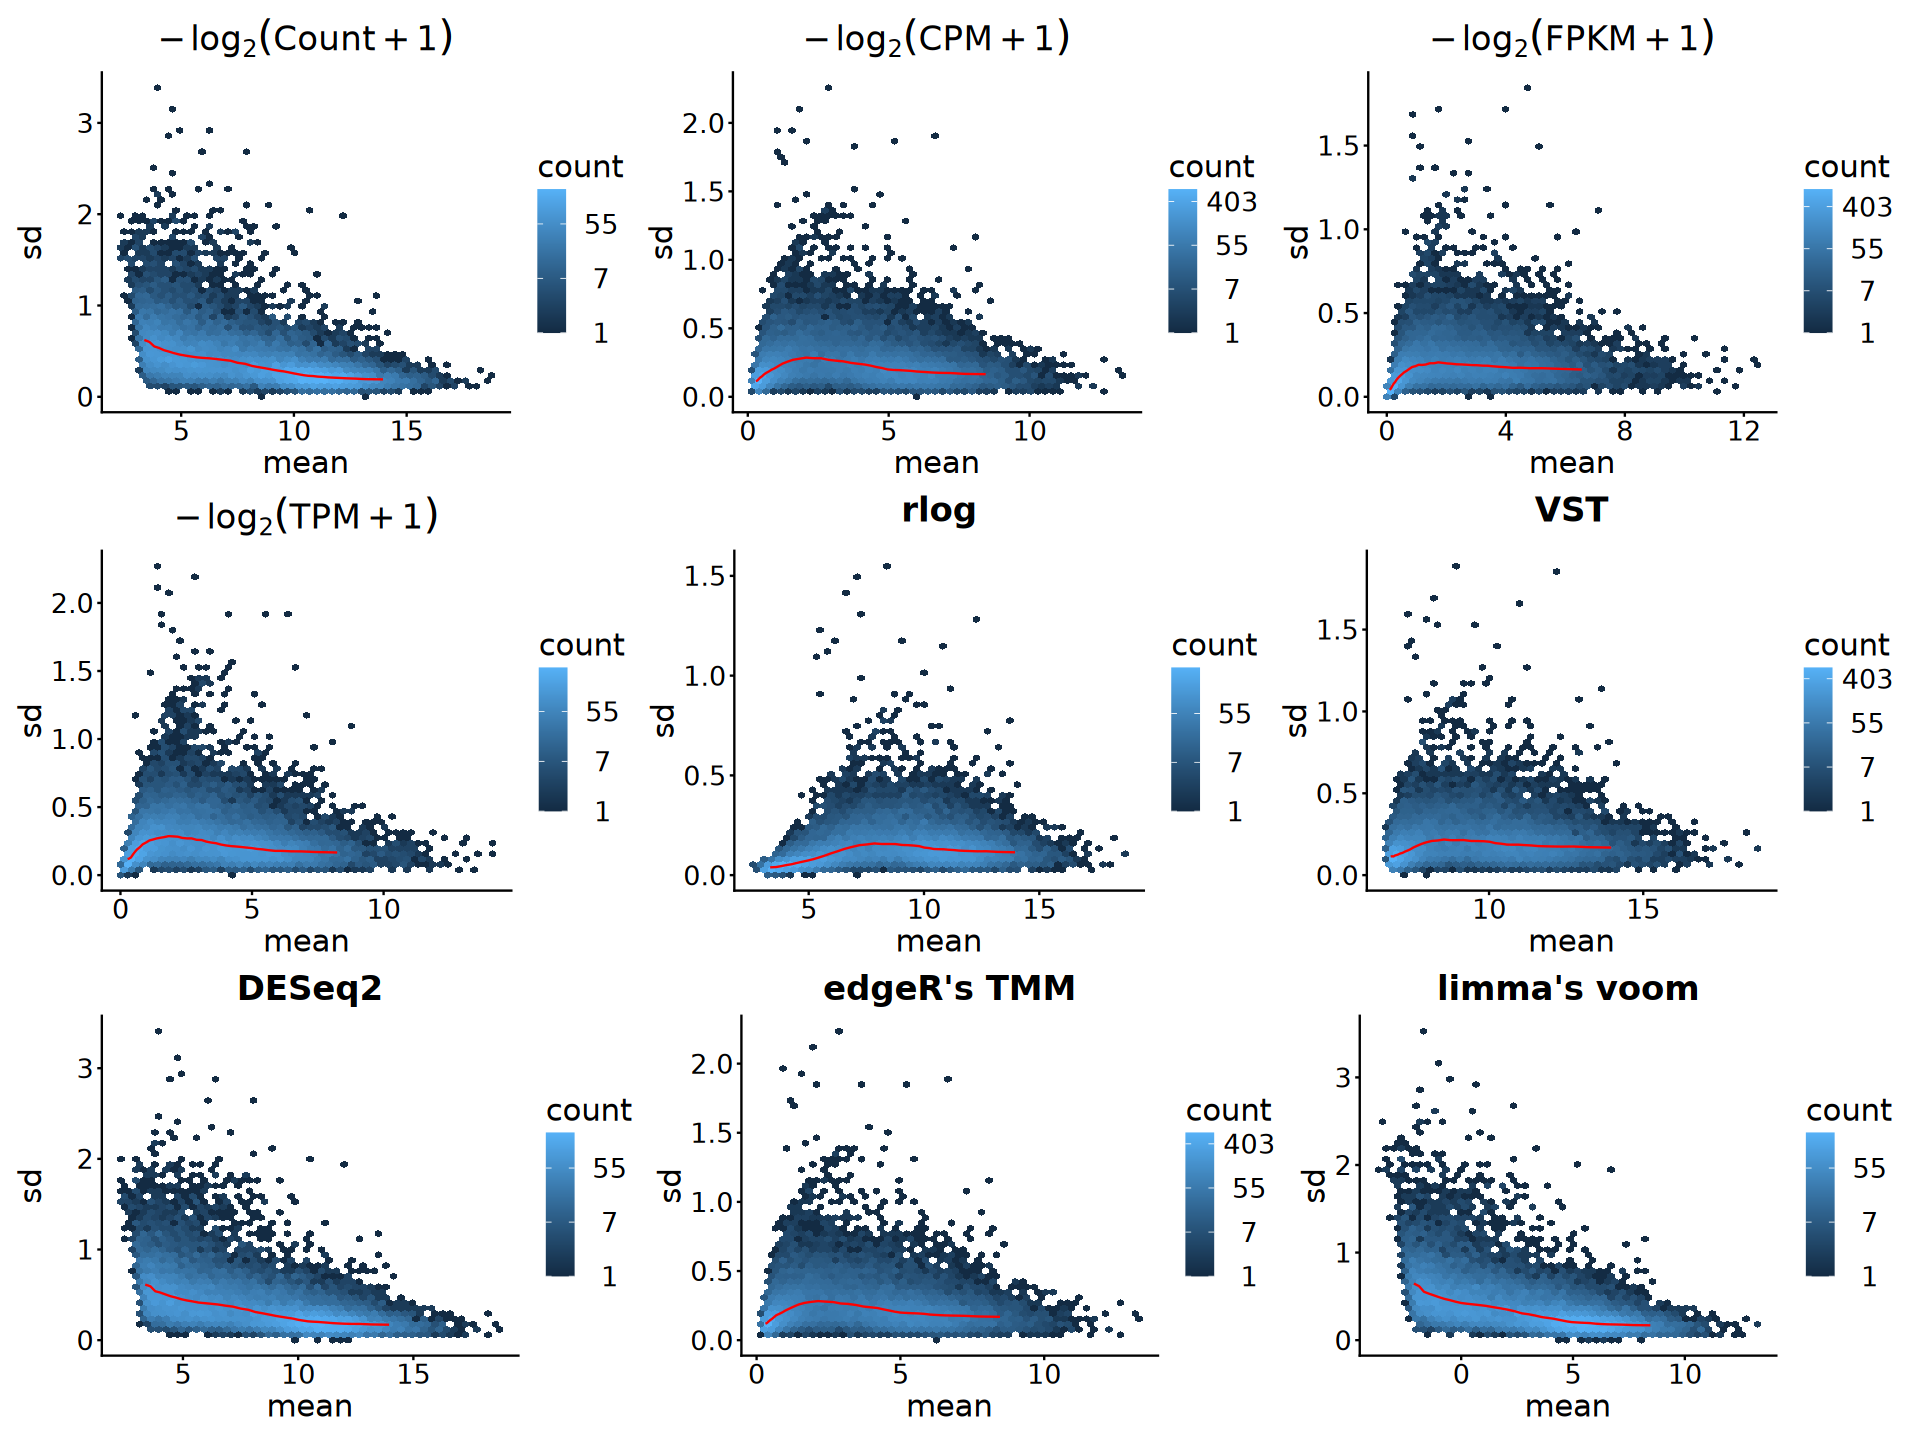

In [41]:
options(repr.plot.width = 16, repr.plot.height = 12)
(p1 + p2 + p3) / (p4 + p5 + p6) / (p7 + p8 + p9)

# 4. Exploration

In [42]:
norm_mat <- log2(tpm + 1)
norm_vs <- assay(rld)

### 1). Overview

In [43]:
plot_df <- colData(eSet) |> as.data.frame() |>
    arrange(Group, Replicate) |> 
    rownames_to_column(var = "Sample") |>
    mutate(
        librarySize = colSums(assay(eSet))[Sample], 
        Sample = gsub("_", "\n", Sample), 
        Sample = factor(Sample, levels = Sample))

plot_df

Sample,Cell,Gene,Group,Replicate,librarySize
<fct>,<chr>,<chr>,<fct>,<fct>,<dbl>
WT rep1,mESC,Ncor2,WT,rep1,48596249
WT rep2,mESC,Ncor2,WT,rep2,50573426
WT rep3,mESC,Ncor2,WT,rep3,42115156
KO rep1,mESC,Ncor2,KO,rep1,43502073
KO rep2,mESC,Ncor2,KO,rep2,43453390
KO rep3,mESC,Ncor2,KO,rep3,46267737


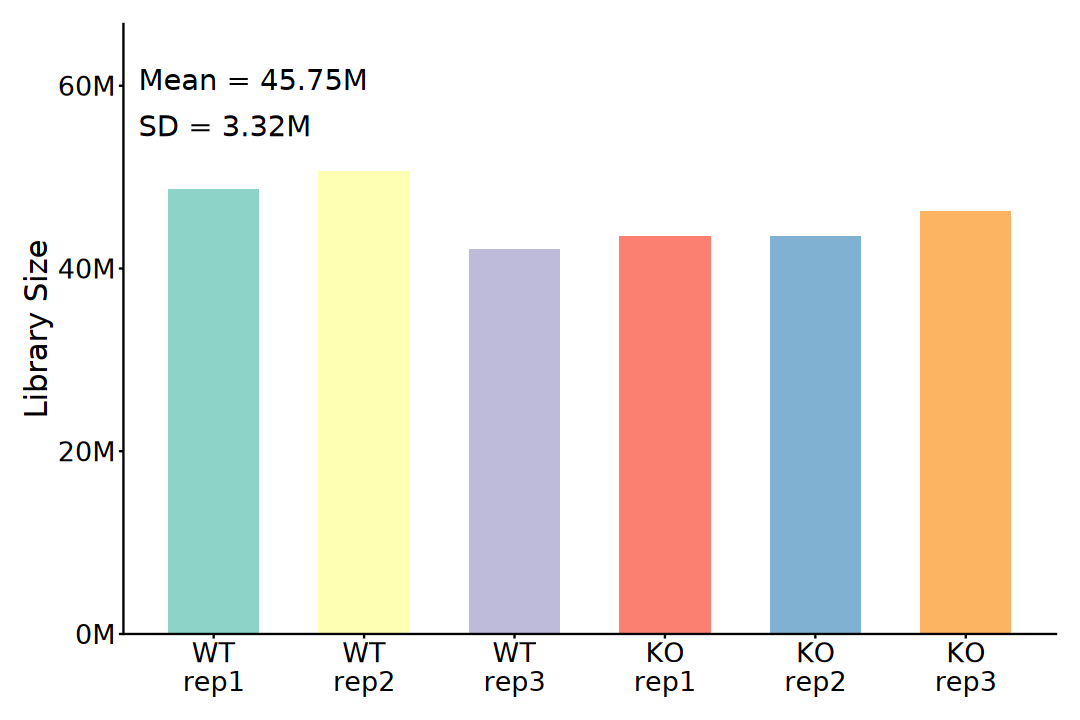

In [44]:
options(repr.plot.width = 9, repr.plot.height = 6)

ggplot(plot_df, aes(x = Sample, y = librarySize)) +
    geom_col(aes(fill = Sample), width = 0.6) +
    annotate(
        geom = "text", x = 0.5, y = max(plot_df$librarySize) * 1.2,
        label = paste0("Mean = ", round(
            mean(plot_df$librarySize) / 1e6 , 2), "M"),
        hjust = 0, size = 6) +
    annotate(
        geom = "text", x = 0.5, y = max(plot_df$librarySize) * 1.1,
        label = paste0("SD = ", round(
            sd(plot_df$librarySize) * 1e-6 , 2), "M"),
        hjust = 0, size = 6) +
    scale_y_continuous(
        labels = scales::label_number(scale = 1e-6, suffix = "M"),
        expand = expansion(mult = c(0, 0.1))) +
    scale_fill_brewer(palette = "Set3") +
    labs(x = NULL, y = "Library Size") +
    theme_classic() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.position = "none",
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

In [45]:
# remotes::install_github("psyteachr/introdataviz")
suppressPackageStartupMessages(library(introdataviz))

Warning message:
"Using the `size` aesthetic with geom_polygon was deprecated in ggplot2 3.4.0.
ℹ Please use the `linewidth` aesthetic instead."


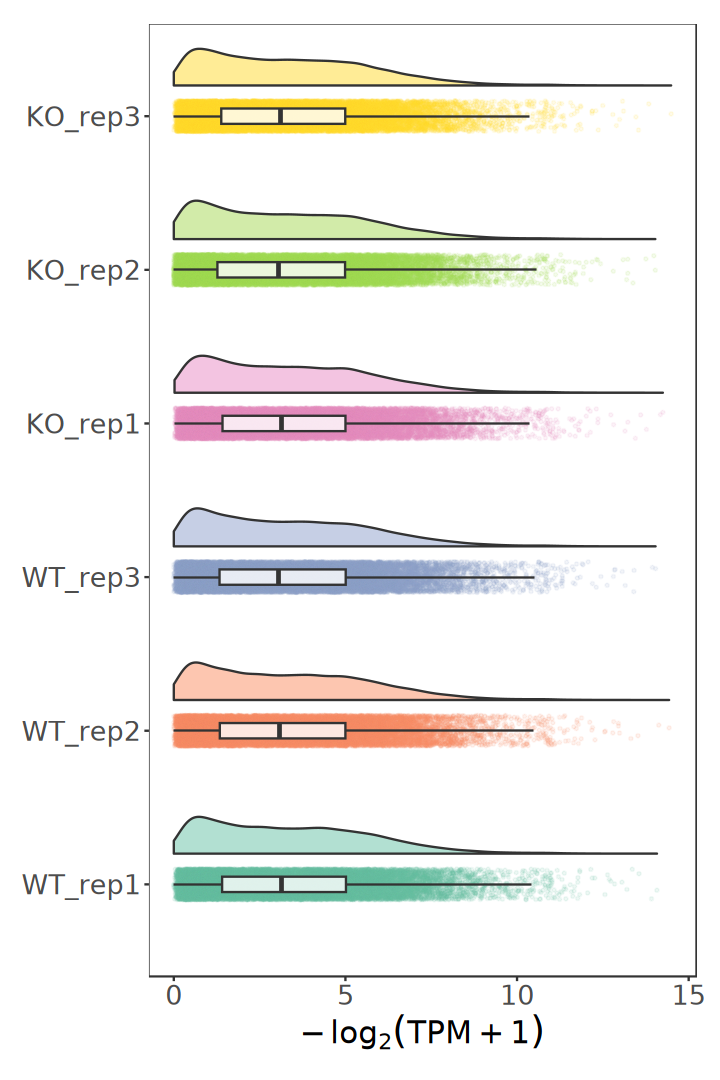

In [46]:
options(repr.plot.width = 6, repr.plot.height = 9)

norm_mat |> as.data.frame() |> 
    pivot_longer(
        cols = everything(), names_to = "Sample", 
        values_to = "Value") |>
    mutate(
        Sample = factor(Sample, levels = colnames(norm_mat))) |>
    ggplot(aes(x = Sample, y = Value)) +
        geom_flat_violin(
            aes(fill = Sample), width = 0.5, alpha = 0.5,
            position = position_nudge(x = 0.2, y = 0)) +
        geom_point(
            aes(color = Sample), size = 0.5, alpha = 0.1,
            position = position_jitter(width = 0.1)) + 
        geom_boxplot(
            width = 0.1, alpha = 0.8, outlier.shape = NA) +
        scale_fill_brewer(palette = "Set2") +
        scale_colour_brewer(palette = "Set2") +
        coord_flip() +
        labs(x = NULL, y = expression(-log[2](TPM+1))) +
        theme_test() +
        theme(
            plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
            plot.margin = unit(c(1, 1, 1, 1), "line"),
            legend.position = "none",
            axis.title = element_text(size = 18), 
            axis.text = element_text(size = 16))

## 2). PCA

In [47]:
top_var_idx <- norm_mat |>
    rowSds() |>
    # (\(m) rowSds(m) / rowMeans2(m))() |> # CV
    tibble::enframe(name = "row", value = "sd") |>
    slice_max(order_by = sd, n = 2000) |>
    pull(row)
# CV can eliminate the bias that "high abundance tends to have large variance".

In [48]:
pca_res <- norm_mat[top_var_idx, ] |> t() |> 
    prcomp(center = TRUE, scale. = FALSE)

per_var <- round(100 * pca_res$sdev^2 / sum(pca_res$sdev^2), 2)

pca_df <- merge(pca_res$x, colData(eSet), by = "row.names")

head(pca_df)

,Row.names,PC1,PC2,PC3,PC4,PC5,PC6,Cell,Gene,Group,Replicate
,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<chr>,<fct>,<fct>
1,KO_rep1,-1.775211,-13.9026975,-14.7906354,15.282705,-0.6309041,-2.539635e-15,mESC,Ncor2,KO,rep1
2,KO_rep2,28.556567,-0.4814882,14.6995651,3.802778,1.7303964,5.911938e-15,mESC,Ncor2,KO,rep2
3,KO_rep3,-2.216468,-22.6243773,-0.3334361,-14.768688,-2.2407996,-3.538836e-15,mESC,Ncor2,KO,rep3
4,WT_rep1,-25.473755,2.7598900,16.1773915,3.824782,3.6207032,1.391942e-14,mESC,Ncor2,WT,rep1
5,WT_rep2,2.595199,15.6445525,-14.3010406,-7.122781,7.6026499,1.332268e-14,mESC,Ncor2,WT,rep2
6,WT_rep3,-1.686333,18.6041205,-1.4518444,-1.018796,-10.0820459,-3.514550e-15,mESC,Ncor2,WT,rep3


In [49]:
p1 <- ggplot(pca_df, aes(PC1, PC2)) +
    geom_point(aes(color = Group, shape = Replicate), size = 5) +
    scale_color_brewer(palette = "Set1") +
    labs(
        title = bquote("PCA for" ~ -log[2](TPM+1)), 
        x = paste0("PC1: ", per_var[1], "% variance"),
        y = paste0("PC2: ", per_var[2], "% variance")) +
    guides(
        color = guide_legend(override.aes = list(size = 5)), 
        shape = guide_legend(override.aes = list(size = 5))) +
    theme_test() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

In [50]:
pca_res <- plotPCA(
    rld, intgroup = c("Group", "Replicate"), 
    ntop = 2000, returnData = TRUE)

per_var <- round(100 * attr(pca_res, "percentVar"))

using ntop=2000 top features by variance



In [51]:
p2 <- ggplot(pca_res, aes(PC1, PC2)) +
    geom_point(aes(color = Group, shape = Replicate), size = 5) +
    scale_color_brewer(palette = "Set1") +
    labs(
        title = "PCA for rlog", 
        x = paste0("PC1: ", per_var[1], "% variance"),
        y = paste0("PC2: ", per_var[2], "% variance")) +
    guides(
        color = guide_legend(override.aes = list(size = 5)), 
        shape = guide_legend(override.aes = list(size = 5))) +
    theme_test() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

In [52]:
# Generalized principal component analysis (GLM-PCA)
# suppressPackageStartupMessages(library(glmpca))
gpca <- glmpca::glmpca(assay(eSet)[top_var_idx, ], L = 2)

gpca_df <- merge(gpca$factors, colData(eSet), by = "row.names")

gpca_df

DataFrame with 6 rows and 7 columns
    Row.names      dim1       dim2        Cell        Gene    Group Replicate
  <character> <numeric>  <numeric> <character> <character> <factor>  <factor>
1     KO_rep1   8.04388  -7.371153        mESC       Ncor2       KO      rep1
2     KO_rep2  17.95698  -0.533098        mESC       Ncor2       KO      rep2
3     KO_rep3  15.37547   6.465711        mESC       Ncor2       KO      rep3
4     WT_rep1 -11.45343  22.382326        mESC       Ncor2       WT      rep1
5     WT_rep2 -14.10471 -17.097518        mESC       Ncor2       WT      rep2
6     WT_rep3 -15.81818  -3.846268        mESC       Ncor2       WT      rep3

In [53]:
p3 <- ggplot(gpca_df, aes(dim1, dim2)) +
    geom_point(aes(color = Group, shape = Replicate), size = 5) +
    scale_color_brewer(palette = "Set1") +
    labs(title = "GLM-PCA for raw count", x = "PC1", y = "PC2") +
    guides(
        color = guide_legend(override.aes = list(size = 5)), 
        shape = guide_legend(override.aes = list(size = 5))) +
    theme_test() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

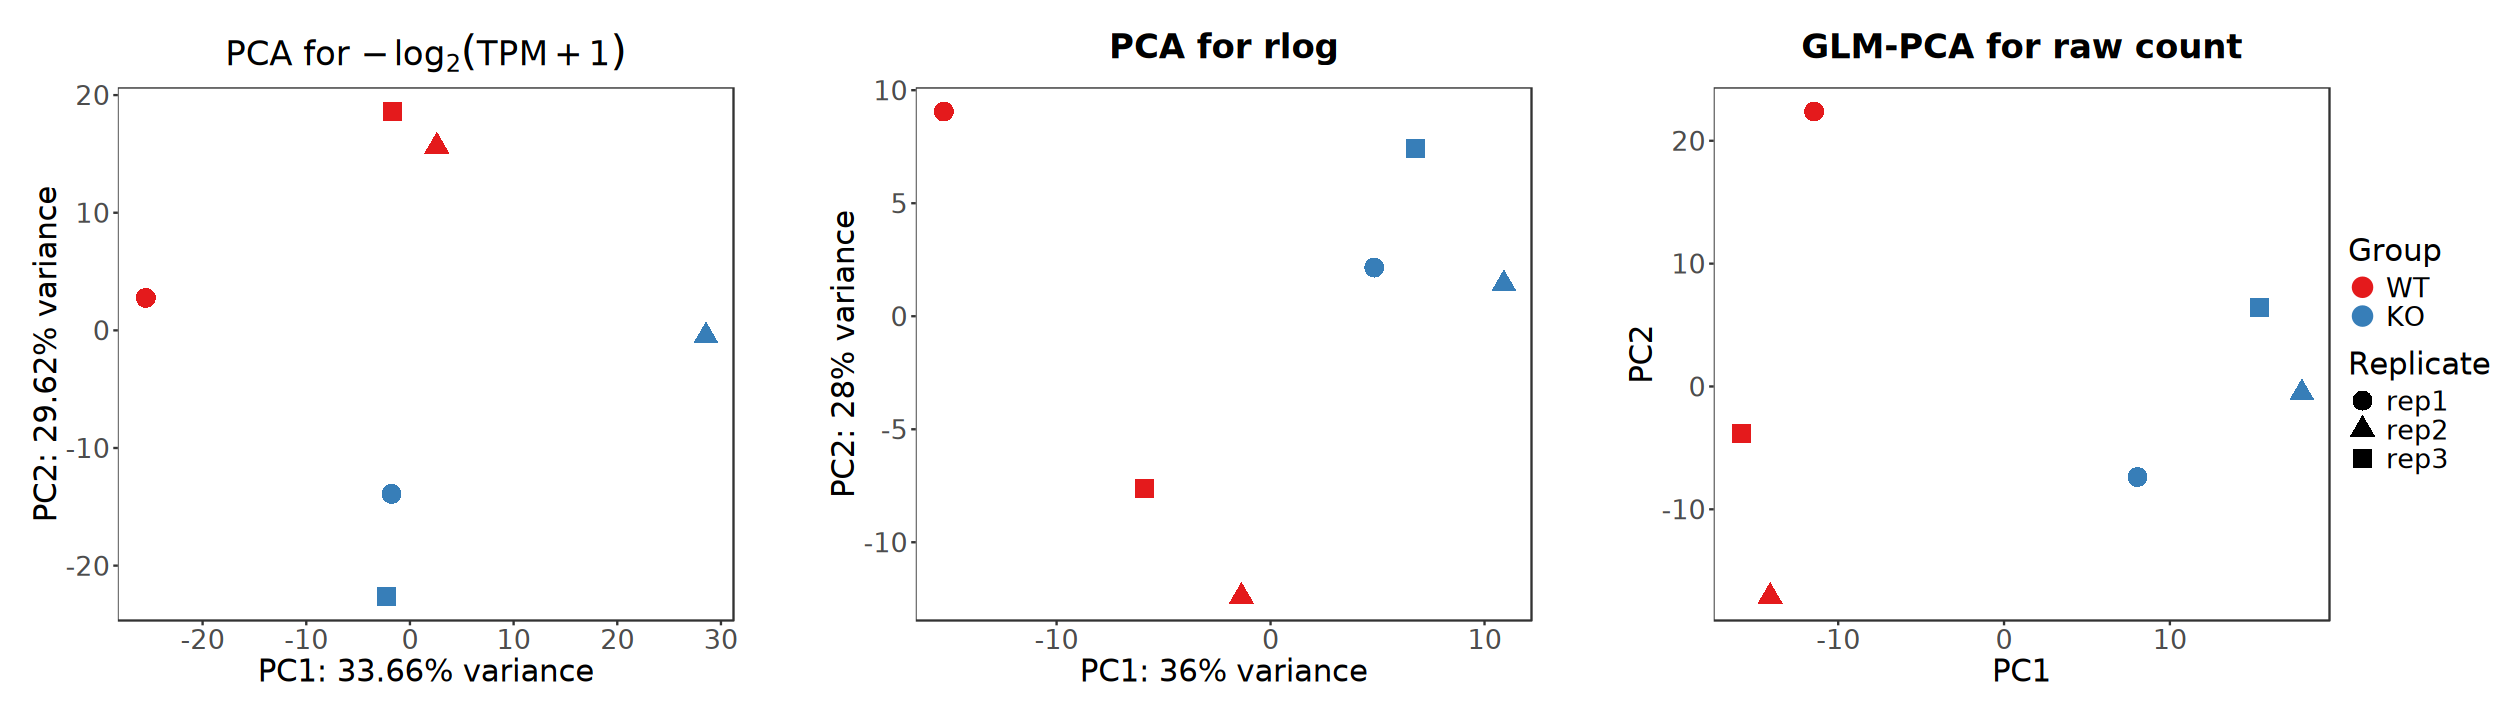

In [54]:
options(repr.plot.width = 21, repr.plot.height = 6)

p1 + plot_spacer() + p2 + plot_spacer() + p3 +
    plot_layout(nrow = 1, guides = "collect", 
                widths = c(1, 0.05, 1, 0.05, 1))

## 3). MDS

> Multidimensional scaling

In [55]:
dist_mat <- norm_vs[top_var_idx, ] |> t() |> dist()

mds <- colData(eSet) |> as.data.frame() |>
    cbind(cmdscale(as.matrix(dist_mat)))

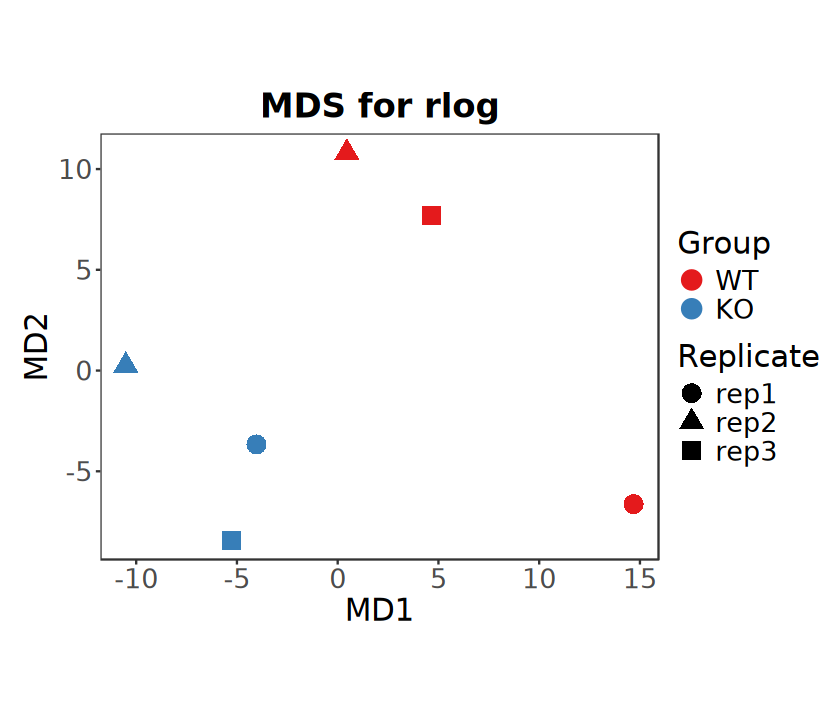

In [56]:
options(repr.plot.width = 7, repr.plot.height = 6)

ggplot(mds, aes(x = `1`, y = `2`)) +
    geom_point(aes(color = Group, shape = Replicate), size = 5) +
    scale_color_brewer(palette = "Set1") +
    coord_fixed() + 
    # ggtitle(bquote("MDS for" ~ -log[2](TPM+1))) + 
    ggtitle("MDS for rlog") + 
    labs(x = "MD1", y = "MD2") +
    guides(
        color = guide_legend(override.aes = list(size = 5)), 
        shape = guide_legend(override.aes = list(size = 5))) +
    theme_test() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

## 4). PCoA

> Principal coordinate analysis

In [57]:
# 1. Calculate Bray-Curtis distance on the transposed count matrix
dist_mat <- norm_vs[top_var_idx, ] |> t() |> 
    vegan::vegdist(method = "bray")

# 2. Run PCoA
pcoa_res <- cmdscale(dist_mat, k = 2, eig = TRUE)

# 3. Prepare data for plot
pcoa_df <- merge(pcoa_res$points, colData(eSet), by = "row.names")

head(pcoa_df)

,Row.names,V1,V2,Cell,Gene,Group,Replicate
,<chr>,<dbl>,<dbl>,<chr>,<chr>,<fct>,<fct>
1,KO_rep1,-0.004396688,0.0002962971,mESC,Ncor2,KO,rep1
2,KO_rep2,-0.012295561,0.0002293905,mESC,Ncor2,KO,rep2
3,KO_rep3,-0.009140657,-0.0079693890,mESC,Ncor2,KO,rep3
4,WT_rep1,0.014300016,-0.0116730456,mESC,Ncor2,WT,rep1
5,WT_rep2,0.003713792,0.0124894978,mESC,Ncor2,WT,rep2
6,WT_rep3,0.007819097,0.0066272492,mESC,Ncor2,WT,rep3


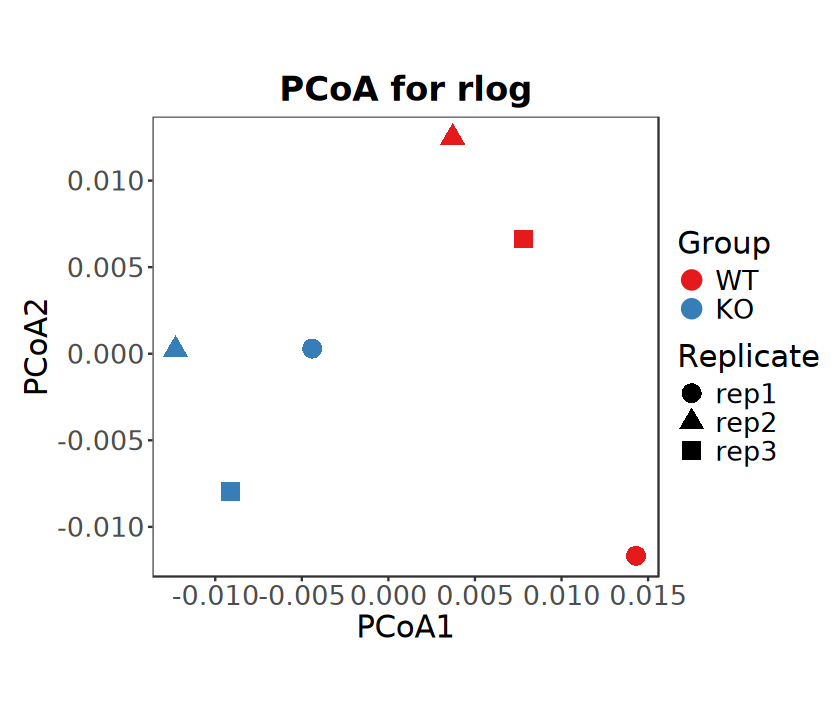

In [58]:
options(repr.plot.width = 7, repr.plot.height = 6)

ggplot(pcoa_df, aes(x = V1, y = V2)) +
    geom_point(aes(color = Group, shape = Replicate), size = 5) +
    scale_color_brewer(palette = "Set1") +
    coord_fixed() + 
    # ggtitle(bquote("PCoA for" ~ -log[2](TPM+1))) + 
    ggtitle("PCoA for rlog") + 
    labs(x = "PCoA1", y = "PCoA2") +
    guides(
        color = guide_legend(override.aes = list(size = 5)), 
        shape = guide_legend(override.aes = list(size = 5))) +
    theme_test() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

## 5). Sample Distance

In [59]:
ac <- colData(eSet) |> as.data.frame() |>
    dplyr::select(Replicate, Group)

In [60]:
group_colors <- setNames(
    scales::brewer_pal(palette = "Set1")(nlevels(eSet$Group)),
    levels(eSet$Group))
replicate_colors <- setNames(
    scales::brewer_pal(palette = "Set2")(nlevels(eSet$Replicate)),
    levels(eSet$Replicate))

anno_colors <- list(
    Group = group_colors,
    Replicate = replicate_colors)

colors <- colorRampPalette(brewer.pal(9, "Blues"))(255)

In [61]:
dist_mat <- norm_vs[top_var_idx, ] |> t() |> dist()

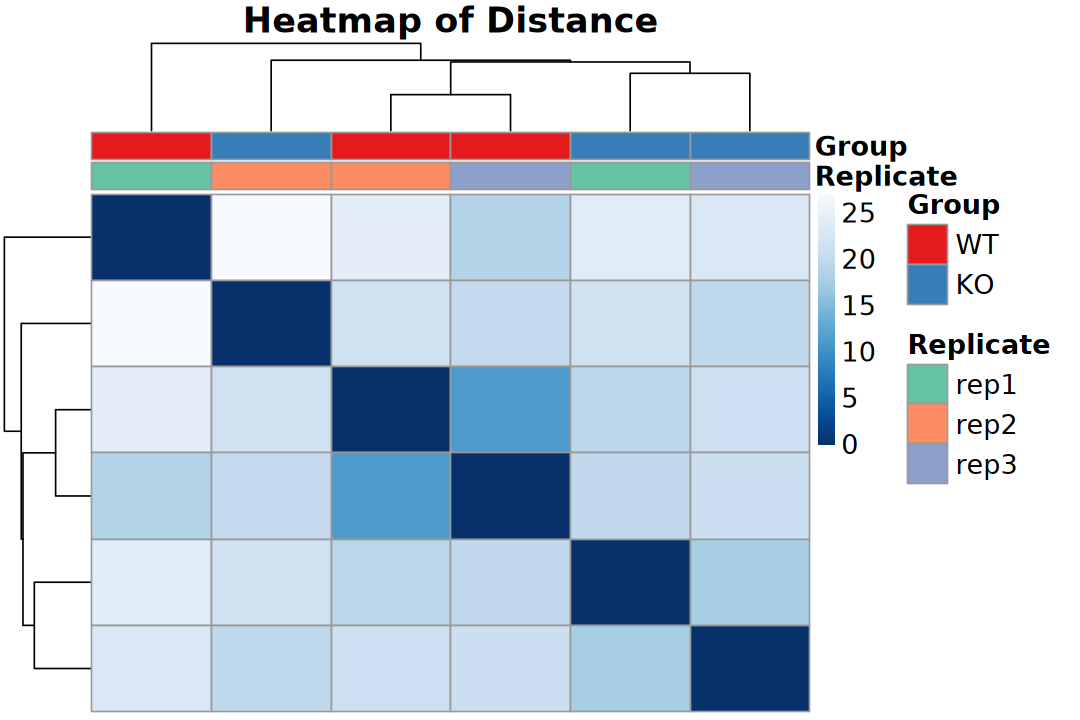

In [62]:
options(repr.plot.width = 9, repr.plot.height = 6)

pheatmap::pheatmap(
    as.matrix(dist_mat),
    clustering_distance_rows = dist_mat,
    clustering_distance_cols = dist_mat,
    annotation_col = ac, col = rev(colors), 
    annotation_colors = anno_colors,
    main = "Heatmap of Distance", fontsize = 16, 
    show_colnames = FALSE, show_rownames = FALSE)

In [63]:
# This measure of dissimilarity between counts also takes the inherent variance structure 
# of counts into consideration when calculating the distances between samples. 
# The PoissonDistance function takes the original count matrix (not normalized) with samples
# as rows instead of columns, so we need to transpose the counts in dds.
# Calculating sample distances is to use the Poisson Distance

# suppressPackageStartupMessages(library(PoiClaClu))
poisd <- assay(eSet)[top_var_idx, ] |> t() |> 
    PoiClaClu::PoissonDistance()

dist_mat <- poisd$dd |> as.matrix()

colnames(dist_mat) <- colnames(eSet)

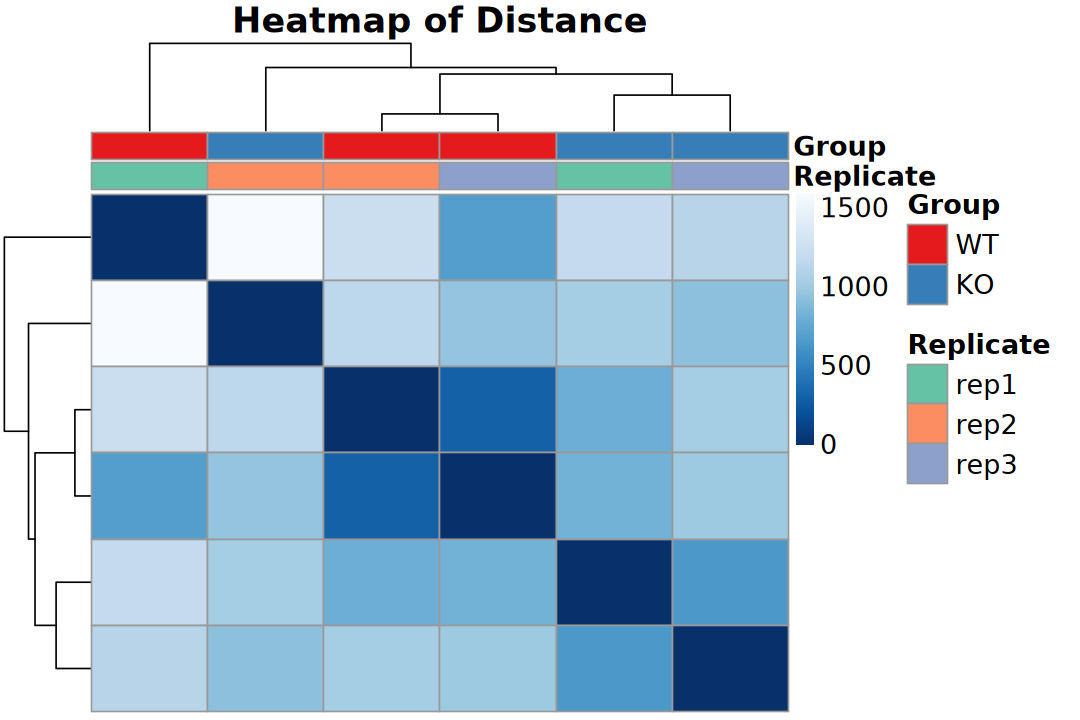

In [64]:
options(repr.plot.width = 9, repr.plot.height = 6)

pheatmap::pheatmap(
    as.matrix(dist_mat),
    clustering_distance_rows = poisd$dd,
    clustering_distance_cols = poisd$dd,
    annotation_col = ac, col = rev(colors), 
    annotation_colors = anno_colors,
    main = "Heatmap of Distance", fontsize = 16, 
    show_colnames = FALSE, show_rownames = FALSE)

## 6). Sample Correlation

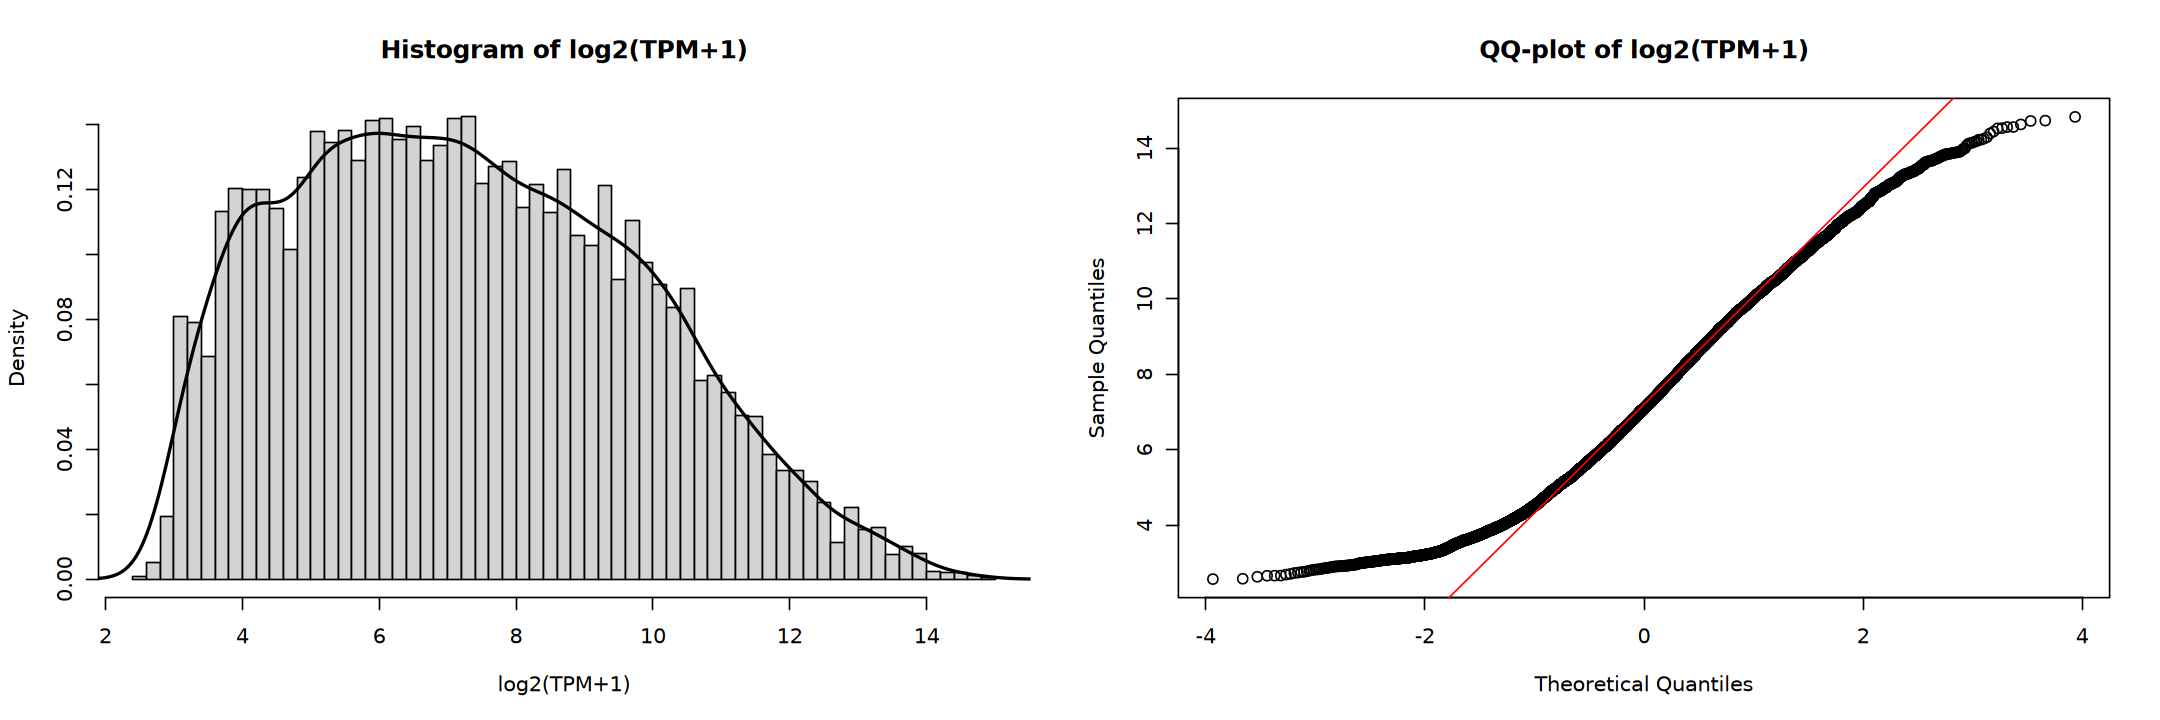

In [65]:
options(repr.plot.width = 18, repr.plot.height = 6)

par(mfrow = c(1, 2))
hist(
    norm_vs[top_var_idx, ], breaks = 50, probability = TRUE, 
    main = "Histogram of log2(TPM+1)", xlab = "log2(TPM+1)")
lines(density(norm_vs[top_var_idx, ]), lwd = 2)

qqnorm(
    norm_vs[top_var_idx, ], 
    main = "QQ-plot of log2(TPM+1)")
qqline(
    norm_vs[top_var_idx, ], col = "red")

par(mfrow = c(1, 1))

In [66]:
# cor_mat <- cor(norm_vs[top_var_idx, ], method = "pearson")
cor_mat <- cor(norm_vs[top_var_idx, ], method = "spearman")

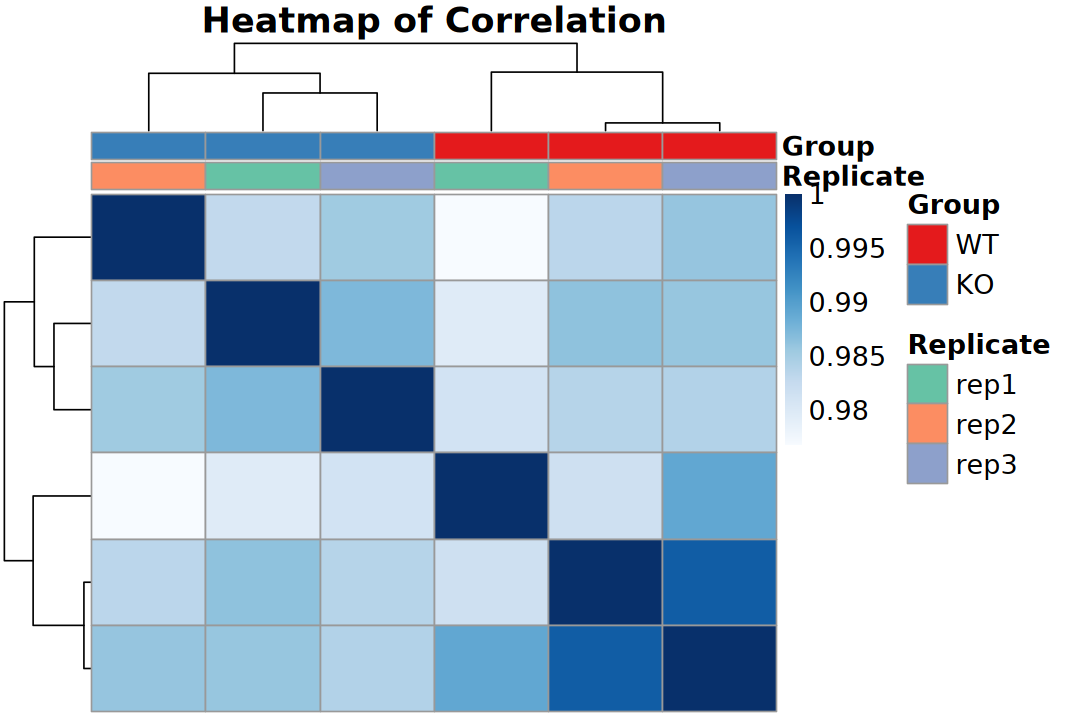

In [67]:
options(repr.plot.width = 9, repr.plot.height = 6)

pheatmap::pheatmap(
    as.matrix(cor_mat), 
    clustering_distance_rows = "correlation",
    clustering_distance_cols = "correlation",
    annotation_col = ac, col = colors, 
    annotation_colors = anno_colors,
    main = "Heatmap of Correlation", fontsize = 16, 
    show_colnames = FALSE, show_rownames = FALSE)

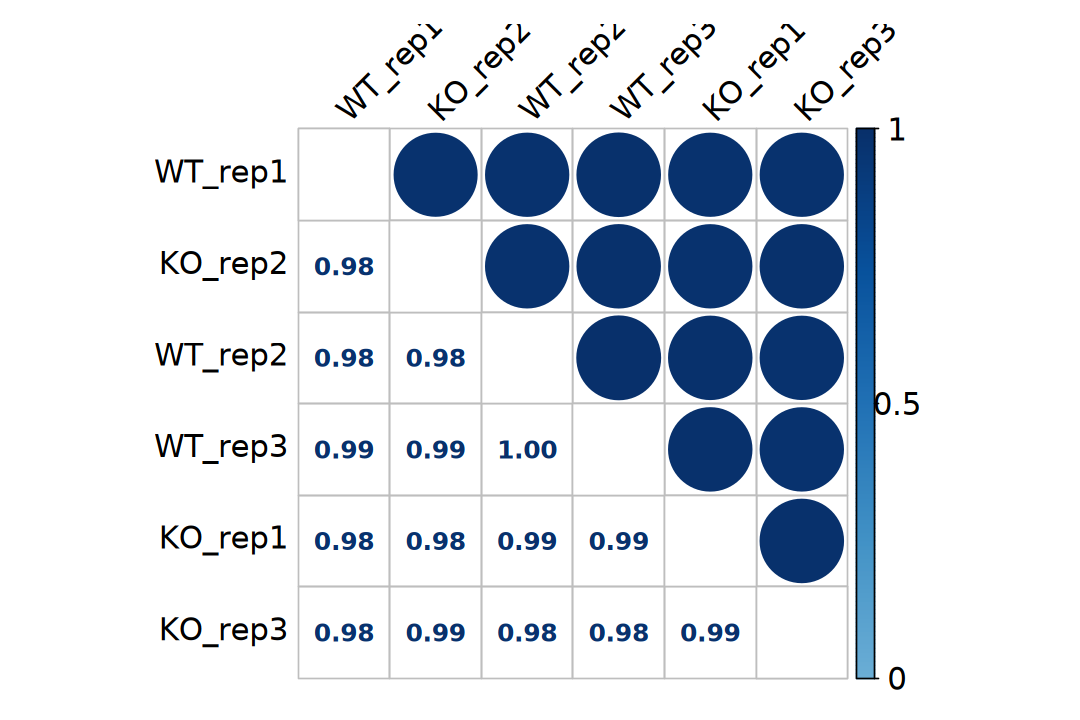

In [68]:
# suppressPackageStartupMessages(library(corrplot))
options(repr.plot.width = 9, repr.plot.height = 6)

corrplot::corrplot.mixed(
    cor_mat, order = 'hclust', upper.col = colors, 
    tl.pos = "lt", tl.cex = 1.5, tl.col = "black", tl.srt = 45, 
    number.cex = 1.2, diag = "n", col.lim = c(0, 1), 
    lower.col = colors, rect.col = "grey50", 
    cl.cex = 1.5, cl.length = 3, mar = c(1, 0, 1, 0))

## 7). Heatmap

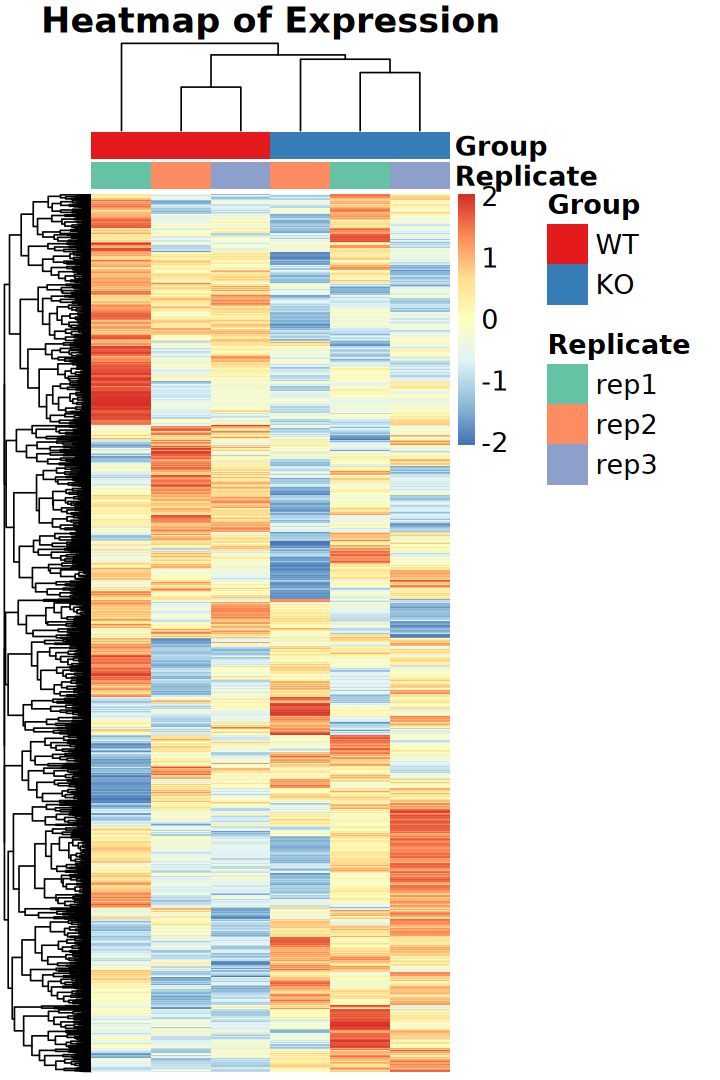

In [69]:
options(repr.plot.width = 6, repr.plot.height = 9)

pheatmap::pheatmap(
    norm_mat[top_var_idx, ], scale = "row", 
    annotation_col = ac, 
    annotation_colors = anno_colors, 
    main = "Heatmap of Expression", fontsize = 16, 
    show_colnames = FALSE, show_rownames = FALSE)

# 5. DEGs

In [70]:
logfc_cutoff <- log2(1.2)
p_cutoff <- 0.05

## 1). DESeq2

> median of ratios for normalization

In [71]:
design(dds)

~Group

In [72]:
dds <- DESeq(dds)

using pre-existing size factors

estimating dispersions

gene-wise dispersion estimates

mean-dispersion relationship

final dispersion estimates

fitting model and testing



In [73]:
resultsNames(dds)

[1] "Intercept"      "Group_KO_vs_WT"

### a). Standard

In [74]:
res <- results(dds, lfcThreshold = logfc_cutoff, alpha = p_cutoff)
# res <- results(
#     dds, name = "Group_KO_vs_WT", 
#     lfcThreshold = logfc_cutoff, alpha = p_cutoff)
# res <- results(
#     dds, contrast = c("Group", "KO", "WT"), 
#     lfcThreshold = logfc_cutoff, alpha = p_cutoff)
summary(res)


out of 19304 with nonzero total read count
adjusted p-value < 0.05
LFC > 0.26 (up)    : 63, 0.33%
LFC < -0.26 (down) : 54, 0.28%
outliers [1]       : 6, 0.031%
low counts [2]     : 0, 0%
(mean count < 6)
[1] see 'cooksCutoff' argument of ?results
[2] see 'independentFiltering' argument of ?results



In [75]:
deseq2_result <- res |> as.data.frame() |> 
    rownames_to_column("gene_id") |>
    dplyr::rename(logFC = log2FoldChange) |>
    mutate(
        result = case_when(
            padj < p_cutoff & logFC >  logfc_cutoff ~ "Up",
            padj < p_cutoff & logFC < -logfc_cutoff ~ "Down",
            TRUE ~ "NS") |> 
            factor(levels = c("Up", "Down", "NS"))) |>
    left_join(
        rowData(dds) |> 
            as.data.frame() |> 
            dplyr::select(symbol, type, basepairs) |>
            rownames_to_column("gene_id"), 
        by = "gene_id") |>
    column_to_rownames("gene_id")

table(deseq2_result$result)
head(deseq2_result)


   Up  Down    NS 
   63    54 19187 

,baseMean,logFC,lfcSE,stat,pvalue,padj,result,symbol,type,basepairs
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>,<chr>,<chr>,<int>
ENSMUSG00000051951.5,13.18940,-0.21160827,0.8754287,-0.2417196,8.172681e-01,0.999925666,NS,Xkr4,protein_coding,6094
ENSMUSG00000025902.13,86.27863,2.77719331,0.5616502,4.9447032,3.826969e-06,0.002781235,Up,Sox17,protein_coding,4772
ENSMUSG00000098104.1,11.28137,-0.36123917,0.6965997,-0.5185749,6.290242e-01,0.999925666,NS,Gm6085,processed_pseudogene,1470
ENSMUSG00000103922.1,53.29621,0.42698027,0.3491199,1.2230189,3.433737e-01,0.999925666,NS,Gm6123,processed_pseudogene,1069
ENSMUSG00000033845.13,9322.26731,0.04927733,0.1560701,0.3157383,9.372884e-01,0.999925666,NS,Mrpl15,protein_coding,8487
ENSMUSG00000102275.1,184.83478,0.27259232,0.2264336,1.2038509,4.921685e-01,0.999925666,NS,Gm37144,TEC,1150


### b). LFC Shrink

> Shrinkage of effect size (LFC estimates) is useful for visualization and ranking of genes.

In [76]:
res_lfc <- lfcShrink(
    dds, coef = "Group_KO_vs_WT", type = "apeglm")
summary(res_lfc)

using 'apeglm' for LFC shrinkage. If used in published research, please cite:
    Zhu, A., Ibrahim, J.G., Love, M.I. (2018) Heavy-tailed prior distributions for
    sequence count data: removing the noise and preserving large differences.
    Bioinformatics. https://doi.org/10.1093/bioinformatics/bty895




out of 19304 with nonzero total read count
adjusted p-value < 0.1
LFC > 0 (up)       : 630, 3.3%
LFC < 0 (down)     : 694, 3.6%
outliers [1]       : 6, 0.031%
low counts [2]     : 4117, 21%
(mean count < 34)
[1] see 'cooksCutoff' argument of ?results
[2] see 'independentFiltering' argument of ?results



In [77]:
deseq2_lfc_result <- res_lfc |> as.data.frame() |> 
    rownames_to_column("gene_id") |>
    dplyr::rename(logFC = log2FoldChange) |>
    mutate(
        result = case_when(
            padj < p_cutoff & logFC >  logfc_cutoff ~ "Up",
            padj < p_cutoff & logFC < -logfc_cutoff ~ "Down",
            TRUE ~ "NS") |> 
            factor(levels = c("Up", "Down", "NS"))) |>
    left_join(
        rowData(dds) |> 
            as.data.frame() |> 
            dplyr::select(symbol, type, basepairs) |>
            rownames_to_column("gene_id"), 
        by = "gene_id") |>
    column_to_rownames("gene_id")

table(deseq2_lfc_result$result)
head(deseq2_lfc_result)


   Up  Down    NS 
  405   422 18477 

,baseMean,logFC,lfcSE,pvalue,padj,result,symbol,type,basepairs
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>,<chr>,<chr>,<int>
ENSMUSG00000051951.5,13.18940,-0.006785555,0.1579169,8.089974e-01,NA,NS,Xkr4,protein_coding,6094
ENSMUSG00000025902.13,86.27863,2.531390296,0.5917933,7.625996e-07,0.000160792,Up,Sox17,protein_coding,4772
ENSMUSG00000098104.1,11.28137,-0.018170668,0.1576987,6.040572e-01,NA,NS,Gm6085,processed_pseudogene,1470
ENSMUSG00000103922.1,53.29621,0.082439235,0.1702760,2.213226e-01,0.553616352,NS,Gm6123,processed_pseudogene,1069
ENSMUSG00000033845.13,9322.26731,0.025225779,0.1128309,7.522011e-01,0.913606299,NS,Mrpl15,protein_coding,8487
ENSMUSG00000102275.1,184.83478,0.103021212,0.1568085,2.286472e-01,0.562573248,NS,Gm37144,TEC,1150


### Evaluate DEGs

In [78]:
suppressPackageStartupMessages(library(ggVennDiagram))

In [79]:
genes_up <- list(
    raw = deseq2_result |> filter(result == "Up") |> 
        pull(symbol) |> unique(),
    lfc = deseq2_lfc_result |> filter(result == "Up") |> 
        pull(symbol) |> unique())

genes_down <- list(
    raw = deseq2_result |> filter(result == "Down") |> 
        pull(symbol) |> unique(),
    lfc = deseq2_lfc_result |> filter(result == "Down") |> 
        pull(symbol) |> unique())

In [80]:
p1 <- ggVennDiagram(
    genes_up, set_color = "grey", set_size = 6, 
    label_color = "firebrick", label_size = 5) +
    scale_fill_distiller(palette = "Reds", direction = 1)

p2 <- ggVennDiagram(
    genes_down, set_color = "grey", set_size = 6, 
    label_color = "firebrick", label_size = 5) +
    scale_fill_distiller(palette = "Reds", direction = 1)

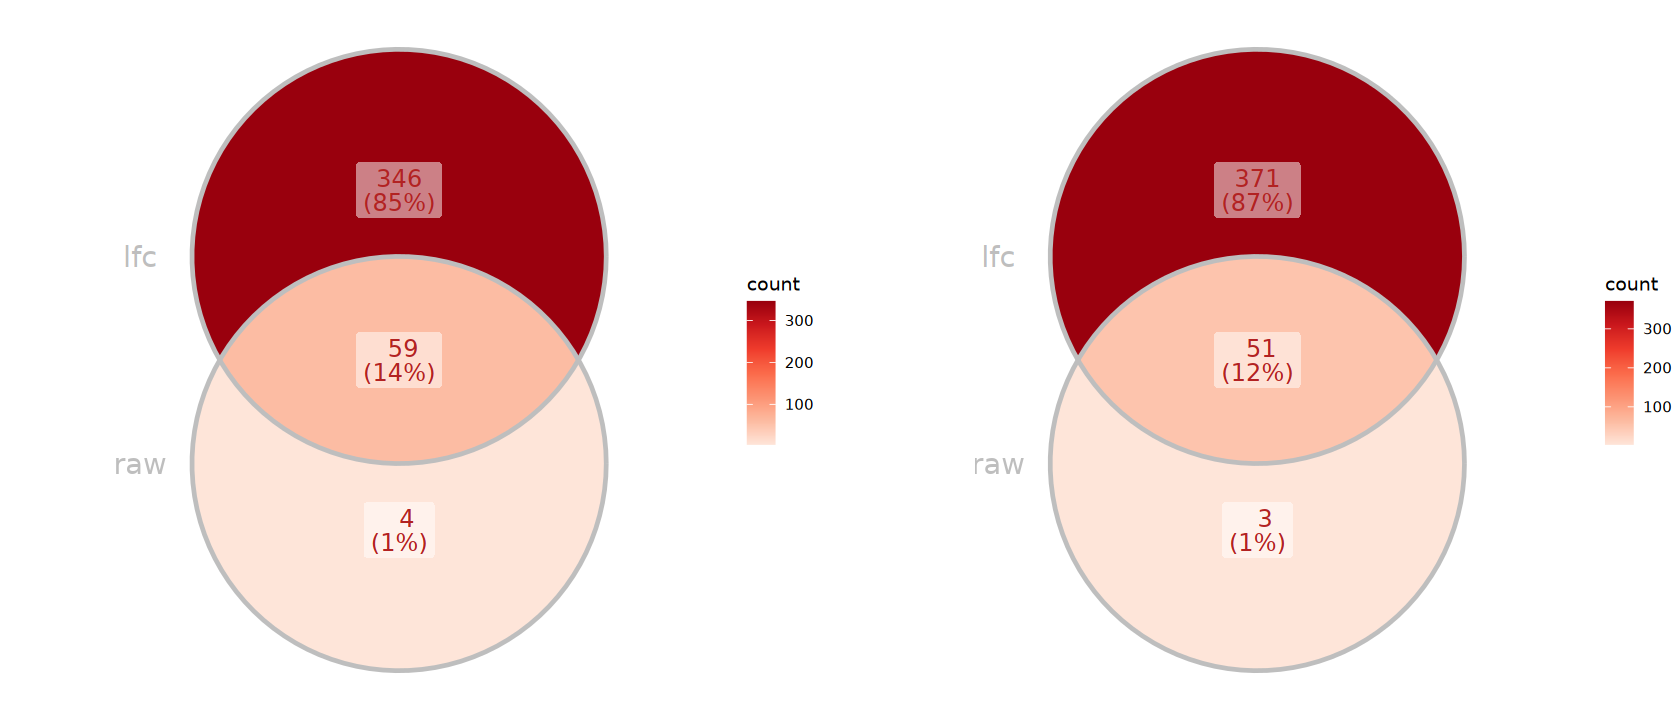

In [81]:
options(repr.plot.width = 14, repr.plot.height = 6)

p1 + plot_spacer() + p2 +
    plot_layout(nrow = 1, widths = c(1, 0.05, 1))

## 2). edgeR

> Trimmed Mean of M-values (TMM)

| Pipeline | Advantages | Application | Estimating dispersions | Fitting model | Testing methods | Notes |
| - | - | - | - | - | - | - |
| Classic pipeline (edgeR v1) | - | Single factor design | quantile-adjusted conditional maximum likelihood (qCML) method | Negative binomial model | Exact test (like Fisher’s exact test) | - |
| Negative binomial GLM framework (edgeR v2) | - | Multiple factors design | Cox-Reid profile-adjusted likelihood (CR) method | Negative binomial - Generalized linear model (NB GLM) | Likelihood ratio test (LRT) | - |
| Quasi-likelihood pipeline (edgeR v3) | Robustness and highly reliable false discovery rate (FDR) control | Multiple factors design | Cox-Reid profile-adjusted likelihood (CR) method | only the trended NB dispersions are used in fitting the QL GLM | Quasi-likelihood F-test (QLF) | - |
| Quasi-likelihood pipeline (edgeR v4) | Robustness and highly reliable false discovery rate (FDR) control | Multiple factors design | Estimates a constant NB dispersion based on the most highly expressed genes | only the trended NB dispersions are used in fitting the QL GLM | Quasi-likelihood F-test (QLF) | Default and Recommended approach in edgeR |

### a). Classic pipeline

In [82]:
dgel_classic <- estimateDisp(dgel)
# # 1. Estimate common dispersion
# dgel <- estimateCommonDisp(dgel)
# # 2. Estimate tagwise dispersions
# dgel <- estimateTagwiseDisp(dgel)

Using classic mode.



In [83]:
# exact test
et <- exactTest(dgel_classic, pair = c("WT", "KO"))

In [84]:
edger_classic_result <- topTags(et, n = Inf) |> 
    as.data.frame() |> 
    dplyr::rename(padj = FDR, pvalue = PValue) |>
    mutate(
        result = case_when(
            padj < p_cutoff & logFC >  logfc_cutoff ~ "Up",
            padj < p_cutoff & logFC < -logfc_cutoff ~ "Down",
            TRUE ~ "NS") |> 
            factor(levels = c("Up", "Down", "NS")))

table(edger_classic_result$result)
head(edger_classic_result)


   Up  Down    NS 
  275   235 18544 

,symbol,type,basepairs,logFC,logCPM,pvalue,padj,result
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>
ENSMUSG00000061524.8,Zic2,protein_coding,2880,-1.872500,5.151226,1.410494e-25,2.687554e-21,Down
ENSMUSG00000022619.5,Mapk8ip2,protein_coding,5700,-2.405883,3.301872,4.192435e-20,3.994132e-16,Down
ENSMUSG00000041703.7,Zic5,protein_coding,4889,-1.427684,5.206938,1.838061e-19,1.167414e-15,Down
ENSMUSG00000075122.5,Cd80,protein_coding,3703,1.781376,3.396556,5.639152e-13,2.686210e-09,Up
ENSMUSG00000030246.11,Ldhb,protein_coding,1570,-1.159757,6.133879,2.404130e-12,9.161658e-09,Down
ENSMUSG00000040187.15,Arntl2,protein_coding,5691,-1.963244,2.360473,6.210228e-12,1.972161e-08,Down


### b). Negative binomial GLM framework

In [85]:
design <- model.matrix(~ group, data = dgel$samples) # include intercept
design

,(Intercept),groupKO
WT_rep1,1,0
WT_rep2,1,0
WT_rep3,1,0
KO_rep1,1,1
KO_rep2,1,1
KO_rep3,1,1


In [86]:
dgel_nbglm <- estimateDisp(dgel, design)
# # Estimate common dispersion
# dgel <- estimateGLMCommonDisp(dge, design)
# # Estimate trended dispersions
# dgel <- estimateGLMTrendedDisp(dgel, design)
# # Estimate tagwise dispersions
# dgel <- estimateGLMTagwiseDisp(dgel, design)

In [87]:
# likelihood ratio test
fit <- glmFit(dgel_nbglm, design)
lrt <- glmLRT(fit, coef = 2)

In [88]:
edger_glm_lrt_result <- topTags(lrt, n = Inf) |>
    as.data.frame() |> 
    dplyr::rename(padj = FDR, pvalue = PValue) |>
    mutate(
        result = case_when(
            padj < p_cutoff & logFC >  logfc_cutoff ~ "Up",
            padj < p_cutoff & logFC < -logfc_cutoff ~ "Down",
            TRUE ~ "NS") |> 
            factor(levels = c("Up", "Down", "NS")))

table(edger_glm_lrt_result$result)
head(edger_glm_lrt_result)


   Up  Down    NS 
  292   241 18521 

,symbol,type,basepairs,logFC,logCPM,LR,pvalue,padj,result
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>
ENSMUSG00000061524.8,Zic2,protein_coding,2880,-1.872500,5.151226,108.77746,1.815689e-25,3.459615e-21,Down
ENSMUSG00000022619.5,Mapk8ip2,protein_coding,5700,-2.405883,3.301875,84.82091,3.266512e-20,3.112006e-16,Down
ENSMUSG00000041703.7,Zic5,protein_coding,4889,-1.427684,5.206938,81.17917,2.061531e-19,1.309347e-15,Down
ENSMUSG00000075122.5,Cd80,protein_coding,3703,1.781376,3.396555,52.31702,4.722634e-13,2.249627e-09,Up
ENSMUSG00000030246.11,Ldhb,protein_coding,1570,-1.159757,6.133879,49.17312,2.343403e-12,8.930239e-09,Down
ENSMUSG00000040187.15,Arntl2,protein_coding,5691,-1.963242,2.360478,47.50803,5.477906e-12,1.739600e-08,Down


### c). Quasi-likelihood pipeline (edgeR v3)

In [89]:
design <- model.matrix(~ group, data = dgel$samples) # include intercept

In [90]:
dgel_nbglm <- estimateDisp(dgel, design)

In [91]:
# quasi-likelihood (QL) F-test
fit <- glmQLFit(dgel_nbglm, design)
qlf <- glmQLFTest(fit, coef = 2)

In [92]:
edger_glm_qlf_result <- topTags(qlf, n = Inf) |>
    as.data.frame() |> 
    dplyr::rename(padj = FDR, pvalue = PValue) |>
    mutate(
        result = case_when(
            padj < p_cutoff & logFC >  logfc_cutoff ~ "Up",
            padj < p_cutoff & logFC < -logfc_cutoff ~ "Down",
            TRUE ~ "NS") |> 
            factor(levels = c("Up", "Down", "NS")))

table(edger_glm_qlf_result$result)
head(edger_glm_qlf_result)


   Up  Down    NS 
    0     3 19051 

,symbol,type,basepairs,logFC,logCPM,F,pvalue,padj,result
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>
ENSMUSG00000061524.8,Zic2,protein_coding,2880,-1.872327,5.151226,165.35386,8.225845e-07,0.01302362,Down
ENSMUSG00000041703.7,Zic5,protein_coding,4889,-1.427861,5.206938,139.15575,1.638632e-06,0.01302362,Down
ENSMUSG00000022619.5,Mapk8ip2,protein_coding,5700,-2.405271,3.301875,131.53214,2.050534e-06,0.01302362,Down
ENSMUSG00000040187.15,Arntl2,protein_coding,5691,-1.959204,2.360478,84.71422,1.147400e-05,0.05025241,NS
ENSMUSG00000075122.5,Cd80,protein_coding,3703,1.781980,3.396555,81.69300,1.318684e-05,0.05025241,NS
ENSMUSG00000030246.11,Ldhb,protein_coding,1570,-1.159777,6.133879,71.56961,2.185142e-05,0.06939284,NS


### d). Quasi-likelihood pipeline (edgeR v4)

In [93]:
design <- model.matrix(~ group, data = dgel$samples) # include intercept

In [94]:
# quasi-likelihood (QL) F-test
fit <- glmQLFit(dgel, design)
qlf <- glmQLFTest(fit, coef = 2)

In [95]:
edger_glm_qlf_v4_result <- topTags(qlf, n = Inf) |>
    as.data.frame() |> 
    dplyr::rename(padj = FDR, pvalue = PValue) |>
    mutate(
        result = case_when(
            padj < p_cutoff & logFC >  logfc_cutoff ~ "Up",
            padj < p_cutoff & logFC < -logfc_cutoff ~ "Down",
            TRUE ~ "NS") |> 
            factor(levels = c("Up", "Down", "NS")))

table(edger_glm_qlf_v4_result$result)
head(edger_glm_qlf_v4_result)


   Up  Down    NS 
    0     3 19051 

,symbol,type,basepairs,logFC,logCPM,F,pvalue,padj,result
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>
ENSMUSG00000061524.8,Zic2,protein_coding,2880,-1.872229,5.151235,164.46906,8.353963e-07,0.01340790,Down
ENSMUSG00000041703.7,Zic5,protein_coding,4889,-1.427977,5.206950,139.30504,1.622467e-06,0.01340790,Down
ENSMUSG00000022619.5,Mapk8ip2,protein_coding,5700,-2.405205,3.301959,130.39256,2.111037e-06,0.01340790,Down
ENSMUSG00000040187.15,Arntl2,protein_coding,5691,-1.958440,2.360589,85.45620,1.104672e-05,0.05176460,NS
ENSMUSG00000075122.5,Cd80,protein_coding,3703,1.782211,3.396523,80.97343,1.358366e-05,0.05176460,NS
ENSMUSG00000030246.11,Ldhb,protein_coding,1570,-1.159788,6.133880,71.63031,2.169290e-05,0.06888943,NS


### Evaluate DEGs

In [96]:
suppressPackageStartupMessages(library(ggVennDiagram))

In [97]:
genes_up <- list(
    classic = edger_classic_result |> filter(result == "Up") |> 
        pull(symbol) |> unique(),
    glm_lrt = edger_glm_lrt_result |> filter(result == "Up") |> 
        pull(symbol) |> unique(),
    glm_qlf = edger_glm_qlf_result |> filter(result == "Up") |> 
        pull(symbol) |> unique(),
    glm_v4 = edger_glm_qlf_v4_result |> filter(result == "Up") |> 
        pull(symbol) |> unique())

genes_down <- list(
    classic = edger_classic_result |> filter(result == "Down") |> 
        pull(symbol) |> unique(),
    glm_lrt = edger_glm_lrt_result |> filter(result == "Down") |> 
        pull(symbol) |> unique(),
    glm_qlf = edger_glm_qlf_result |> filter(result == "Down") |> 
        pull(symbol) |> unique(),
    glm_v4 = edger_glm_qlf_v4_result |> filter(result == "Down") |> 
        pull(symbol) |> unique())

In [98]:
p1 <- ggVennDiagram(
    genes_up, set_color = "grey", set_size = 6, 
    label_color = "firebrick", label_size = 5) +
    scale_fill_distiller(palette = "Reds", direction = 1)

p2 <- ggVennDiagram(
    genes_down, set_color = "grey", set_size = 6, 
    label_color = "firebrick", label_size = 5) +
    scale_fill_distiller(palette = "Reds", direction = 1)

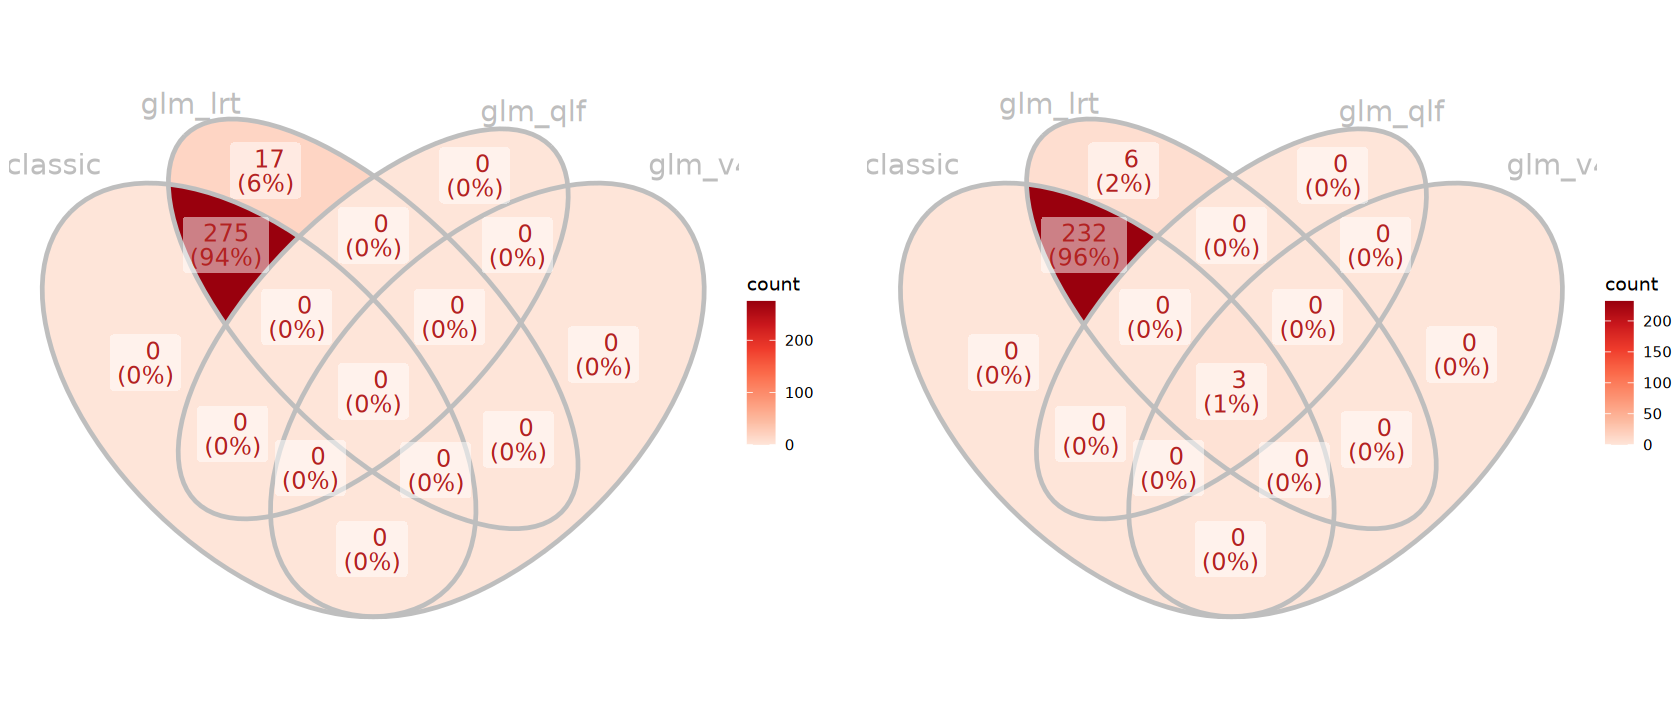

In [99]:
options(repr.plot.width = 14, repr.plot.height = 6)

p1 + plot_spacer() + p2 +
    plot_layout(nrow = 1, widths = c(1, 0.05, 1))

## 3). limma

> In the limma approach to RNA-seq, read counts are converted to log2-counts-per-million (logCPM), and the mean-variance relationship is modeled either with precision weights or with an empirical Bayes prior trend. The precision weights approach is called “voom,” and the prior trend approach is called “limma-trend.”

### a). limma-trend

> If the sequencing depth is fairly consistent across the RNA samples, then the simplest and most reliable method for differential expression is to use limma-trend. This method usually works well if the ratio of the largest library size to the smallest is no more than about 3-fold. Few literature uses.

In [100]:
design <- model.matrix(~ group, data = dgel$samples)
design

,(Intercept),groupKO
WT_rep1,1,0
WT_rep2,1,0
WT_rep3,1,0
KO_rep1,1,1
KO_rep2,1,1
KO_rep3,1,1


In [101]:
logCPM <- cpm(dgel, normalized.lib.sizes = TRUE, log = TRUE)
head(logCPM)

,WT_rep1,WT_rep2,WT_rep3,KO_rep1,KO_rep2,KO_rep3
ENSMUSG00000051951.5,-0.4447519,-2.6169280,-2.6074918,-1.3009422,-1.8383168,-1.9640162
ENSMUSG00000025902.13,-1.4387761,-0.5562765,-0.9289388,0.9598120,2.6918802,0.7308208
ENSMUSG00000098104.1,-1.9036814,-1.5479736,-1.4872046,-1.5650954,-2.1049594,-2.2257295
ENSMUSG00000103922.1,0.1646126,-0.1539231,0.1415650,0.3142492,0.7208567,0.3526153
ENSMUSG00000033845.13,7.4024097,7.7417289,7.7789260,7.7200429,7.5845281,7.8067599
ENSMUSG00000102275.1,1.6935662,1.9787039,1.9885235,2.0260096,2.3684393,2.0886520


In [102]:
# Linear Model for Series of Arrays
fit <- lmFit(logCPM, design)
# Empirical Bayes Statistics for Differential Expression
efit <- eBayes(fit, trend = TRUE)

In [ ]:
limma_trend_result <- topTable(efit, coef = 2, number = Inf) |> 
# limma_trend_result <- topTable(efit, coef = "groupKO", number = Inf) |> 
    as.data.frame() |> 
    rownames_to_column("gene_id") |>
    dplyr::rename(padj = adj.P.Val, pvalue = P.Value) |>
    mutate(
        result = case_when(
            padj < p_cutoff & logFC >  logfc_cutoff ~ "Up",
            padj < p_cutoff & logFC < -logfc_cutoff ~ "Down",
            TRUE ~ "NS") |> 
            factor(levels = c("Up", "Down", "NS"))) |>
    left_join(
        dgel$genes |> rownames_to_column("gene_id"), 
        by = "gene_id") |>
    column_to_rownames("gene_id")

table(limma_trend_result$result)
head(limma_trend_result)


   Up  Down    NS 
    1     4 19049 

,logFC,AveExpr,t,pvalue,padj,B,result,symbol,type,basepairs
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>,<chr>,<chr>,<int>
ENSMUSG00000061524.8,-1.858443,4.861256,-12.997584,8.347503e-07,0.01098278,5.124523,Down,Zic2,protein_coding,2880
ENSMUSG00000041703.7,-1.427031,5.035176,-11.865212,1.717356e-06,0.01098278,4.698827,Down,Zic5,protein_coding,4889
ENSMUSG00000022619.5,-2.384990,2.840543,-11.854861,1.729208e-06,0.01098278,4.694604,Down,Mapk8ip2,protein_coding,5700
ENSMUSG00000040187.15,-1.967303,2.041765,-9.189455,1.248499e-05,0.04827456,3.356980,Down,Arntl2,protein_coding,5691
ENSMUSG00000075122.5,1.750979,3.129535,9.171951,1.266783e-05,0.04827456,3.346266,Up,Cd80,protein_coding,3703
ENSMUSG00000030246.11,-1.160068,6.013792,-8.581855,2.097309e-05,0.06660355,2.967359,NS,Ldhb,protein_coding,1570


### b). limma-voom

> When library sizes vary significantly between samples, the voom approach is technically more powerful than limma-trend.

In [104]:
design <- model.matrix(~ group, data = dgel$samples)

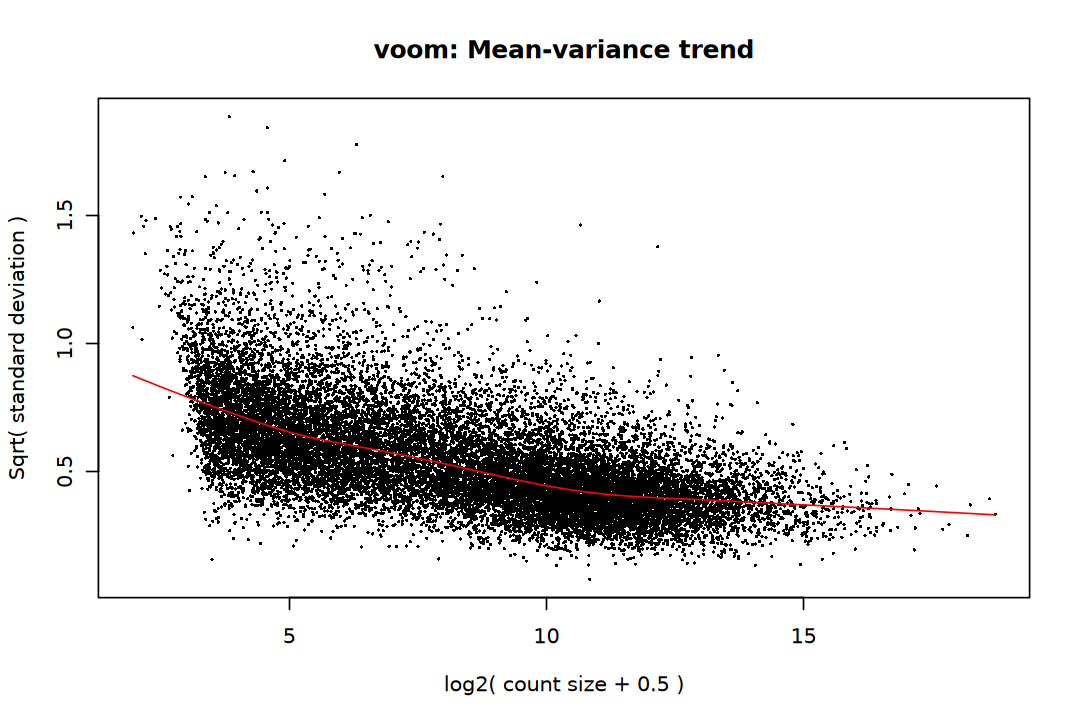

In [105]:
options(repr.plot.width = 9, repr.plot.height = 6)

norm_v <- voom(dgel, design, plot = TRUE)

In [106]:
# Linear Model for Series of Arrays
fit <- lmFit(norm_v, design)
# Empirical Bayes Statistics for Differential Expression
efit <- eBayes(fit)

In [ ]:
limma_voom_result <- topTable(efit, coef = 2, number = Inf) |> 
# limma_voom_result <- topTable(efit, coef = "groupKO", number = Inf) |> 
    as.data.frame() |> 
    dplyr::rename(padj = adj.P.Val, pvalue = P.Value) |>
    mutate(
        result = case_when(
            padj < p_cutoff & logFC >  logfc_cutoff ~ "Up",
            padj < p_cutoff & logFC < -logfc_cutoff ~ "Down",
            TRUE ~ "NS") |> 
            factor(levels = c("Up", "Down", "NS")))

table(limma_voom_result$result)
head(limma_voom_result)


   Up  Down    NS 
    0     3 19051 

,symbol,type,basepairs,logFC,AveExpr,t,pvalue,padj,B,result
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>
ENSMUSG00000061524.8,Zic2,protein_coding,2880,-1.858277,4.859286,-11.868010,1.783746e-06,0.01889792,5.401159,Down
ENSMUSG00000041703.7,Zic5,protein_coding,4889,-1.430553,5.033558,-11.708327,1.983617e-06,0.01889792,5.375286,Down
ENSMUSG00000022619.5,Mapk8ip2,protein_coding,5700,-2.398655,2.831523,-10.909709,3.443024e-06,0.02186779,4.256763,Down
ENSMUSG00000030246.11,Ldhb,protein_coding,1570,-1.161119,6.012999,-8.513258,2.292889e-05,0.08306345,3.281453,NS
ENSMUSG00000040187.15,Arntl2,protein_coding,5691,-1.980295,2.027360,-9.411928,1.073697e-05,0.05114557,3.235957,NS
ENSMUSG00000075122.5,Cd80,protein_coding,3703,1.762331,3.123050,8.364744,2.615623e-05,0.08306345,2.881010,NS


### c). voomLmFit

> In recent versions of limma and edgeR, we now recommend voomLmFit as the preferred interface for RNA-seq analyses, replacing voom, lmFit, and voomWithQualityWeights. voomLmFit ensures unbiased estimation of the residual variances, even for genes that have no counts at all in some experimental conditions.
> - voomLmFit = voom transform + lmFit with weights

In [108]:
design <- model.matrix(~ group, data = dgel$samples)

In [109]:
# sample.weights = TRUE: estimating the empirical sample quality weights
fit <- voomLmFit(dgel, design = design, sample.weights = TRUE)
efit <- eBayes(fit)

First sample weights (min/max) 0.421835/2.647527

Final sample weights (min/max) 0.4220781/2.6542952



In [ ]:
limma_voomLmFit_result <- topTable(efit, coef = 2, number = Inf) |> 
# limma_voomLmFit_result <- topTable(efit, coef = "groupKO", number = Inf) |> 
    as.data.frame() |> 
    dplyr::rename(padj = adj.P.Val, pvalue = P.Value) |>
    mutate(
        result = case_when(
            padj < p_cutoff & logFC >  logfc_cutoff ~ "Up",
            padj < p_cutoff & logFC < -logfc_cutoff ~ "Down",
            TRUE ~ "NS") |> 
            factor(levels = c("Up", "Down", "NS")))

table(limma_voomLmFit_result$result)
head(limma_voomLmFit_result)


   Up  Down    NS 
  225   190 18639 

,symbol,type,basepairs,logFC,AveExpr,t,pvalue,padj,B,result
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>
ENSMUSG00000041703.7,Zic5,protein_coding,4889,-1.435492,5.033558,-12.933647,5.142777e-07,0.005363738,6.818211,Down
ENSMUSG00000061524.8,Zic2,protein_coding,2880,-1.925817,4.859286,-12.275464,7.958643e-07,0.005363738,6.395986,Down
ENSMUSG00000022619.5,Mapk8ip2,protein_coding,5700,-2.279181,2.831523,-12.188422,8.445059e-07,0.005363738,5.817886,Down
ENSMUSG00000075122.5,Cd80,protein_coding,3703,1.815782,3.123050,10.009040,4.281551e-06,0.017958853,4.708782,Up
ENSMUSG00000030246.11,Ldhb,protein_coding,1570,-1.280398,6.012999,-9.697593,5.533912e-06,0.017958853,4.635388,Down
ENSMUSG00000032999.10,Nlrp4f,protein_coding,3870,2.038000,4.225247,9.429295,6.941939e-06,0.018895957,4.378015,Up


### Evaluate DEGs

In [111]:
suppressPackageStartupMessages(library(ggVennDiagram))

In [ ]:
genes_up <- list(
    trend = limma_trend_result |> filter(result == "Up") |> 
        pull(symbol) |> unique(),
    voom = limma_voom_result |> filter(result == "Up") |> 
        pull(symbol) |> unique(),
    voom_wight = limma_voomLmFit_result |> filter(result == "Up") |> 
        pull(symbol) |> unique())

genes_down <- list(
    trend = limma_trend_result |> filter(result == "Down") |> 
        pull(symbol) |> unique(),
    voom = limma_voom_result |> filter(result == "Down") |> 
        pull(symbol) |> unique(),
    voom_wight = limma_voomLmFit_result |> filter(result == "Down") |> 
        pull(symbol) |> unique())

In [113]:
p1 <- ggVennDiagram(
    genes_up, set_color = "grey", set_size = 6, 
    label_color = "firebrick", label_size = 5) +
    scale_fill_distiller(palette = "Reds", direction = 1)

p2 <- ggVennDiagram(
    genes_down, set_color = "grey", set_size = 6, 
    label_color = "firebrick", label_size = 5) +
    scale_fill_distiller(palette = "Reds", direction = 1)

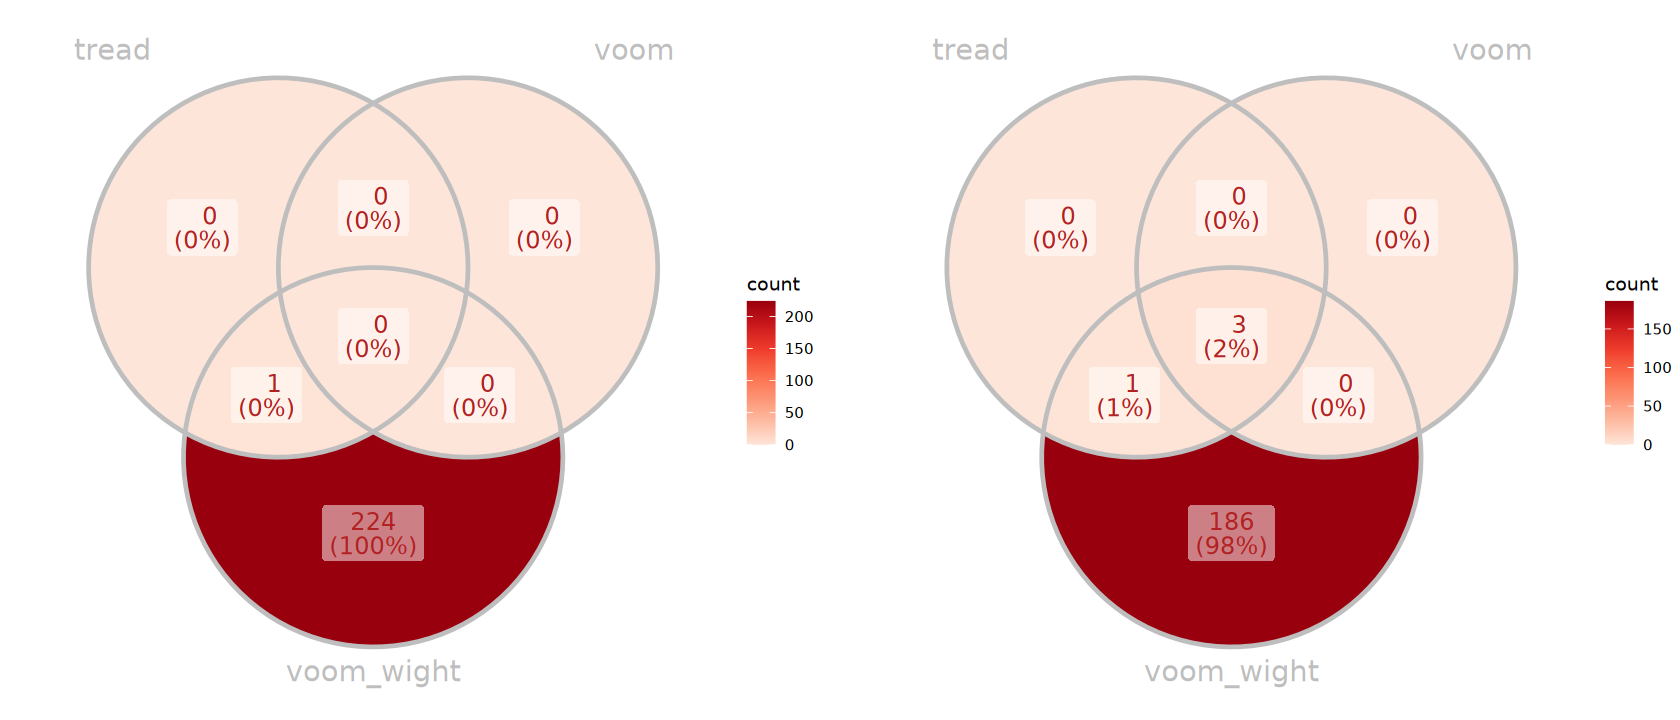

In [114]:
options(repr.plot.width = 14, repr.plot.height = 6)

p1 + plot_spacer() + p2 +
    plot_layout(nrow = 1, widths = c(1, 0.05, 1))

## DEGs Evaluation

In [115]:
add_label <- function(res, symbol_col = "symbol"){
    res |>
        tibble::rownames_to_column("gene_id") |>
        dplyr::group_by(result) |>
        dplyr::arrange(padj, dplyr::desc(abs(logFC)), .by_group = TRUE) |>
        dplyr::mutate(
            label = dplyr::if_else(
                result %in% c("Up", "Down") & dplyr::row_number() <= 10,
                .data[[symbol_col]], NA_character_)) |>
        dplyr::ungroup() |>
        tibble::column_to_rownames("gene_id")
}

In [116]:
deseq2_result <- add_label(deseq2_lfc_result, symbol_col = "symbol")
edger_result <- add_label(edger_glm_lrt_result, symbol_col = "symbol")
limma_result <- add_label(limma_voomLmFit_result, symbol_col = "symbol")

### P-value Histogram

Warning message:
"Removed 6 rows containing non-finite outside the scale range (`stat_bin()`)."


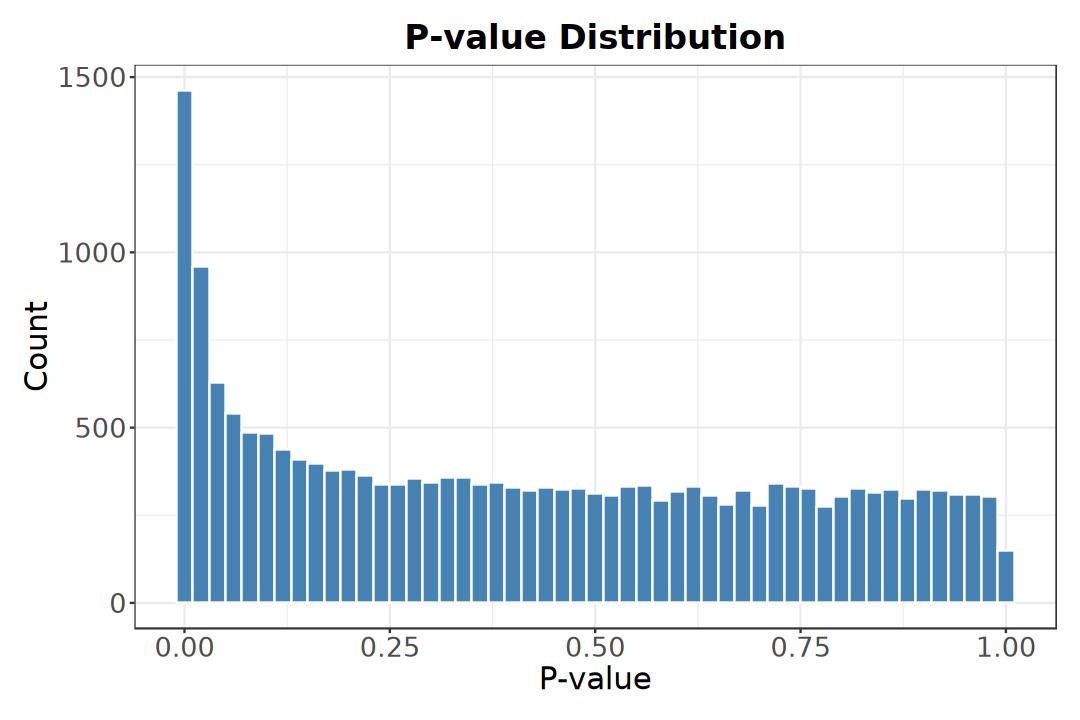

In [117]:
options(repr.plot.width = 9, repr.plot.height = 6)

ggplot(deseq2_result, aes(x = pvalue)) +
    geom_histogram(binwidth = 0.02, fill = "steelblue", color = "white") +
    labs(
        title = "P-value Distribution", 
        x = "P-value", y = "Count") +
    theme_bw() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

### MA Plot

> - Mean-Difference plot
> - Bland-Altman plot

In [118]:
ggplot_maplot <- function(plot_df, col, log = FALSE, title = NULL) {
    if(log) {
        x_vals <- log2(plot_df[[col]] + 1)
    } else {
        x_vals <- plot_df[[col]]
    }

    max_logfc <- plot_df$logFC |> abs() |> 
        max(na.rm = TRUE) |> ceiling()

    ggplot(plot_df, aes(x = x_vals, y = logFC)) +
        geom_point(
            aes(color = result, size = result), na.rm = TRUE) +
        geom_hline(
            yintercept = c(-logfc_cutoff, logfc_cutoff),
            linetype = "dashed", color = "gray") +
        geom_text_repel(
            aes(label = label), color = "black", na.rm = TRUE, size = 6, 
            min.segment.length = 0, segment.size = 0.5, max.overlaps = Inf) +
        scale_y_continuous(limits = c(-max_logfc, max_logfc)) +
        scale_color_manual(
            values = c(Up = "LightCoral", Down = "SkyBlue", NS = "gray")) +
        scale_size_manual(
            values = c(Up = 2, Down = 2, NS = 1), guide = "none") +
        guides(
            color = guide_legend(override.aes = list(size = 6))) +
        labs(
            title = paste0("MA plot (", title,")"), , color = "DEG",
            x = "Mean Expression", y = "log2FC") +
        theme_test() + 
        theme(
            plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
            plot.margin = unit(c(1, 1, 1, 1), "line"),
            legend.title = element_text(size = 18), 
            legend.text = element_text(size = 16),
            axis.title = element_text(size = 18),
            axis.text = element_text(size = 16))
}

In [119]:
p1 <- ggplot_maplot(deseq2_result, col = "baseMean", log = TRUE, title = "DESeq2")
p2 <- ggplot_maplot(edger_result, col = "logCPM", title = "edgeR")
p3 <- ggplot_maplot(limma_result, col = "AveExpr", title = "limma-voom")

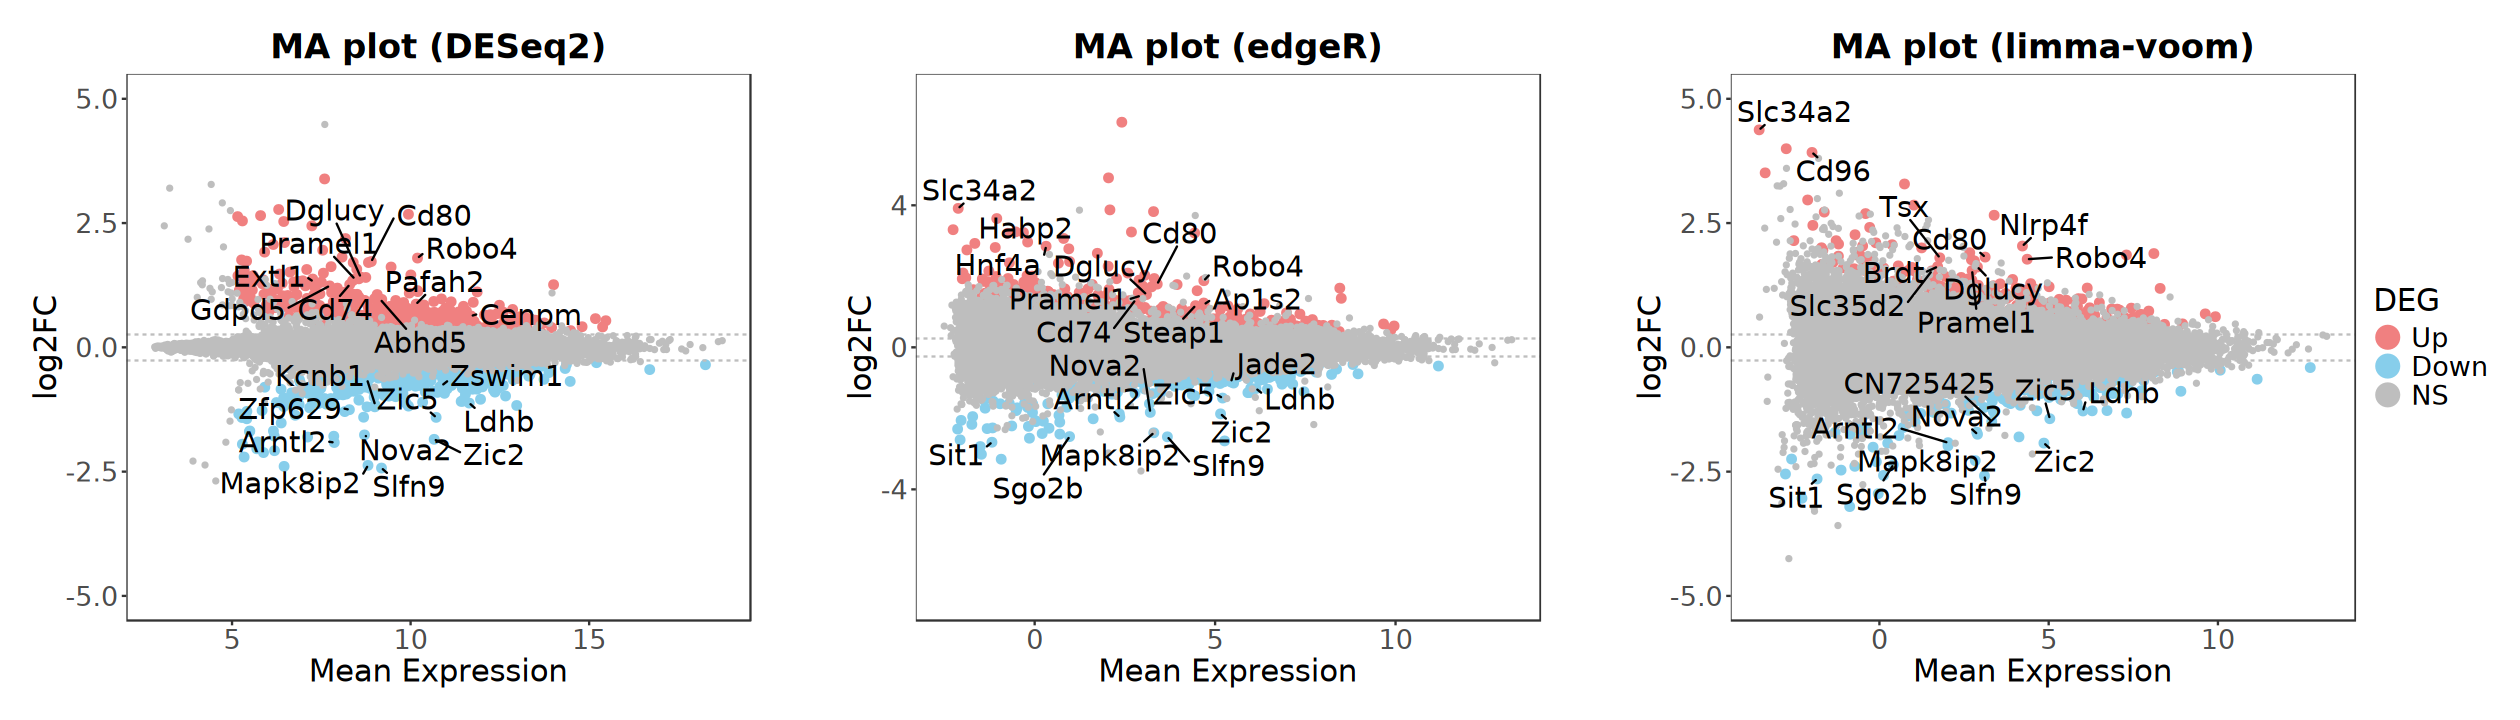

In [120]:
options(repr.plot.width = 21, repr.plot.height = 6)

p1 + plot_spacer() + p2 + plot_spacer() + p3 +
    plot_layout(
        nrow = 1, guides = "collect", 
        widths = c(1, 0.05, 1, 0.05, 1))

### Volcano

In [121]:
ggplot_volcano <- function(plot_df, title = NULL) {
    max_logfc <- plot_df$logFC |> abs() |> 
        max(na.rm = TRUE) |> ceiling()
    min_padj <- plot_df$padj |> pmax(1e-300) |> 
        (\(x) -log10(x))() |> max(na.rm = TRUE) |> 
        (\(x) ceiling(x / 5) * 5)()

    ggplot(plot_df, aes(x = logFC, y = -log10(pmax(padj, 1e-300)))) +
        geom_point(
            aes(color = result, size = result), na.rm = TRUE) +
        geom_hline(
            yintercept = -log10(p_cutoff), 
            linetype = "dashed", color = "gray") + 
        geom_vline(
            xintercept = c(-logfc_cutoff, logfc_cutoff),
            linetype = "dashed", color = "gray") +
        ggrepel::geom_text_repel(
            aes(label = label), color = "black", na.rm = TRUE, size = 4, 
            min.segment.length = 0, segment.size = 0.5, max.overlaps = Inf) +
        scale_x_continuous(
            expand = c(0.1, 0), limits = c(-max_logfc, max_logfc)) +
        scale_y_continuous(
            expand = expansion(mult = c(0, 0.1)), limits = c(0, min_padj)) + 
        scale_color_manual(
            values = c(Up = "LightCoral", Down = "SkyBlue", NS = "gray")) +
        scale_size_manual(
            values = c(Up = 2, Down = 2, NS = 1), guide = "none") +
        labs(
            title = paste0("Volcano (", title,")"), , color = "DEG",
            x = "log2FC", y = expression(-log[10](P.adjust))) +
        guides(
            color = guide_legend(override.aes = list(size = 6))) +
        theme_test() + 
        theme(
            plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
            plot.margin = unit(c(1, 1, 1, 1), "line"),
            legend.title = element_text(size = 18), 
            legend.text = element_text(size = 16),
            axis.title = element_text(size = 18), 
            axis.text = element_text(size = 16))
}

In [122]:
p1 <- ggplot_volcano(deseq2_result, title = "DESeq2")
p2 <- ggplot_volcano(edger_result, title = "edgeR")
p3 <- ggplot_volcano(limma_result, title = "limma-voom")

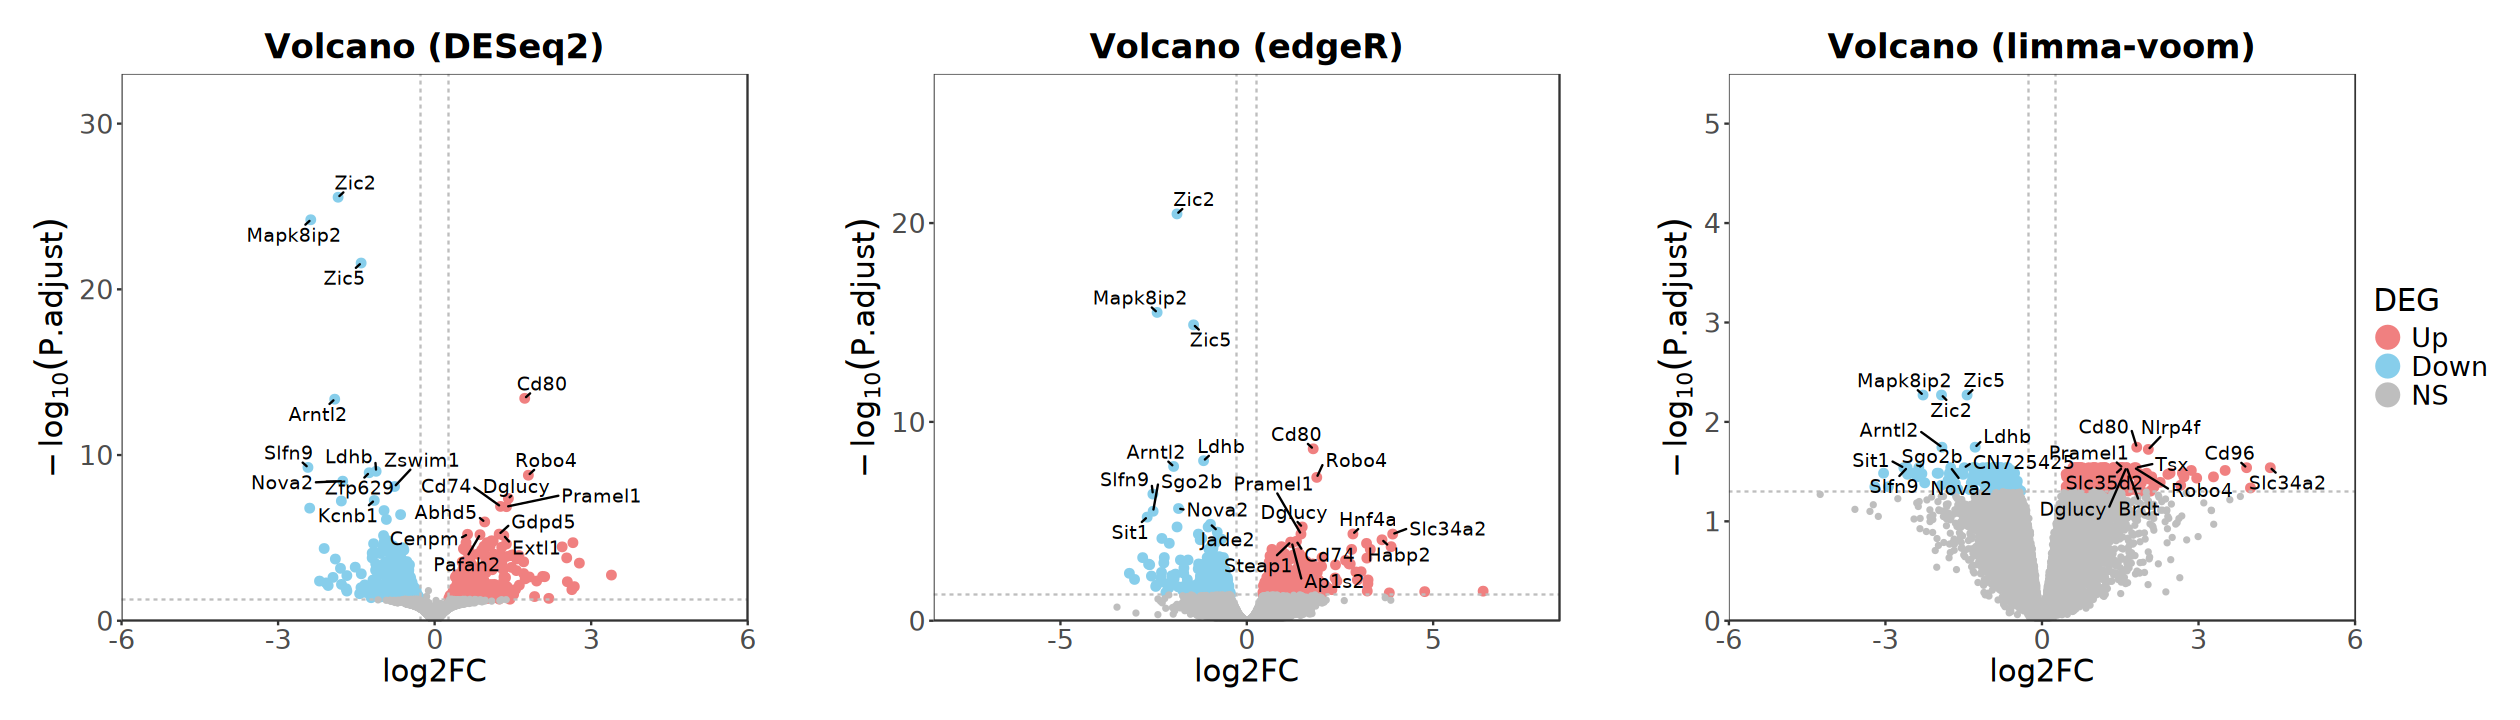

In [123]:
options(repr.plot.width = 21, repr.plot.height = 6)

p1 + plot_spacer() + p2 + plot_spacer() + p3 +
    plot_layout(
        nrow = 1, guides = "collect", 
        widths = c(1, 0.05, 1, 0.05, 1))

### Venn

In [124]:
suppressPackageStartupMessages(library(ggVennDiagram))

In [125]:
genes_up <- list(
    DESeq2 = deseq2_result |> filter(result == "Up") |> 
        pull(symbol) |> unique(),
    edgeR = edger_result |> filter(result == "Up") |> 
        pull(symbol) |> unique(),
    limma = limma_result |> filter(result == "Up") |> 
        pull(symbol) |> unique())

genes_down <- list(
    DESeq2 = deseq2_result |> filter(result == "Down") |> 
        pull(symbol) |> unique(),
    edgeR = edger_result |> filter(result == "Down") |> 
        pull(symbol) |> unique(),
    limma = limma_result |> filter(result == "Down") |> 
        pull(symbol) |> unique())

In [126]:
p1 <- ggVennDiagram(
    genes_up, set_color = "grey", set_size = 6, 
    label_color = "firebrick", label_size = 5) +
    scale_fill_distiller(palette = "Reds", direction = 1)

p2 <- ggVennDiagram(
    genes_down, set_color = "grey", set_size = 6, 
    label_color = "firebrick", label_size = 5) +
    scale_fill_distiller(palette = "Reds", direction = 1)

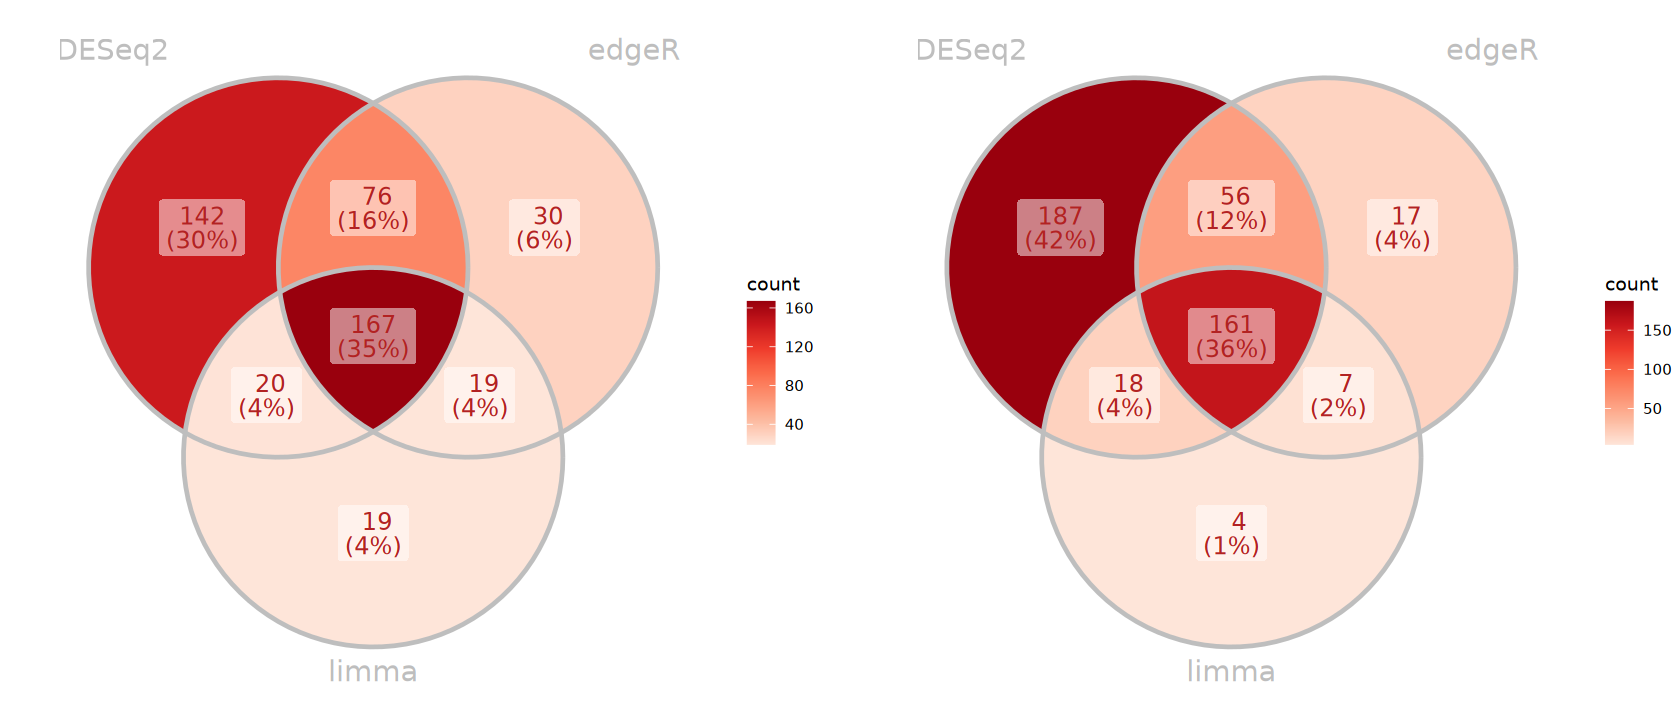

In [127]:
options(repr.plot.width = 14, repr.plot.height = 6)

p1 + plot_spacer() + p2 +
    plot_layout(nrow = 1, widths = c(1, 0.05, 1))

### Upset

In [128]:
suppressPackageStartupMessages(library(UpSetR))

Warning message:
"Using `size` aesthetic for lines was deprecated in ggplot2 3.4.0.
ℹ Please use `linewidth` instead.
ℹ The deprecated feature was likely used in the UpSetR package.
  Please report the issue to the authors."
Warning message:
"The `size` argument of `element_line()` is deprecated as of ggplot2 3.4.0.
ℹ Please use the `linewidth` argument instead.
ℹ The deprecated feature was likely used in the UpSetR package.
  Please report the issue to the authors."


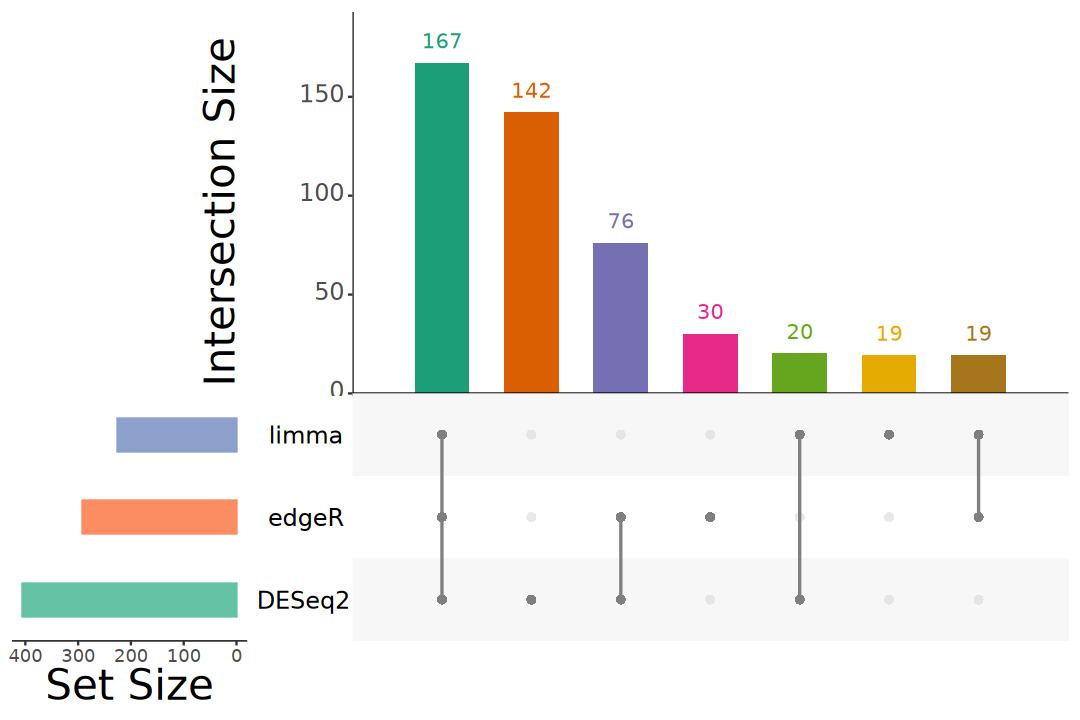

In [129]:
options(repr.plot.width = 9, repr.plot.height = 6)
UpSetR::upset(
    fromList(genes_up), mb.ratio = c(0.55, 0.45),
    order.by = "freq", decreasing = TRUE,
    sets.bar.color = brewer.pal(n = 3, name = "Set2"),
    main.bar.color = brewer.pal(n = 7, name = "Dark2"),
    matrix.color = "grey50",
    text.scale = c(3, 2, 3, 1.5, 2, 2))

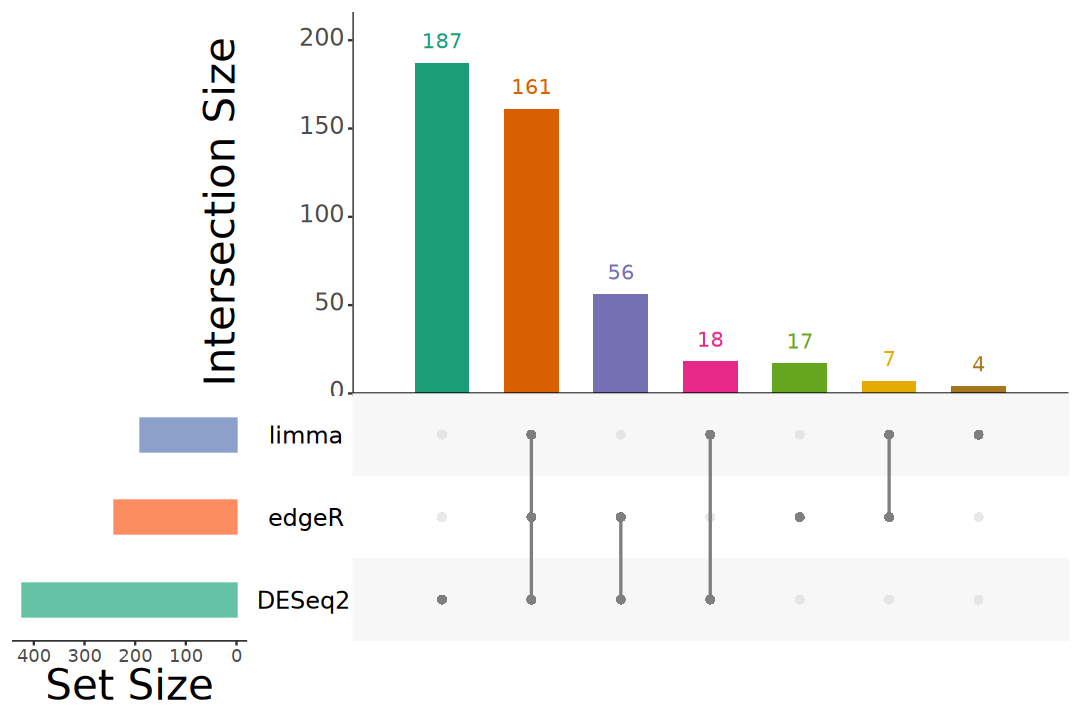

In [130]:
options(repr.plot.width = 9, repr.plot.height = 6)
UpSetR::upset(
    fromList(genes_down), mb.ratio = c(0.55, 0.45),
    order.by = "freq", decreasing = TRUE,
    sets.bar.color = brewer.pal(n = 3, name = "Set2"),
    main.bar.color = brewer.pal(n = 7, name = "Dark2"),
    matrix.color = "grey50",
    text.scale = c(3, 2, 3, 1.5, 2, 2))

## DEGs Visualization

In [131]:
res_lfc <- lfcShrink(dds, coef = "Group_KO_vs_WT", type = "apeglm")
summary(res_lfc)

using 'apeglm' for LFC shrinkage. If used in published research, please cite:
    Zhu, A., Ibrahim, J.G., Love, M.I. (2018) Heavy-tailed prior distributions for
    sequence count data: removing the noise and preserving large differences.
    Bioinformatics. https://doi.org/10.1093/bioinformatics/bty895




out of 19304 with nonzero total read count
adjusted p-value < 0.1
LFC > 0 (up)       : 630, 3.3%
LFC < 0 (down)     : 694, 3.6%
outliers [1]       : 6, 0.031%
low counts [2]     : 4117, 21%
(mean count < 34)
[1] see 'cooksCutoff' argument of ?results
[2] see 'independentFiltering' argument of ?results



In [132]:
degs_result <- res_lfc |> as.data.frame() |> 
    rownames_to_column("gene_id") |>
    dplyr::rename(logFC = log2FoldChange) |>
    mutate(
        result = case_when(
            padj < p_cutoff & logFC >  logfc_cutoff ~ "Up",
            padj < p_cutoff & logFC < -logfc_cutoff ~ "Down",
            TRUE ~ "NS") |> 
            factor(levels = c("Up", "Down", "NS"))) |>
    left_join(
        rowData(dds) |> 
            as.data.frame() |> 
            dplyr::select(symbol, type, basepairs) |>
            rownames_to_column("gene_id"), 
        by = "gene_id") |>
    group_by(result) |>
    arrange(padj, logFC |> abs() |> desc()) |>
    mutate(
        label = ifelse(
            type == "protein_coding" & 
                result %in% c("Up", "Down") & 
                row_number() <= 5, 
            symbol, NA_character_)) |>
    ungroup() |>
    column_to_rownames("gene_id")

table(degs_result$result)
head(degs_result)


   Up  Down    NS 
  405   422 18477 

,baseMean,logFC,lfcSE,pvalue,padj,result,symbol,type,basepairs,label
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>,<chr>,<chr>,<int>,<chr>
ENSMUSG00000061524.8,1616.7341,-1.850059,0.1650276,1.818959e-30,2.761361e-26,Down,Zic2,protein_coding,2880,Zic2
ENSMUSG00000022619.5,446.8995,-2.373832,0.2183987,8.300985e-29,6.300863e-25,Down,Mapk8ip2,protein_coding,5700,Mapk8ip2
ENSMUSG00000041703.7,1679.9443,-1.408583,0.1371615,5.102710e-26,2.582141e-22,Down,Zic5,protein_coding,4889,Zic5
ENSMUSG00000075122.5,476.5647,1.726608,0.2098622,9.928324e-18,3.768047e-14,Up,Cd80,protein_coding,3703,Cd80
ENSMUSG00000040187.15,231.7262,-1.914681,0.2339134,1.398482e-17,4.246072e-14,Down,Arntl2,protein_coding,5691,Arntl2
ENSMUSG00000069793.12,581.1572,-2.427636,0.3512606,2.197037e-13,5.558869e-10,Down,Slfn9,protein_coding,5965,Slfn9


In [133]:
max_logfc <- degs_result$logFC |> abs() |> 
    max(na.rm = TRUE) |> 
    ceiling()

min_padj <- degs_result$padj |> pmax(1e-300) |>
    (\(x) -log10(x))() |>
    max(na.rm = TRUE) |>
    (\(x) ceiling(x / 10) * 10)()

### MA Plot

> - Mean-Difference plot
> - Bland-Altman plot

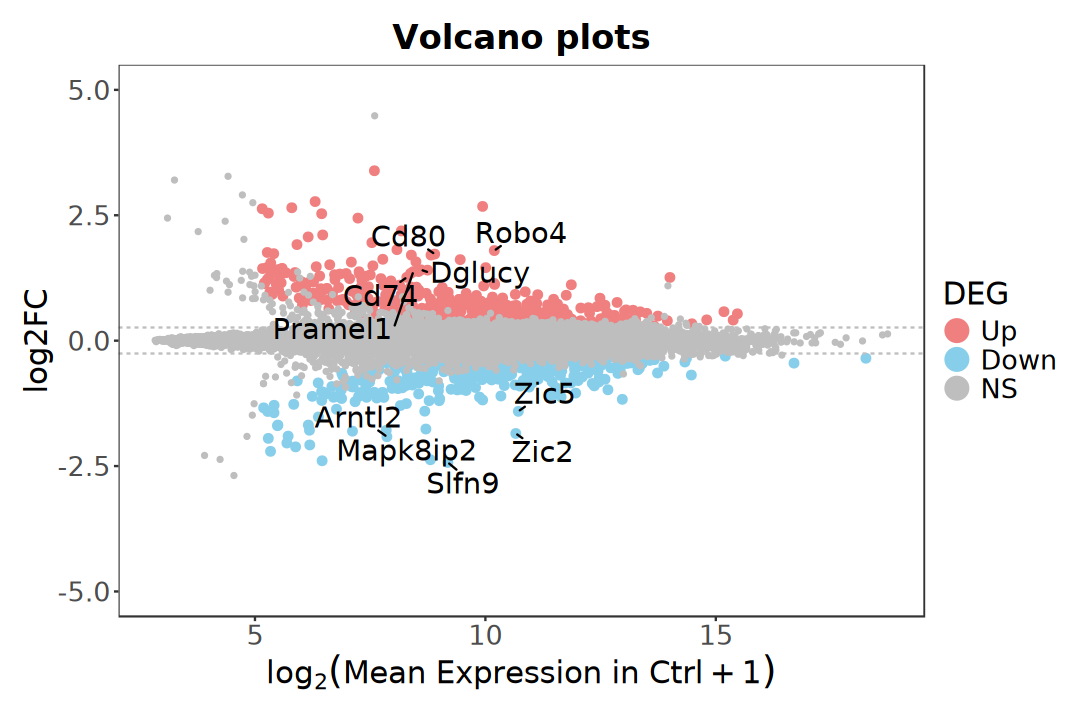

In [134]:
options(repr.plot.width = 9, repr.plot.height = 6)

ggplot(degs_result, aes(x = log2(baseMean + 1), y = logFC)) +
    geom_point(
        aes(color = result, size = result), na.rm = TRUE) +
    geom_hline(
        yintercept = c(-logfc_cutoff, logfc_cutoff),
        linetype = "dashed", color = "gray") +
    geom_text_repel(
        aes(label = label), color = "black", na.rm = TRUE, size = 6, 
        min.segment.length = 0, segment.size = 0.5, max.overlaps = Inf) +
    scale_y_continuous(limits = c(-max_logfc, max_logfc)) +
    scale_color_manual(
        values = c(Up = "LightCoral", Down = "SkyBlue", NS = "gray")) +
    scale_size_manual(
        values = c(Up = 2, Down = 2, NS = 1), guide = "none") +
    guides(
        color = guide_legend(override.aes = list(size = 6))) +
    labs(
        title = "Volcano plots", color = "DEG",
        x = expression(log[2]("Mean Expression in Ctrl" + 1)),
        y = "log2FC") +
    theme_test() + 
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18),
        axis.text = element_text(size = 16))

### Volcano

In [135]:
p1 <- ggplot(degs_result, aes(x = logFC, y = -log10(pmax(padj, 1e-300)))) +
    geom_point(
        aes(color = result, size = result), na.rm = TRUE) +
    geom_hline(
        yintercept = -log10(p_cutoff), 
        linetype = "dashed", color = "gray") + 
    geom_vline(
        xintercept = c(-logfc_cutoff, logfc_cutoff),
        linetype = "dashed", color = "gray") +
    geom_text_repel(
        aes(label = label), color = "black", na.rm = TRUE, size = 6, 
        min.segment.length = 0, segment.size = 0.5, max.overlaps = Inf) +
    scale_x_continuous(
        expand = c(0.1, 0), limits = c(-max_logfc, max_logfc)) +
    scale_y_continuous(
        expand = expansion(mult = c(0, 0.1)), limits = c(0, min_padj)) + 
    scale_color_manual(
        values = c(
            Up = "LightCoral", Down = "SkyBlue", NS = "gray")) +
    scale_size_manual(
        values = c(
            Up = 2, Down = 2, NS = 1), guide = "none") +
    guides(
        color = guide_legend(override.aes = list(size = 6))) +
    labs(
        title = "Volcano plots", color = "DEG",
        x = "log2FC", y = expression(-log[10](P.adjust))) +
    theme_test() + 
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18),
        axis.text = element_text(size = 16))

In [136]:
p2 <- ggplot(degs_result, aes(x = logFC, y = -log10(pmax(padj, 1e-300)))) +
    geom_point(
        aes(color = logFC, size = logFC), na.rm = TRUE) +
    geom_hline(
        yintercept = -log10(p_cutoff), 
        linetype = "dashed", color = "gray") + 
    geom_vline(
        xintercept = c(-logfc_cutoff, logfc_cutoff),
        linetype = "dashed", color = "gray") +
    geom_text_repel(
        aes(label = label), color = "black", na.rm = TRUE, size = 6, 
        min.segment.length = 0, segment.size = 0.5, max.overlaps = Inf) +
    scale_x_continuous(
        expand = c(0.1, 0), limits = c(-max_logfc, max_logfc)) +
    scale_y_continuous(
        expand = expansion(mult = c(0, 0.1)), limits = c(0, min_padj)) + 
    scale_color_gradientn(
        colours = brewer.pal(11, 'RdYlBu') |> rev(), 
        limits = c(-max_logfc, max_logfc)) +
    scale_size_continuous(range = c(1, 3), guide = "none") +
    labs(
        title = "Volcano plots",
        x = "log2FC", y = expression(-log[10](P.adjust))) +
    theme_test() + 
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18),
        axis.text = element_text(size = 16))

In [137]:
p3 <- degs_result |>
    mutate(
        neglog10_padj = -log10(pmax(padj, 1e-300)), 
        neglog10_padj_m = ifelse(
            logFC < 0, -neglog10_padj, neglog10_padj)) |>
    ggplot(aes(x = logFC, y = neglog10_padj)) +
        geom_point(
            aes(color = neglog10_padj_m, size = neglog10_padj), na.rm = TRUE) +
        geom_hline(
            yintercept = -log10(p_cutoff), 
            linetype = "dashed", color = "gray") + 
        geom_vline(
            xintercept = c(-logfc_cutoff, logfc_cutoff),
            linetype = "dashed", color = "gray") +
        geom_text_repel(
            aes(label = label), color = "black", na.rm = TRUE, size = 6, 
            min.segment.length = 0, segment.size = 0.5, max.overlaps = Inf) +
        scale_x_continuous(
            expand = c(0.1, 0), limits = c(-max_logfc, max_logfc)) +
        scale_y_continuous(
            expand = expansion(mult = c(0, 0.1)), limits = c(0, min_padj)) + 
        scale_color_gradientn(
            name = expression(-log[10](P.adjust)),
            colours = brewer.pal(11, 'RdBu') |> rev(), 
            limits = c(-min_padj, min_padj),
            breaks = c(-min_padj, 0, min_padj),
            labels = c(min_padj, 0, min_padj)) +
        scale_size_continuous(range = c(1, 3), guide = "none") +
        labs(
            title = "Volcano plots", color = "DEG",
            x = "log2FC", y = expression(-log[10](P.adjust))) +
        theme_test() + 
        theme(
            plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
            plot.margin = unit(c(1, 1, 1, 1), "line"),
            legend.title = element_text(size = 18), 
            legend.text = element_text(size = 16),
            legend.key.size = unit(1, "cm"),
            axis.title = element_text(size = 18),
            axis.text = element_text(size = 16))

In [138]:
p4 <- ggplot(degs_result, aes(x = logFC, y = -log10(pmax(padj, 1e-300)))) +
    geom_point(
        aes(color = -log10(pmax(padj, 1e-300)), size = -log10(pmax(padj, 1e-300))),
        na.rm = TRUE, alpha = 0.8) +
    geom_hline(
        yintercept = -log10(p_cutoff), 
        linetype = "dashed", color = "gray") + 
    geom_vline(
        xintercept = c(-logfc_cutoff, logfc_cutoff),
        linetype = "dashed", color = "gray") +
    geom_text_repel(
        aes(label = label), color = "black", na.rm = TRUE, size = 6, 
        min.segment.length = 0, segment.size = 0.5, max.overlaps = Inf) +
    scale_x_continuous(
        expand = c(0.1, 0), limits = c(-max_logfc, max_logfc)) +
    scale_y_continuous(
        expand = expansion(mult = c(0, 0.1)), limits = c(0, min_padj)) +  
    # scale_color_viridis_c(
    #     option = "turbo", begin = 0.1, end = 0.9) + 
    # scale_color_gradientn(
    #     colours = brewer.pal(11, 'RdYlBu') |> rev())+
    # scale_color_gradientn(
    #     colors = c("#39489f","#39bbec","#f9ed36","#f38466","#b81f25")) +
    scale_color_gradientn(
        colors = c(
            "#5E4FA2", "#3288BD", "#66C2A5", "#ABDDA4", 
            "#E6F598", "#FFFFBF", "#FEE08B", "#FDAE61", 
            "#F46D43", "#D53E4F", "#9C2007", "#9E0142")) +
    scale_size_continuous(range = c(1, 3), guide = "none") +
    labs(
        title = "Volcano plots", 
        color = expression(-log[10](P.adjust)),
        x = "log2FC", y = expression(-log[10](P.adjust))) +
    theme_test() + 
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        legend.key.size = unit(1, "cm"),
        axis.title = element_text(size = 18),
        axis.text = element_text(size = 16))

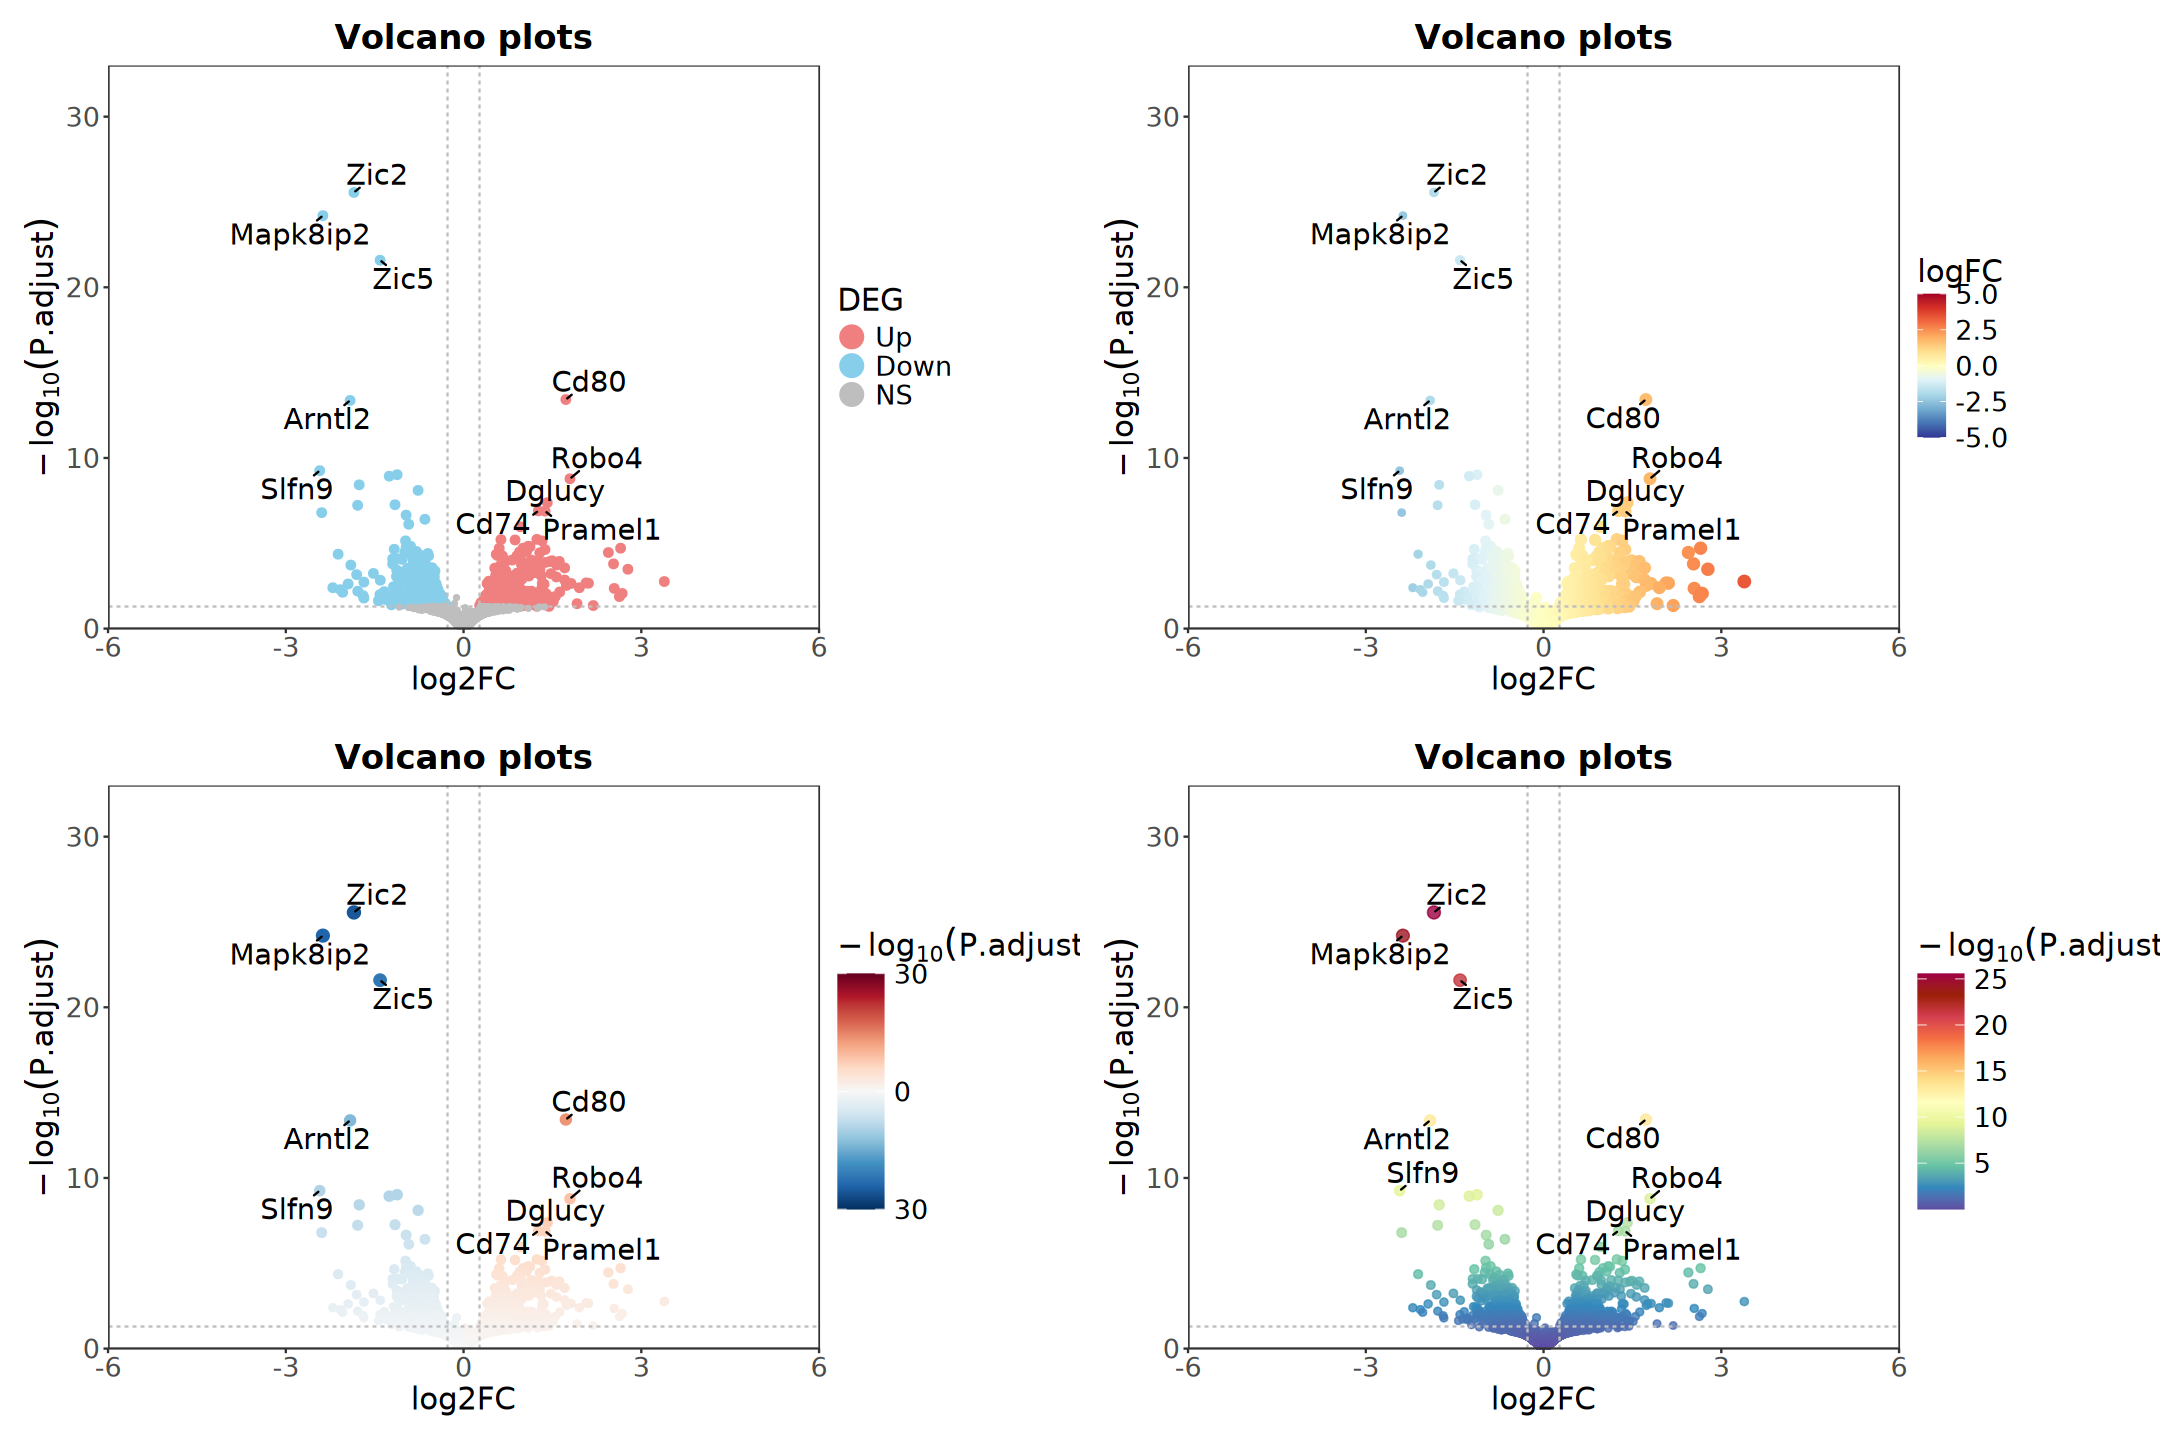

In [139]:
options(repr.plot.width = 18, repr.plot.height = 12)
cowplot::plot_grid(
    p1, p2, p3, p4, nrow = 2, align = "hv", axis = "tblr")

### Scatter Plot

In [140]:
ctrl_samples <- colnames(dds)[dds$Group == "WT"]
treat_samples <- colnames(dds)[dds$Group == "KO"]

mean_expr <- dds |> 
    counts(normalized = TRUE) |> 
    as.data.frame() |> 
    rownames_to_column(var = "gene_id") |> 
    mutate(
        Ctrl_Mean = rowMeans(across(all_of(ctrl_samples))),
        Treat_Mean = rowMeans(across(all_of(treat_samples)))) |> 
    dplyr::select(gene_id, Ctrl_Mean, Treat_Mean)

In [141]:
plot_df <- degs_result |> 
    rownames_to_column(var = "gene_id") |> 
    inner_join(mean_expr, by = "gene_id") |> 
    mutate(
        log2_Ctrl = log2(Ctrl_Mean + 1),
        log2_Treat = log2(Treat_Mean + 1)) |> 
    drop_na(log2_Ctrl, log2_Treat)

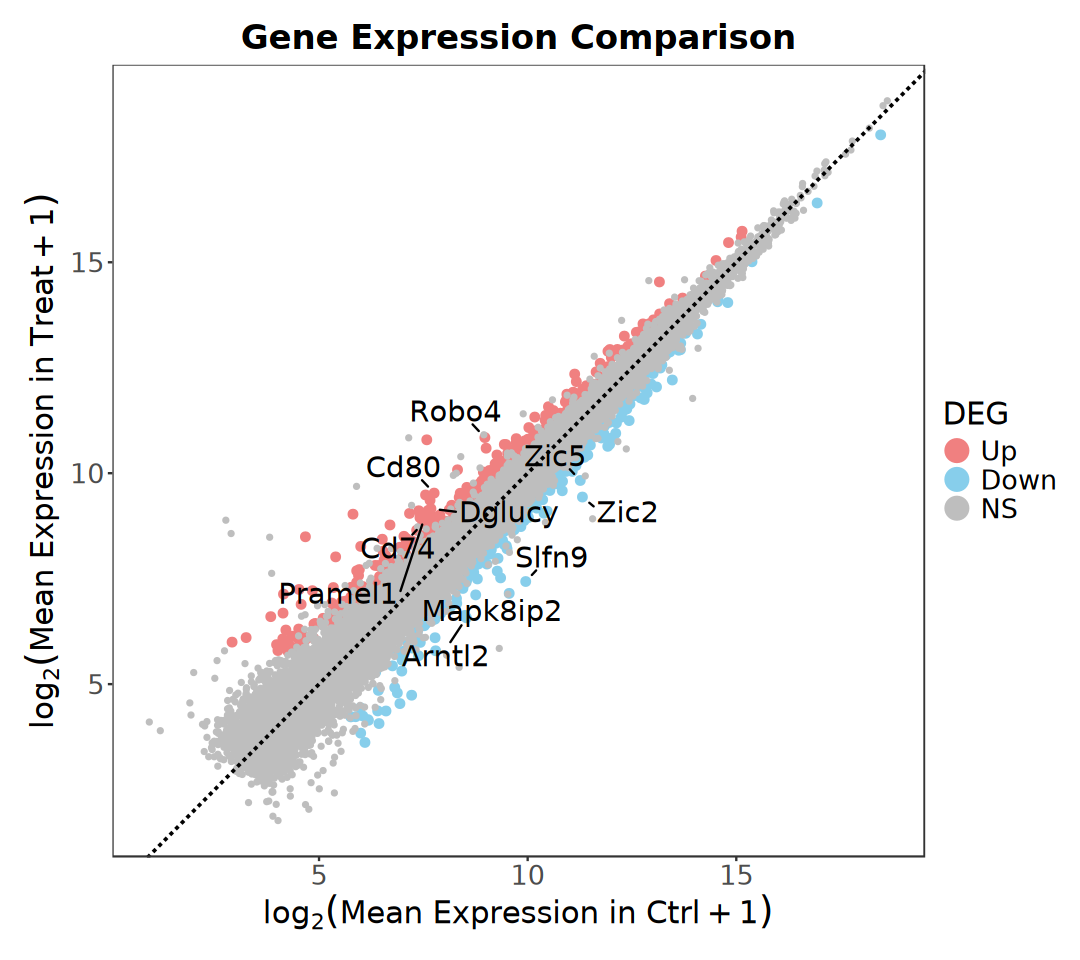

In [142]:
options(repr.plot.width = 9, repr.plot.height = 8)

ggplot(plot_df, aes(x = log2_Ctrl, y = log2_Treat)) +
    geom_point(
        aes(color = result, size = result), na.rm = TRUE) +
    geom_abline(
        intercept = 0, slope = 1, linetype = "dashed", 
        color = "black", linewidth = 0.8) +
    geom_text_repel(
        aes(label = label), color = "black", na.rm = TRUE, size = 6, 
        box.padding = 0.5, point.padding = 0.3,
        min.segment.length = 0, segment.size = 0.5, max.overlaps = Inf) +
    scale_color_manual(
        values = c(Up = "LightCoral", Down = "SkyBlue", NS = "gray")) +
    scale_size_manual(
        values = c(Up = 2, Down = 2, NS = 1), guide = "none") +
    guides(
        color = guide_legend(override.aes = list(size = 6))) +
    labs(
        title = "Volcano plots", color = "DEG",
        x = "log2FC", y = expression(-log[10](P.adjust))) +
    labs(
        title = "Gene Expression Comparison",
        x = expression(log[2]("Mean Expression in Ctrl" + 1)),
        y = expression(log[2]("Mean Expression in Treat" + 1))) + 
    theme_test() + 
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18),
        axis.text = element_text(size = 16))

### Heatmap

In [143]:
heatmap_dat <- degs_result |>
    filter(result %in% c("Up", "Down")) |>
    rownames() |>
    (\(idx) norm_mat[idx, ])()

In [144]:
ar <- degs_result |> 
    dplyr::select(DEG = result, logFC)

ac <- colData(dds) |> as.data.frame() |>
    dplyr::select(Replicate, Group)

In [145]:
group_colors <- setNames(
    scales::brewer_pal(palette = "Set1")(nlevels(dds$Group)),
    levels(dds$Group))
replicate_colors <- setNames(
    scales::brewer_pal(palette = "Set2")(nlevels(dds$Replicate)),
    levels(dds$Replicate))
deg_colors <- c(Up = "LightCoral", Down = "SkyBlue", NS = "grey")

anno_colors <- list(
    Group = group_colors, Replicate = replicate_colors, DEG = deg_colors, 
    logFC = colorRampPalette(brewer.pal(9, "PiYG"))(255) |> rev())

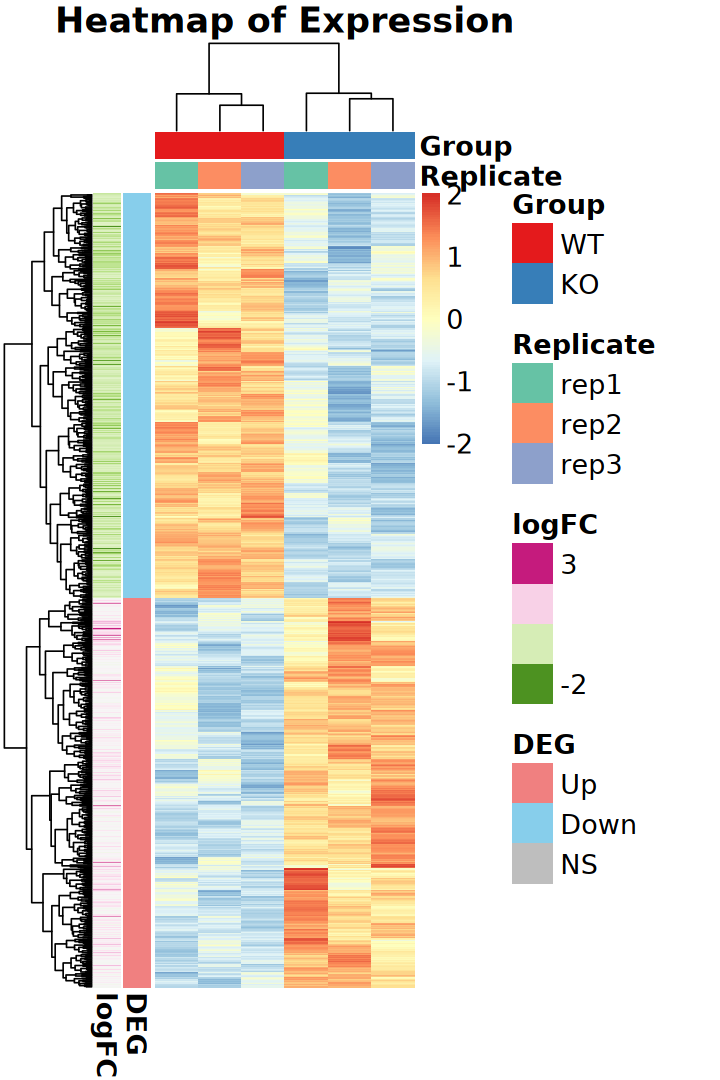

In [146]:
options(repr.plot.width = 6, repr.plot.height = 9)

pheatmap::pheatmap(
    heatmap_dat, scale = "row",
    annotation_row = ar, annotation_col = ac, 
    annotation_colors = anno_colors, 
    main = "Heatmap of Expression", fontsize = 16, 
    show_colnames = FALSE, show_rownames = FALSE)

In [147]:
lr <- degs_result |>
    rownames_to_column("gene_id") |>
    filter(gene_id %in% rownames(heatmap_dat)) |>
    arrange(factor(gene_id, levels = rownames(heatmap_dat))) |>
    pull(label) |>
    replace_na("")

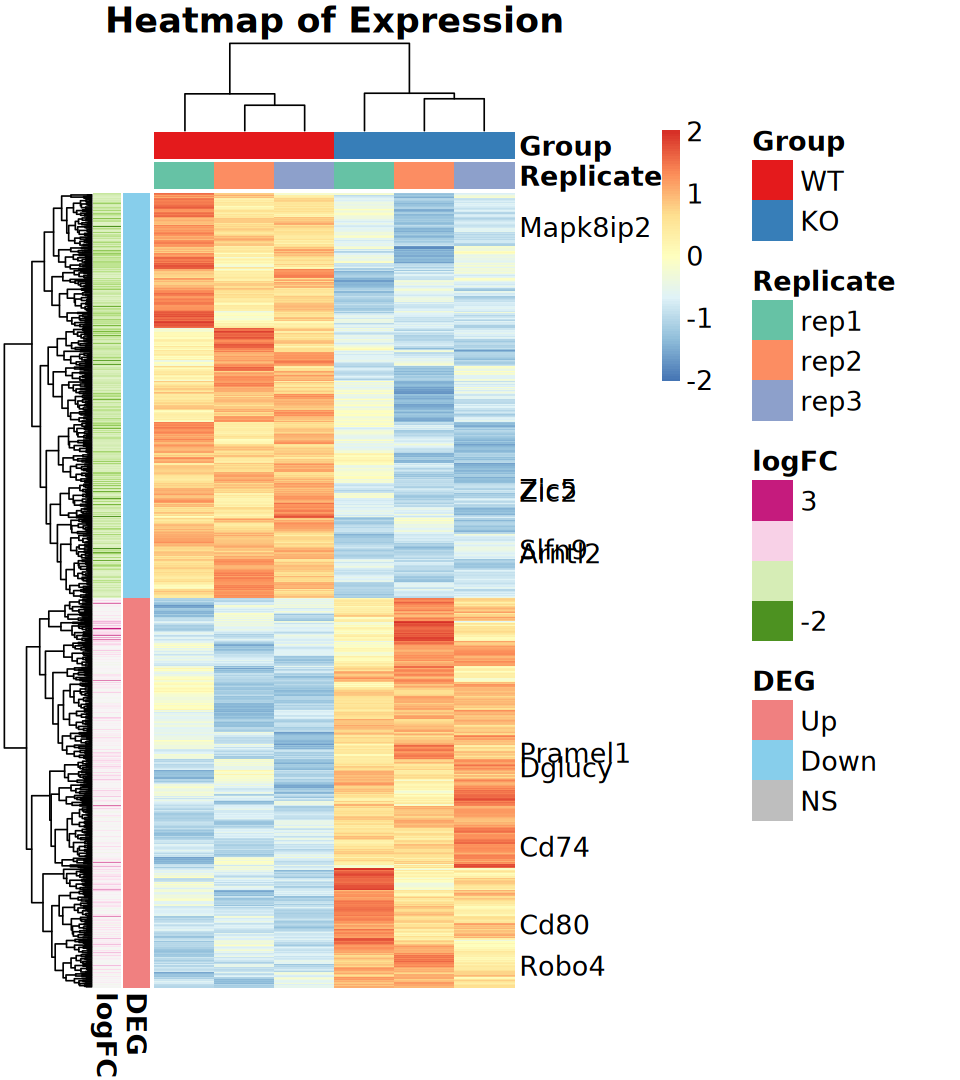

In [148]:
options(repr.plot.width = 8, repr.plot.height = 9)

pheatmap::pheatmap(
    heatmap_dat, scale = "row",
    annotation_row = ar, annotation_col = ac, 
    annotation_colors = anno_colors, labels_row = lr,
    main = "Heatmap of Expression", fontsize = 16, 
    show_colnames = FALSE, show_rownames = TRUE)

### ComplexHeatmap

In [149]:
# suppressPackageStartupMessages(library(circlize))
suppressPackageStartupMessages(library(ComplexHeatmap))

In [150]:
heatmap_dat <- degs_result |>
    filter(result %in% c("Up", "Down")) |>
    rownames() |>
    (\(idx) norm_mat[idx, ])()

In [151]:
heatmap_col <- circlize::colorRamp2(
    breaks = c(-2, 0, 2), 
    colors = brewer.pal(n = 11, name = "RdYlBu")[c(3,6,9)] |> rev())

group_colors <- setNames(
    scales::brewer_pal(palette = "Set1")(nlevels(dds$Group)),
    levels(dds$Group))
replicate_colors <- setNames(
    scales::brewer_pal(palette = "Set2")(nlevels(dds$Replicate)),
    levels(dds$Replicate))

deg_colors <- c(Up = "LightCoral", Down = "SkyBlue", NS = "grey")

In [152]:
ac <- colData(dds) |> as.data.frame() |>
    dplyr::select(Group, Replicate)

top_anno <- HeatmapAnnotation(
    df = ac, col = list(
        Group = group_colors, 
        Replicate = replicate_colors))

In [153]:
ar <- degs_result |> 
    dplyr::select(logFC, DEG = result) |>
    rownames_to_column("gene_id") |>
    filter(gene_id %in% rownames(heatmap_dat)) |>
    column_to_rownames("gene_id")

anno_colors <- list(
    DEG = deg_colors, 
    logFC = circlize::colorRamp2(
        breaks = c(-5, 0, 5),
        colors = rev(brewer.pal(n = 3, name = "PiYG"))))

left_anno <- rowAnnotation(
    df = ar, col = anno_colors, show_legend = FALSE)

In [154]:
right_anno <- rowAnnotation(
    foo = anno_mark(
        at = which(!is.na(degs_result$label)),
        labels = degs_result$symbol[which(!is.na(degs_result$label))],
        labels_gp = gpar(fontsize = 12)))

In [155]:
ar <- degs_result |> 
    dplyr::select(DEG = result, logFC)

ac <- colData(dds) |> as.data.frame() |>
    dplyr::select(Replicate, Group)

In [156]:
lg_heatmap <- Legend(
    title = "Expression (z-score)", col_fun = heatmap_col)
lg_group <- Legend(
    title = "Group", labels = levels(dds$Group))
lg_replicate <- Legend(
    title = "Replicate", labels = levels(dds$Replicate))
lg_logfc <- Legend(
    title = "logFC", col_fun = anno_colors$logFC)
lg_deg <- Legend(
    labels = levels(degs_result$result), title = "DEG", 
    legend_gp = gpar(fill = deg_colors))

combined_leg <- list(lg_heatmap, lg_group, lg_replicate) |>
    packLegend(direction = "vertical")

In [157]:
ht <- heatmap_dat |> t() |> scale() |> t() |>
    Heatmap(
        name = "Expression", col = heatmap_col,
        top_annotation = top_anno,
        left_annotation = left_anno, 
        right_annotation = right_anno,
        show_row_names = FALSE, show_column_names = FALSE)

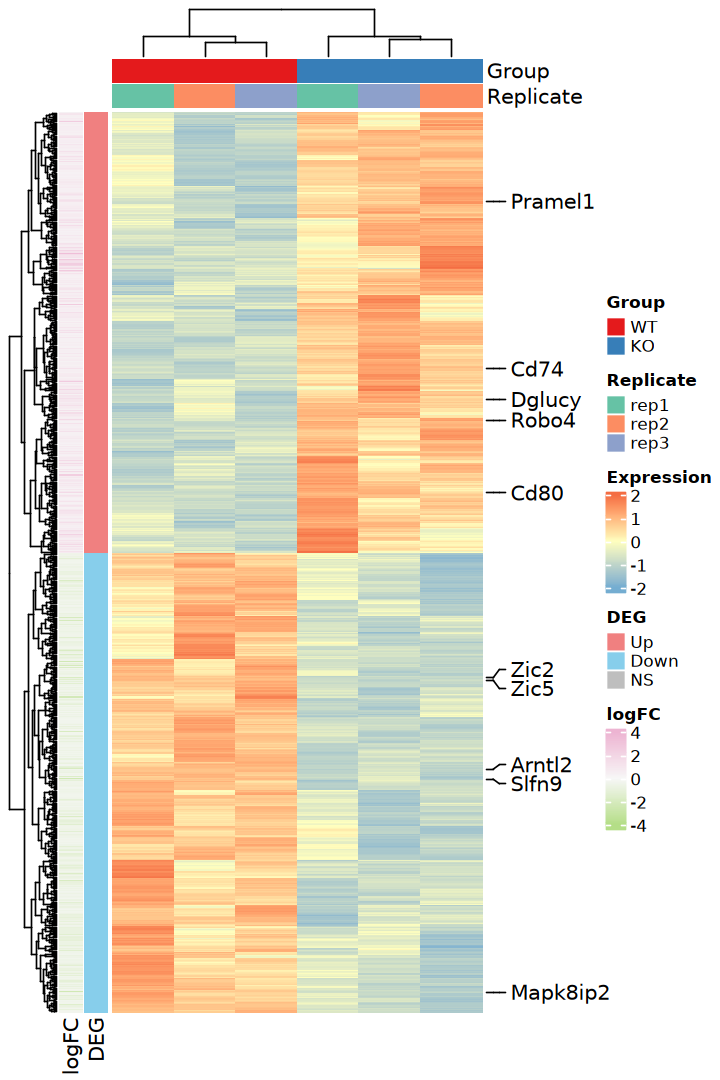

In [158]:
options(repr.plot.width = 6, repr.plot.height = 9)

draw(
    ht + combined_leg, merge_legend = TRUE,
    annotation_legend_list = list(lg_deg, lg_logfc), 
    legend_title_gp = gpar(fontsize = 12, fontface = "bold"),
    legend_labels_gp = gpar(fontsize = 10), 
    padding = unit(c(2, 2, 2, 5), "mm"))

# 6. Gene Function Analysis

## 1). ORA

In [159]:
suppressPackageStartupMessages(library(org.Mm.eg.db))
suppressPackageStartupMessages(library(clusterProfiler))

In [160]:
add_ENTREZID <- function(
    res, orgdb, fromType = "SYMBOL", toType = "ENTREZID", 
    ignoreVersion = FALSE) {
    
    gene_ids <- rownames(res)

    if(fromType == "ENSEMBL" & ignoreVersion) {
        gene_ids <- sub("\\..*$", "", gene_ids)
    }

    gene_map <- clusterProfiler::bitr(
        gene_ids, OrgDb = orgdb, drop = FALSE, 
        fromType = fromType, toType = toType)
    
    idx <- match(gene_ids, gene_map[[fromType]])

    for (col in toType) {
        res[[col]] <- gene_map[[col]][idx]
    }
    
    return(res)
}

In [161]:
deseq2_result <- add_ENTREZID(
    deseq2_result, org.Mm.eg.db, fromType = "ENSEMBL", 
    toType = c("SYMBOL", "ENTREZID"), ignoreVersion = TRUE)
edger_result <- add_ENTREZID(
    edger_result, org.Mm.eg.db, fromType = "ENSEMBL", 
    toType = c("SYMBOL", "ENTREZID"), ignoreVersion = TRUE)
limma_result <- add_ENTREZID(
    limma_result, org.Mm.eg.db, fromType = "ENSEMBL", 
    toType = c("SYMBOL", "ENTREZID"), ignoreVersion = TRUE)

'select()' returned 1:many mapping between keys and columns

Warning message in clusterProfiler::bitr(gene_ids, OrgDb = orgdb, drop = FALSE, :
"14.14% of input gene IDs are fail to map..."
'select()' returned 1:many mapping between keys and columns

Warning message in clusterProfiler::bitr(gene_ids, OrgDb = orgdb, drop = FALSE, :
"13.76% of input gene IDs are fail to map..."
'select()' returned 1:many mapping between keys and columns

Warning message in clusterProfiler::bitr(gene_ids, OrgDb = orgdb, drop = FALSE, :
"13.76% of input gene IDs are fail to map..."


In [162]:
extract_gene_lists <- function(
    results_map, gene_col = "SYMBOL", result_col = "result", 
    directions = c("Up", "Down")) {
        
    lapply(names(results_map), function(method) {
        lapply(directions, function(dir) {
            df <- results_map[[method]]
            df[[gene_col]][df[[result_col]] == dir]
        })
    }) |>
    unlist(recursive = FALSE) |>
    setNames(
        nm = as.vector(t(outer(
            names(results_map), directions, paste, sep = "-"))))
}

In [163]:
results_map <- list(
    DESeq2 = deseq2_result, 
    edgeR  = edger_result,
    limma  = limma_result)

genes_list <- extract_gene_lists(
    results_map, gene_col = "symbol", result_col = "result")

In [164]:
ego_compare <- compareCluster(
    geneCluster = genes_list, fun = enrichGO, 
    universe = unique(c(deseq2_result$SYMBOL, edger_result$SYMBOL)), 
    OrgDb = org.Mm.eg.db, ont = "ALL", 
    keyType = 'SYMBOL', pAdjustMethod = "BH",
    pvalueCutoff = 0.05, qvalueCutoff = 0.05, 
    minGSSize = 5, maxGSSize = 500, readable = TRUE)

In [165]:
ego_compare |> dplyr::select(-one_of("geneID")) |> head()

,Cluster,ONTOLOGY,ID,Description,GeneRatio,BgRatio,RichFactor,FoldEnrichment,zScore,pvalue,p.adjust,qvalue,Count
,<fct>,<chr>,<chr>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<int>
1,DESeq2-Down,CC,GO:0005874,microtubule,27/389,458/15004,0.05895197,2.273818,4.516821,6.451827e-05,0.03264624,0.03083294,27


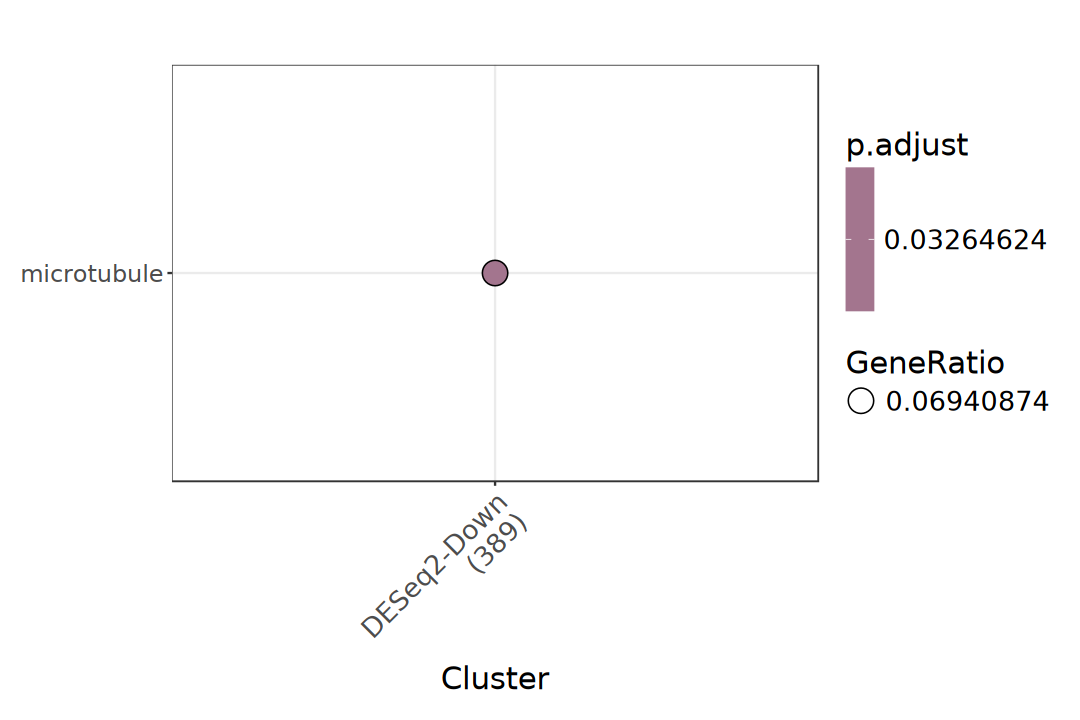

In [166]:
options(repr.plot.width = 9, repr.plot.height = 6)

dotplot(ego_compare, showCategory = 5, label_format = 50) + 
    theme_bw() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text.x = element_text(size = 16, angle = 45, hjust = 1), 
        axis.text.y = element_text(size = 14))

In [167]:
genes_list <- extract_gene_lists(
    results_map, gene_col = "ENTREZID", result_col = "result")

In [168]:
ekegg_compare <- compareCluster(
    geneCluster = genes_list, fun = enrichKEGG, 
    universe = unique(c(deseq2_result$ENTREZID, edger_result$ENTREZID)), 
    organism = "mmu", pAdjustMethod = "BH",
    pvalueCutoff = 0.01, qvalueCutoff = 0.05, 
    minGSSize = 10, maxGSSize = 500)

In [169]:
ekegg_compare |> dplyr::select(-one_of("geneID")) |> head()

,Cluster,category,subcategory,ID,Description,GeneRatio,BgRatio,RichFactor,FoldEnrichment,zScore,pvalue,p.adjust,qvalue,Count
,<fct>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<int>
1,DESeq2-Up,Human Diseases,Immune disease,mmu05322,Systemic lupus erythematosus,11/177,84/6649,0.13095238,4.919222,5.977713,1.196890e-05,3.315386e-03,3.315386e-03,11
2,edgeR-Up,Human Diseases,Immune disease,mmu05322,Systemic lupus erythematosus,11/121,84/6649,0.13095238,7.195887,7.779898,2.778011e-07,6.889467e-05,6.813437e-05,11
3,edgeR-Up,Organismal Systems,Immune system,mmu04613,Neutrophil extracellular trap formation,11/121,138/6649,0.07971014,4.380105,5.462533,3.759490e-05,4.661768e-03,4.610322e-03,11
4,limma-Up,Human Diseases,Immune disease,mmu05322,Systemic lupus erythematosus,10/107,84/6649,0.11904762,7.397641,7.546130,7.797401e-07,1.793402e-04,1.756467e-04,10
5,limma-Up,Organismal Systems,Immune system,mmu04613,Neutrophil extracellular trap formation,10/107,138/6649,0.07246377,4.502912,5.317740,6.776210e-05,7.792642e-03,7.632153e-03,10


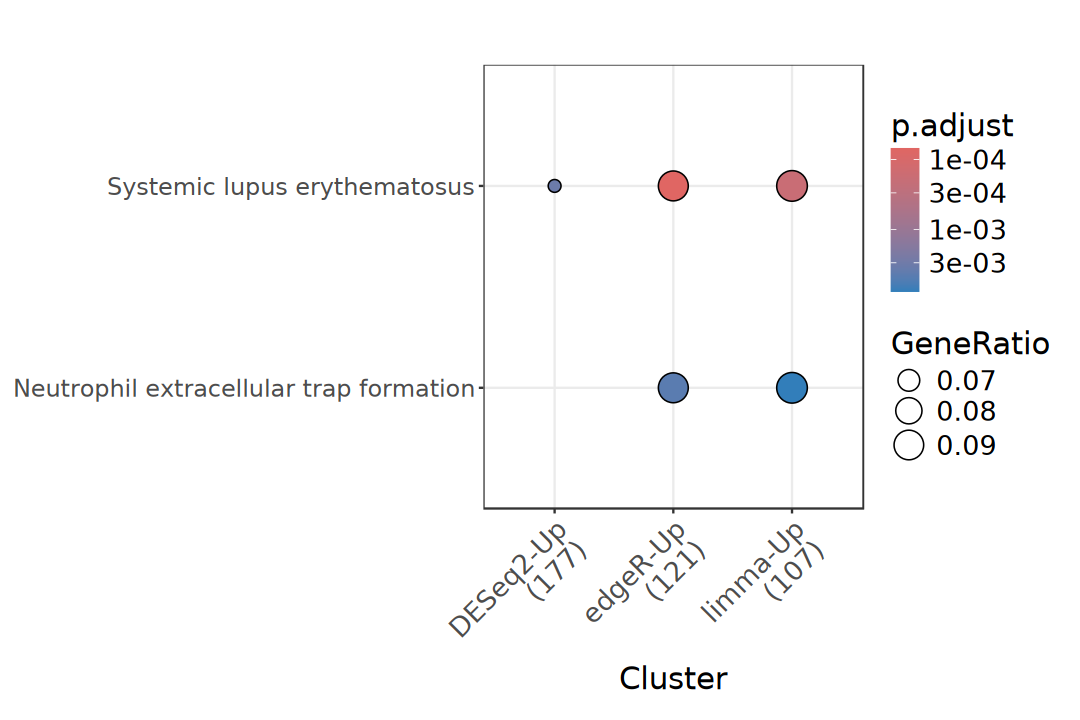

In [170]:
options(repr.plot.width = 9, repr.plot.height = 6)

dotplot(ekegg_compare, showCategory = 5, label_format = 50) + 
    theme_bw() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text.x = element_text(size = 16, angle = 45, hjust = 1), 
        axis.text.y = element_text(size = 14))

## 2). GSEA

> Gene Set Enrichment Analysis

# Reference

> 1. Law CW, Alhamdoosh M, Su S, Dong X, Tian L, Smyth GK, Ritchie ME (2018). “RNA-seq analysis is easy as 1-2-3 with limma, Glimma and edgeR.” F1000Research, 5, 1408. https://f1000research.com/articles/5-1408/v3. [RNA-seq analysis is easy as 1-2-3 with limma, Glimma and edgeR](https://www.bioconductor.org/packages/release/workflows/html/RNAseq123.html)
> 2. Law CW, Zeglinski K, Dong X, Alhamdoosh M, Smyth GK, Ritchie ME (2020). “A guide to creating design matrices for gene expression experiments.” F1000Research, 9, 1444. https://f1000research.com/articles/9-1444. [A guide to creating design matrices for gene expression experiments](https://www.bioconductor.org/packages/release/workflows/vignettes/RNAseq123/inst/doc/designmatrices.html)
> 2. Love MI, Anders S, Kim V, Huber W (2016). “RNA-Seq workflow: gene-level exploratory analysis and differential expression.” F1000Research. doi:10.12688/f1000research.7035.2. [RNA-seq workflow: gene-level exploratory analysis and differential expression](https://www.bioconductor.org/packages/release/workflows/html/rnaseqGene.html)
> 3. Chen Y, Lun ATL, Smyth GK (2016). “From reads to genes to pathways: differential expression analysis of RNA-Seq experiments using Rsubread and the edgeR quasi-likelihood pipeline.” F1000Research, 5, 1438. http://f1000research.com/articles/5-1438. [Gene-level RNA-seq differential expression and pathway analysis using Rsubread and the edgeR quasi-likelihood pipeline](https://www.bioconductor.org/packages/release/workflows/html/RnaSeqGeneEdgeRQL.html)